## Persiapan
### P.1 Pasang paket

In [3]:
import importlib, subprocess, sys

def pastikan_paket(pkg, modul=None):
    # Pasang hanya bila belum ada, supaya versi torch/transformers bawaan Kaggle tidak tertimpa.
    try:
        importlib.import_module(modul or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

for pkg, modul in [('vaderSentiment', 'vaderSentiment'), ('statsmodels', 'statsmodels'),
                   ('transformers', 'transformers'), ('nltk', 'nltk')]:
    pastikan_paket(pkg, modul)
print('Paket siap.')

Paket siap.


### P.2 Import, konfigurasi, dan fungsi bantu

In [4]:
import os, sys, re, html, glob, json, random, time, shutil, warnings, io, zipfile, urllib.request
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from scipy.stats import chi2_contingency, spearmanr, t as t_dist

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate, cross_val_predict)
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC, LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, cohen_kappa_score)

from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import nltk
for r in ['stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(r, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k): return x

# ---------------- Konfigurasi global ----------------
RANDOM_STATE = 42
random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)
os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)

SMOKE = os.environ.get('SMOKE_TEST') == '1'     # hanya untuk uji cepat; di Kaggle selalu False
N_BOOT = 200 if SMOKE else 2000                 # replikasi bootstrap untuk CI
N_BOOT_KOEF = 10 if SMOKE else 100              # bootstrap koefisien SVM (Tahap 3)
N_JOBS = -1                                     # semua core CPU

OUT = '/kaggle/working/hasil' if os.path.isdir('/kaggle/working') else 'hasil'
FIG, TAB = f'{OUT}/gambar', f'{OUT}/tabel'
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)

sns.set_style('whitegrid')
plt.rcParams.update({'figure.figsize': (12, 6), 'axes.titleweight': 'bold', 'savefig.dpi': 300})

MASKAPAI = ['United', 'US Airways', 'American', 'Southwest', 'Delta', 'Virgin America']
CT = "Can't Tell"

def simpan_gambar(nama):
    plt.tight_layout()
    plt.savefig(f'{FIG}/{nama}.png', dpi=300, bbox_inches='tight')
    plt.show()

def simpan_tabel(df, nama, index=True):
    df.to_csv(f'{TAB}/{nama}.csv', index=index)
    return df

RINGKASAN = {}          # angka kunci -> dicocokkan dengan naskah di bagian Penutup
def catat_angka(kunci, nilai):
    RINGKASAN[kunci] = nilai

print('Output disimpan di:', os.path.abspath(OUT))

Output disimpan di: /kaggle/working/hasil


### P.3 Pemeriksaan GPU

In [5]:
try:
    import torch
    N_GPU = torch.cuda.device_count()
    torch.manual_seed(RANDOM_STATE)
    if N_GPU:
        torch.cuda.manual_seed_all(RANDOM_STATE)
        torch.backends.cudnn.benchmark = True
except ImportError:
    torch, N_GPU = None, 0

DEVICE = 'cuda' if N_GPU else 'cpu'
print(f'Jumlah GPU terdeteksi: {N_GPU}')
for i in range(N_GPU):
    p = torch.cuda.get_device_properties(i)
    print(f'  cuda:{i}  {p.name}  {p.total_memory/1e9:.1f} GB')
if N_GPU < 2 and not SMOKE:
    print('PERINGATAN: kurang dari 2 GPU. Pilih Accelerator "GPU T4 x2" agar zero-shot memakai dua GPU.')

Jumlah GPU terdeteksi: 2
  cuda:0  Tesla T4  15.6 GB
  cuda:1  Tesla T4  15.6 GB


---
# TAHAP 1 — Persiapan Data

Setiap langkah yang membuang baris dicatat di `LOG` (jumlah sebelum, sesudah, terbuang). Tabel log disimpan di akhir Tahap 2 dan diperbarui di Penutup.

In [6]:
JALUR_TWEETS = ['/kaggle/input/datasets/crowdflower/twitter-airline-sentiment/Tweets.csv',
                '/kaggle/input/twitter-airline-sentiment/Tweets.csv']
kandidat = [p for p in JALUR_TWEETS if os.path.exists(p)] or glob.glob('/kaggle/input/**/Tweets.csv', recursive=True)
PATH = kandidat[0] if kandidat else 'Tweets.csv'
raw = pd.read_csv(PATH)
print('File :', PATH, '| dimensi:', raw.shape)

LOG = []
def catat(langkah, sebelum, sesudah, ket=''):
    LOG.append({'Langkah': langkah, 'Sebelum': sebelum, 'Sesudah': sesudah,
                'Terbuang': sebelum - sesudah, 'Keterangan': ket})
    print(f'{langkah:<55} {sebelum:>6} -> {sesudah:>6}  (terbuang {sebelum - sesudah})')

data = raw.copy()
# airline_sentiment_confidence adalah tingkat kesepakatan anotator, BUKAN intensitas emosi.
# Kolom dibuang di awal supaya tidak terpakai di tahap mana pun (Tahap 7).
data = data.drop(columns=['airline_sentiment_confidence', 'tweet_coord', 'airline_sentiment_gold',
                          'negativereason_gold', 'tweet_location', 'user_timezone'], errors='ignore')
catat('Data awal', len(data), len(data))

n0 = len(data)
data = data.drop_duplicates(subset='text', keep='first')
catat('Hapus tweet dengan teks identik', n0, len(data))
n0 = len(data)
data = data.drop_duplicates(subset='tweet_id', keep='first')   # pengaman: tweet_id harus unik
catat('Hapus tweet_id ganda (sisa)', n0, len(data))

n0 = len(data)
data = data[~data['text'].astype(str).str.lstrip().str.startswith('RT @')]
catat('Hapus retweet (teks diawali "RT @")', n0, len(data))
data = data.reset_index(drop=True)

# Tanggal LOKAL: 10 karakter pertama '2015-02-24 11:35:52 -0800', tanpa konversi zona waktu
data['tanggal'] = data['tweet_created'].astype(str).str[:10]
data['waktu_lokal'] = pd.to_datetime(data['tweet_created'].astype(str).str[:19])
print('\nPeriode:', data['tanggal'].min(), 's/d', data['tanggal'].max(),
      '|', data['tanggal'].nunique(), 'hari')

File : /kaggle/input/datasets/crowdflower/twitter-airline-sentiment/Tweets.csv | dimensi: (14640, 15)
Data awal                                                14640 ->  14640  (terbuang 0)
Hapus tweet dengan teks identik                          14640 ->  14427  (terbuang 213)
Hapus tweet_id ganda (sisa)                              14427 ->  14427  (terbuang 0)
Hapus retweet (teks diawali "RT @")                      14427 ->  14424  (terbuang 3)

Periode: 2015-02-16 s/d 2015-02-24 | 9 hari


### 1.0 Pemeriksaan label maskapai "Delta"

Pada analisis kesalahan, seluruh tweet berlabel "Delta" ternyata menyebut **@JetBlue**, bukan @Delta. Sel ini memeriksanya di data penuh. Bila ≥ 90% tweet "Delta" menyebut @JetBlue, label diganti menjadi **JetBlue** di seluruh analisis, dan Tahap 8 memakai kode BTS **B6** (bukan DL).

In [7]:
teks_delta = data.loc[data['airline'] == 'Delta', 'text'].astype(str)
pct_jetblue = teks_delta.str.contains('@jetblue', case=False).mean() * 100
pct_delta = teks_delta.str.contains('@delta', case=False).mean() * 100
print(f'Tweet berlabel "Delta": {len(teks_delta)} | menyebut @JetBlue: {pct_jetblue:.1f}% | menyebut @Delta: {pct_delta:.1f}%')

GANTI_DELTA_KE_JETBLUE = pct_jetblue >= 90
if GANTI_DELTA_KE_JETBLUE:
    data['airline'] = data['airline'].replace('Delta', 'JetBlue')
    MASKAPAI = ['JetBlue' if m == 'Delta' else m for m in MASKAPAI]
    print('Label "Delta" diganti menjadi "JetBlue" di seluruh analisis.')
else:
    print('Label "Delta" dipertahankan.')
catat_angka('Tahap1_pct_Delta_menyebut_JetBlue', round(pct_jetblue, 1))
catat_angka('Tahap1_label_Delta_diganti_JetBlue', bool(GANTI_DELTA_KE_JETBLUE))

Tweet berlabel "Delta": 2208 | menyebut @JetBlue: 99.8% | menyebut @Delta: 0.3%
Label "Delta" diganti menjadi "JetBlue" di seluruh analisis.


In [8]:
# Rincian tweet berlabel "Delta" yang TIDAK menyebut @JetBlue (reviewer ronde 2: perlakuannya harus jelas)
# teks_delta berasal dari sel di atas dan berisi hanya tweet yang semula berlabel "Delta".
lain = teks_delta[~teks_delta.str.contains('@jetblue', case=False)]
print(f'Tweet berlabel "Delta" tanpa @JetBlue: {len(lain)} dari {len(teks_delta)} ({len(lain) / max(len(teks_delta), 1) * 100:.2f}%)')
print('Perlakuan: ikut direkode ke JetBlue bersama seluruh tweet berlabel "Delta" (aturan berbasis kolom airline, bukan isi teks).')
print('Tidak ada tweet yang dibuang karena hal ini; efeknya pada hasil dianggap dapat diabaikan.')
catat_angka('Tahap1_Delta_tanpa_JetBlue_n', len(lain))

Tweet berlabel "Delta" tanpa @JetBlue: 4 dari 2208 (0.18%)
Perlakuan: ikut direkode ke JetBlue bersama seluruh tweet berlabel "Delta" (aturan berbasis kolom airline, bukan isi teks).
Tidak ada tweet yang dibuang karena hal ini; efeknya pada hasil dianggap dapat diabaikan.


### 1.1 Sepuluh pengguna paling aktif

In [9]:
top_user = (data['name'].value_counts().head(10)
            .rename_axis('Pengguna').reset_index(name='Jumlah Tweet'))
top_user['Pangsa (%)'] = (top_user['Jumlah Tweet'] / len(data) * 100).round(2)
top_user['Maskapai yang disebut'] = [', '.join(sorted(data.loc[data['name'] == u, 'airline'].unique()))
                                     for u in top_user['Pengguna']]
display(simpan_tabel(top_user, 't1_top10_pengguna', index=False))
catat_angka('Tahap1_tweet_pengguna_teraktif', int(top_user['Jumlah Tweet'].iloc[0]))

,Pengguna,Jumlah Tweet,Pangsa (%),Maskapai yang disebut
0,JetBlueNews,63,0.44,"JetBlue, Virgin America"
1,kbosspotter,32,0.22,JetBlue
2,_mhertz,29,0.20,"American, United"
3,otisday,28,0.19,American
4,throthra,27,0.19,United
5,rossj987,23,0.16,US Airways
6,weezerandburnie,22,0.15,"American, US Airways"
7,GREATNESSEOA,22,0.15,"American, US Airways"
8,scoobydoo9749,21,0.15,Southwest
9,MeeestarCoke,20,0.14,"American, US Airways"


### 1.2 Versi 1 tweet per pengguna per maskapai (`df_user1`)
Tweet pertama secara kronologis dipertahankan. Dipakai di Tahap 6 untuk menguji apakah hasil H1 bertahan ketika pengguna yang sangat aktif tidak lagi mendominasi.

In [10]:
df_user1 = (data.sort_values('waktu_lokal')
                .drop_duplicates(subset=['name', 'airline'], keep='first')
                .sort_index())
catat('Versi df_user1 (1 tweet/pengguna/maskapai)', len(data), len(df_user1),
      'data turunan untuk uji robustness, data utama tidak berubah')

Versi df_user1 (1 tweet/pengguna/maskapai)               14424 ->   7910  (terbuang 6514)


In [11]:
# Dokumentasi aturan (reviewer ronde 2): tweet mana yang dipertahankan per pengguna
print('Aturan df_user1: untuk setiap pasangan (pengguna, maskapai), tweet PERTAMA secara kronologis (waktu_lokal) dipertahankan;')
print('tweet berikutnya dari pengguna yang sama ke maskapai yang sama dibuang. Pengguna yang menulis ke maskapai berbeda tetap ikut.')
print(f'Jumlah tweet df_user1: {len(df_user1)} dari {len(data)} | pengguna unik: {data["name"].nunique()}')

Aturan df_user1: untuk setiap pasangan (pengguna, maskapai), tweet PERTAMA secara kronologis (waktu_lokal) dipertahankan;
tweet berikutnya dari pengguna yang sama ke maskapai yang sama dibuang. Pengguna yang menulis ke maskapai berbeda tetap ikut.
Jumlah tweet df_user1: 7910 dari 14424 | pengguna unik: 7692


### 1.3 Jumlah tweet per hari per maskapai dan `common_days`

airline,United,US Airways,American,Southwest,JetBlue,Virgin America,Total
tanggal,,,,,,,
2015-02-16,2,0,0,0,2,0,4
2015-02-17,394,308,0,383,260,54,1399
2015-02-18,402,315,1,290,266,60,1334
2015-02-19,425,278,1,314,280,69,1367
2015-02-20,522,333,1,317,249,70,1492
2015-02-21,505,360,1,370,242,77,1555
2015-02-22,699,648,981,275,408,53,3064
2015-02-23,641,487,1130,276,388,91,3013
2015-02-24,215,177,479,183,113,29,1196


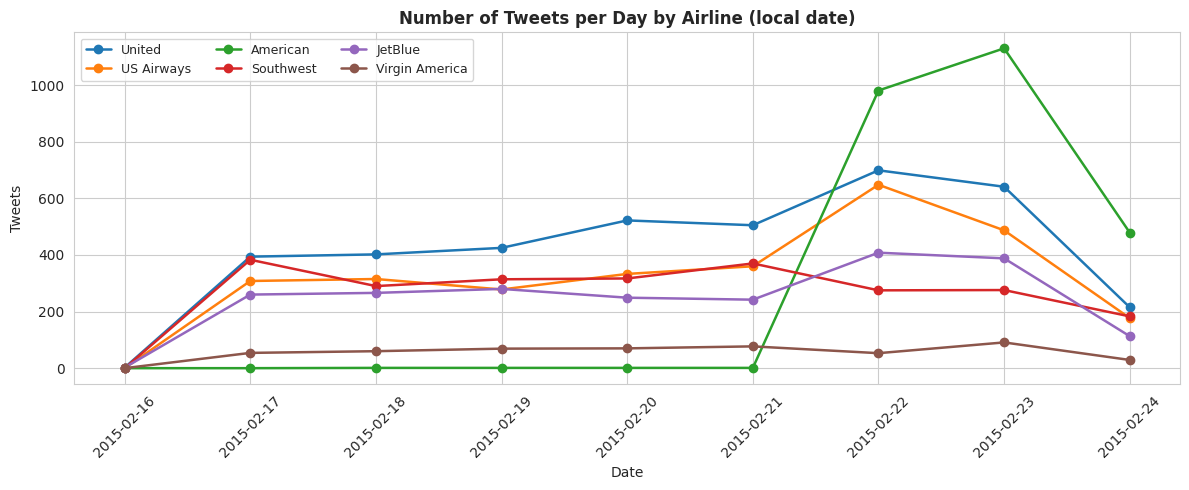

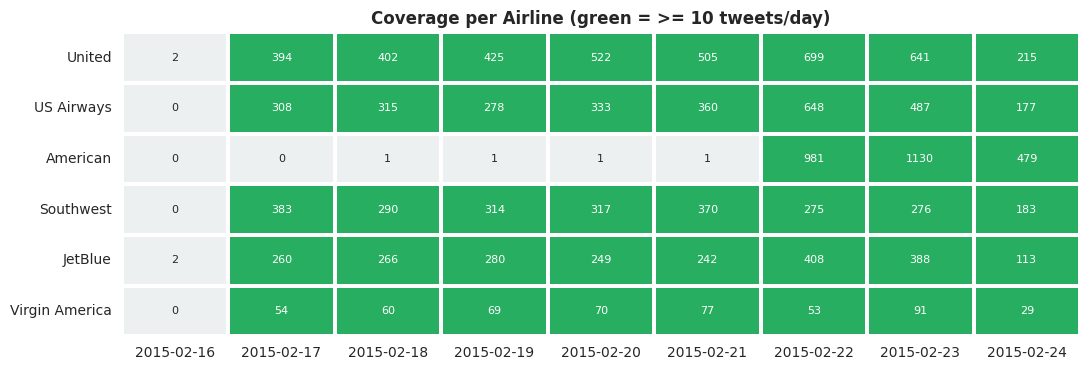

common_days (>= 10 tweet): ['2015-02-22', '2015-02-23', '2015-02-24']  -> 3 hari
pembanding (>= 1 tweet)          : ['2015-02-18', '2015-02-19', '2015-02-20', '2015-02-21', '2015-02-22', '2015-02-23', '2015-02-24']


In [12]:
harian = pd.crosstab(data['tanggal'], data['airline']).reindex(columns=MASKAPAI, fill_value=0)
harian_tot = harian.copy(); harian_tot['Total'] = harian.sum(axis=1)
display(simpan_tabel(harian_tot, 't1_tweet_per_hari_maskapai'))

fig, ax = plt.subplots(figsize=(12, 5))
for m in MASKAPAI:
    ax.plot(pd.to_datetime(harian.index), harian[m], marker='o', linewidth=1.8, label=m)
ax.set_title('Number of Tweets per Day by Airline (local date)')
ax.set_xlabel('Date'); ax.set_ylabel('Tweets'); ax.legend(ncol=3, fontsize=9)
ax.tick_params(axis='x', rotation=45)
simpan_gambar('g1_tweet_per_hari_maskapai')

# Hari dianggap "dimiliki" maskapai bila memuat >= MIN_TWEET_HARI tweet.
# Ambang 10 dipakai karena American hanya punya 1 tweet/hari pada 18-21 Feb; ambang 1 akan
# menganggap hari-hari itu setara padahal isinya hampir kosong.
MIN_TWEET_HARI = 10
aktif = harian >= MIN_TWEET_HARI
common_days = sorted(aktif.index[aktif.all(axis=1)])
common_days_ambang1 = sorted(harian.index[(harian >= 1).all(axis=1)])

plt.figure(figsize=(11, 3.8))
sns.heatmap(aktif.T.astype(int), cmap=['#ecf0f1', '#27ae60'], cbar=False, linewidths=1.5, linecolor='white',
            annot=harian.T.values, fmt='d', annot_kws={'size': 8})
plt.title(f'Coverage per Airline (green = >= {MIN_TWEET_HARI} tweets/day)'); plt.xlabel(''); plt.ylabel('')
simpan_gambar('g1_cakupan_hari_maskapai')

print(f'common_days (>= {MIN_TWEET_HARI} tweet): {common_days}  -> {len(common_days)} hari')
print(f'pembanding (>= 1 tweet)          : {common_days_ambang1}')
catat_angka('Tahap1_common_days', ', '.join(common_days))
catat_angka('Tahap1_n_setelah_dedup_RT', len(data))

---
# TAHAP 2 — Preprocessing

| No | Langkah | Keterangan |
|----|---------|------------|
| 1 | HTML unescape | `&amp;` → `&` agar tidak menjadi token "amp" |
| 2 | Hapus mention | `@united` dibuang agar model tidak belajar nama maskapai |
| 3 | Hapus URL | |
| 4 | Hapus simbol `#` | kata hashtag dipertahankan |
| 5 | Case folding | |
| 6 | **Kontraksi → `not`** (BARU) | `don't`, `can't`, `won't`, `isn't`, `dont`, `cant`, ... menjadi `not` **sebelum** non-huruf dibuang |
| 7 | Hapus non-huruf | |
| 8 | Stopword + filter panjang ≤ 2 | **kata negasi dikecualikan** dari keduanya |
| 9 | Lemmatization (WordNet, pos=v) | |

Kolom `clean` mempertahankan negasi (dipakai model utama). Kolom `clean_noneg` membuang negasi, hanya untuk ablasi di Tahap 3.

In [13]:
# Daftar negasi ditulis eksplisit (bukan diambil dari pustaka)
NEGASI = {'no', 'not', 'nor', 'never', 'none', 'nobody', 'nothing', 'neither', 'nowhere', 'cannot'}

# Bentuk kontraksi tanpa apostrof yang lazim di Twitter
KONTRAKSI_TANPA_APOSTROF = {'dont', 'didnt', 'doesnt', 'isnt', 'wasnt', 'werent', 'arent', 'couldnt',
                            'wouldnt', 'shouldnt', 'hasnt', 'havent', 'hadnt', 'cant', 'wont', 'aint',
                            'mustnt', 'neednt'}
KONTRAKSI_RE = re.compile(r"\b\w+n['’`]t\b")      # don't, can't, won't, isn't, didn’t, ...

STOP_DASAR = set(stopwords.words('english'))
STOP = STOP_DASAR - NEGASI
_lem = WordNetLemmatizer()

def preprocess(tweet, pakai_negasi=True):
    t = html.unescape(str(tweet))                    # 1
    t = re.sub(r'@\w+', ' ', t)                      # 2
    t = re.sub(r'http\S+|www\.\S+', ' ', t)          # 3
    t = t.replace('#', ' ')                          # 4
    t = t.lower()                                    # 5
    t = KONTRAKSI_RE.sub(' not ', t)                 # 6 kontraksi -> not (sebelum non-huruf dibuang)
    t = re.sub(r'[^a-z\s]', ' ', t)                  # 7
    hasil = []
    for w in t.split():
        if w in KONTRAKSI_TANPA_APOSTROF:            # 6b dont/cant/wont -> not
            w = 'not'
        if w in NEGASI:                              # 8 negasi lolos dari stopword & filter panjang
            if pakai_negasi:
                hasil.append(w)
            continue
        if w in STOP or len(w) <= 2:                 # 8
            continue
        hasil.append(_lem.lemmatize(w, pos='v'))     # 9
    return ' '.join(hasil)

# ---------------- Uji dengan contoh kalimat ----------------
contoh = ["@united I don't like this, no thanks. Not good at all!",
          "@AmericanAir Can't believe it. Won't fly with you again, never!",
          "@SouthwestAir dont care, cant wait, wont stop &amp; isn’t fun",
          "@JetBlue Flight was not on time and there was no update",
          "@delta Neither the crew nor the app helped. Nothing works"]
uji = pd.DataFrame({'Asli': contoh,
                    'clean': [preprocess(s) for s in contoh],
                    'clean_noneg': [preprocess(s, False) for s in contoh]})
display(simpan_tabel(uji, 't2_uji_preprocessing', index=False))

tok0 = uji.loc[0, 'clean'].split()
assert 'no' in tok0 and 'not' in tok0, 'no/not hilang dari clean!'
assert all(not (set(s.split()) & NEGASI) for s in uji['clean_noneg']), 'negasi masih ada di clean_noneg!'
assert 'amp' not in uji.loc[2, 'clean'].split()
print('Uji lolos: "no" dan "not" tetap muncul di clean, dan hilang di clean_noneg.')

,Asli,clean,clean_noneg
0,"@united I don't like this, no thanks. Not good...",not like no thank not good,like thank good
1,@AmericanAir Can't believe it. Won't fly with ...,not believe not fly never,believe fly
2,"@SouthwestAir dont care, cant wait, wont stop ...",not care not wait not stop not fun,care wait stop fun
3,@JetBlue Flight was not on time and there was ...,flight not time no update,flight time update
4,@delta Neither the crew nor the app helped. No...,neither crew nor app help nothing work,crew app help work


Uji lolos: "no" dan "not" tetap muncul di clean, dan hilang di clean_noneg.


In [14]:
data['clean'] = data['text'].apply(preprocess)
data['clean_noneg'] = data['text'].apply(lambda s: preprocess(s, pakai_negasi=False))

n0 = len(data)
data = data[data['clean'].str.strip() != ''].reset_index(drop=True)
catat('Hapus tweet kosong setelah preprocessing', n0, len(data))
df_user1 = df_user1[df_user1['tweet_id'].isin(data['tweet_id'])].copy()

frek_neg = pd.Series(' '.join(data['clean']).split()).value_counts()
print('\nFrekuensi token negasi di kolom clean:')
print(frek_neg.reindex(sorted(NEGASI)).fillna(0).astype(int).to_string())
print('\nTweet clean_noneg yang kosong (tetap dipakai, TF-IDF menganggapnya vektor nol):',
      (data['clean_noneg'].str.strip() == '').sum())

simpan_tabel(pd.DataFrame(LOG), 't0_log_data', index=False)
catat_angka('Tahap2_n_data_final', len(data))

Hapus tweet kosong setelah preprocessing                 14424 ->  14388  (terbuang 36)

Frekuensi token negasi di kolom clean:
cannot       51
neither       7
never       319
no         1484
nobody       16
none         24
nor          10
not        3816
nothing     156
nowhere       4

Tweet clean_noneg yang kosong (tetap dipakai, TF-IDF menganggapnya vektor nol): 7


---
# TAHAP 3 — Model Sentimen dan Evaluasi

TF-IDF kini berada **di dalam `Pipeline`** bersama SVM, sehingga di setiap lipatan CV vektorizer hanya di-*fit* pada data latih lipatan itu. Versi lama memanggil `tfidf.fit_transform` sebelum `GridSearchCV`, sehingga kosakata dan IDF ikut melihat lipatan validasi.

In [15]:
# VADER dihitung pada TEKS ASLI (VADER memakai tanda baca, huruf kapital, emoji). Dipakai di Tahap 3 dan 7.
vader = SentimentIntensityAnalyzer()
data['vader_compound'] = [vader.polarity_scores(str(t))['compound'] for t in tqdm(data['text'], desc='VADER')]

data_model = data[data['airline_sentiment'] != 'neutral'].reset_index(drop=True)
le = LabelEncoder().fit(data_model['airline_sentiment'])       # negative=0, positive=1
data_model['label'] = le.transform(data_model['airline_sentiment'])
y_all = data_model['label'].values
KODE_NEG, KODE_POS = le.transform(['negative', 'positive'])

idx_tr, idx_te = train_test_split(data_model.index.values, test_size=0.2,
                                  random_state=RANDOM_STATE, stratify=y_all)
X_tr, X_te = data_model.loc[idx_tr, 'clean'].values, data_model.loc[idx_te, 'clean'].values
y_tr, y_te = y_all[idx_tr], y_all[idx_te]

print('Pemetaan label :', dict(zip(le.classes_, le.transform(le.classes_))))
print(f'Data pemodelan : {len(data_model)} | latih {len(idx_tr)} | uji {len(idx_te)}')
print('Distribusi     :', data_model['airline_sentiment'].value_counts().to_dict())
catat_angka('Tahap3_n_latih', len(idx_tr)); catat_angka('Tahap3_n_uji', len(idx_te))

VADER:   0%|          | 0/14388 [00:00<?, ?it/s]

Pemetaan label : {'negative': np.int64(0), 'positive': np.int64(1)}
Data pemodelan : 11358 | latih 9086 | uji 2272
Distribusi     : {'negative': 9071, 'positive': 2287}


### 3.1 SVM dalam Pipeline + GridSearchCV
Grid C kernel linear: **0,1; 1; 10** (naskah revisi 1 tertulis "0, 1, and 10", perbaiki di naskah).

**Aturan pemilihan model:** kernel linear dipilih bila skor CV-nya masih dalam 1 *standard error* dari konfigurasi terbaik (SE = SD antar-lipatan / √5). Alasannya, model linear lebih sederhana dan koefisiennya bisa dibaca langsung sebagai kata penanda (3.7), sehingga model yang diinterpretasi sama dengan model yang dipakai untuk prediksi. Set `PILIH_LINEAR_1SE = False` untuk kembali ke skor tertinggi murni.

In [16]:
TFIDF_PARAMS = dict(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
def pipa(clf):
    return Pipeline([('tfidf', TfidfVectorizer(**TFIDF_PARAMS)), ('clf', clf)])

CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_svm = [{'clf__kernel': ['linear'], 'clf__C': [0.1, 1, 10]},
             {'clf__kernel': ['rbf'], 'clf__C': [1, 10, 100], 'clf__gamma': ['scale', 0.1, 1]}]
PILIH_LINEAR_1SE = True

def pilih_linear_1se(cvr):
    r = pd.DataFrame(cvr)
    i_best = r['mean_test_score'].idxmax()
    batas = r.loc[i_best, 'mean_test_score'] - r.loc[i_best, 'std_test_score'] / np.sqrt(CV5.get_n_splits())
    kand = r[r['mean_test_score'] >= batas].assign(lin=lambda d: d['param_clf__kernel'] == 'linear')
    return int(kand.sort_values(['lin', 'mean_test_score'], ascending=[False, False]).index[0])

REFIT = pilih_linear_1se if PILIH_LINEAR_1SE else True
grid_svm = GridSearchCV(pipa(SVC(class_weight='balanced', random_state=RANDOM_STATE)), param_svm,
                        cv=CV5, scoring='f1_macro', n_jobs=N_JOBS, verbose=1, refit=REFIT)
t0 = time.time(); grid_svm.fit(X_tr, y_tr)
skor_cv_terpilih = grid_svm.cv_results_['mean_test_score'][grid_svm.best_index_]
i_top = int(np.argmax(grid_svm.cv_results_['mean_test_score']))
print('Skor tertinggi murni :', grid_svm.cv_results_['params'][i_top],
      f"F1 = {grid_svm.cv_results_['mean_test_score'][i_top]:.4f}")
svm_best = grid_svm.best_estimator_
best_svm = {k.replace('clf__', ''): v for k, v in grid_svm.best_params_.items()}

cvres = pd.DataFrame(grid_svm.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
display(simpan_tabel(cvres.sort_values('rank_test_score'), 't3_grid_svm', index=False))
print(f'Parameter terpilih    : {best_svm} | F1-macro CV = {skor_cv_terpilih:.4f} | {time.time()-t0:.0f} dtk')
print('Jumlah fitur TF-IDF (fit pada seluruh data latih):', len(svm_best.named_steps['tfidf'].vocabulary_))
catat_angka('Tahap3_SVM_param_terbaik', str(best_svm))
catat_angka('Tahap3_SVM_F1_CV', round(skor_cv_terpilih, 4))
catat_angka('Tahap3_jumlah_fitur', len(svm_best.named_steps['tfidf'].vocabulary_))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Skor tertinggi murni : {'clf__C': 1, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'} F1 = 0.8666


,params,mean_test_score,std_test_score,rank_test_score
4,"{'clf__C': 1, 'clf__gamma': 0.1, 'clf__kernel'...",0.866569,0.014007,1
3,"{'clf__C': 1, 'clf__gamma': 'scale', 'clf__ker...",0.865598,0.012089,2
1,"{'clf__C': 1, 'clf__kernel': 'linear'}",0.865433,0.014831,3
5,"{'clf__C': 1, 'clf__gamma': 1, 'clf__kernel': ...",0.865294,0.011875,4
7,"{'clf__C': 10, 'clf__gamma': 0.1, 'clf__kernel...",0.865280,0.013822,5
0,"{'clf__C': 0.1, 'clf__kernel': 'linear'}",0.862865,0.012598,6
6,"{'clf__C': 10, 'clf__gamma': 'scale', 'clf__ke...",0.859437,0.014363,7
8,"{'clf__C': 10, 'clf__gamma': 1, 'clf__kernel':...",0.859284,0.014264,8
11,"{'clf__C': 100, 'clf__gamma': 1, 'clf__kernel'...",0.858820,0.013986,9
9,"{'clf__C': 100, 'clf__gamma': 'scale', 'clf__k...",0.858756,0.013984,10


Parameter terpilih    : {'C': 1, 'kernel': 'linear'} | F1-macro CV = 0.8654 | 111 dtk
Jumlah fitur TF-IDF (fit pada seluruh data latih): 11012


### 3.2 Model pembanding: Majority, Naive Bayes, Logistic Regression, VADER
NB dan LR di-*tune* dengan CV yang sama supaya pembandingan adil. VADER tidak dilatih: `compound ≥ 0,05` → positif, selain itu negatif.

NB terbaik: {'clf__alpha': 0.1} | LR terbaik: {'clf__C': 10}

Laporan klasifikasi SVM (data uji):
              precision    recall  f1-score   support

    negative     0.9555    0.9344    0.9448      1815
    positive     0.7606    0.8271    0.7925       457

    accuracy                         0.9129      2272
   macro avg     0.8580    0.8808    0.8686      2272
weighted avg     0.9163    0.9129    0.9142      2272



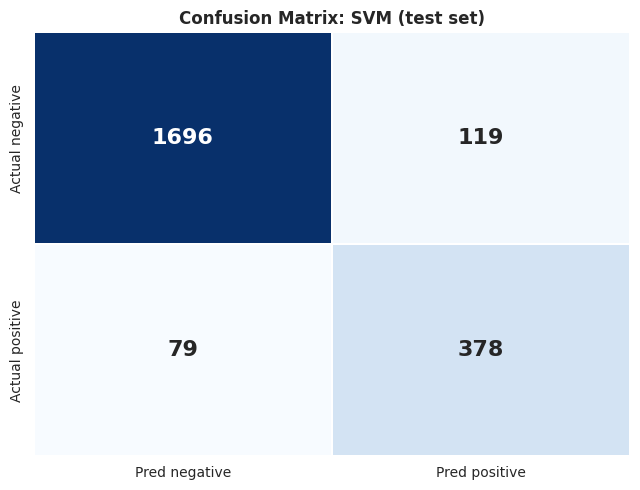

In [17]:
grid_nb = GridSearchCV(pipa(MultinomialNB()), {'clf__alpha': [0.1, 0.5, 1.0]},
                       cv=CV5, scoring='f1_macro', n_jobs=N_JOBS).fit(X_tr, y_tr)
grid_lr = GridSearchCV(pipa(LogisticRegression(class_weight='balanced', max_iter=3000,
                                               random_state=RANDOM_STATE)),
                       {'clf__C': [0.1, 1, 10]}, cv=CV5, scoring='f1_macro', n_jobs=N_JOBS).fit(X_tr, y_tr)
majority = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)

VADER_AMBANG = 0.05
vader_te = data_model.loc[idx_te, 'vader_compound'].values
PRED = {
    'SVM': svm_best.predict(X_te),
    'Majority': majority.predict(X_te),
    'Naive Bayes': grid_nb.predict(X_te),
    'Logistic Regression': grid_lr.predict(X_te),
    'VADER (tanpa pelatihan)': np.where(vader_te >= VADER_AMBANG, KODE_POS, KODE_NEG),
}
print('NB terbaik:', grid_nb.best_params_, '| LR terbaik:', grid_lr.best_params_)

y_pred = PRED['SVM']
print('\nLaporan klasifikasi SVM (data uji):')
print(classification_report(y_te, y_pred, target_names=le.classes_, digits=4))

cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=1.2,
            xticklabels=[f'Pred {c}' for c in le.classes_], yticklabels=[f'Actual {c}' for c in le.classes_],
            annot_kws={'size': 16, 'weight': 'bold'})
plt.title('Confusion Matrix: SVM (test set)')
simpan_gambar('g3_confusion_svm')

### 3.3 Bootstrap 95% CI (akurasi, macro F1) dan uji McNemar

In [18]:
def macro_f1_np(yt, yp, kelas):
    f = []
    for c in kelas:
        tp = np.sum((yp == c) & (yt == c)); fp = np.sum((yp == c) & (yt != c)); fn = np.sum((yp != c) & (yt == c))
        d = 2 * tp + fp + fn
        f.append(2 * tp / d if d else 0.0)
    return float(np.mean(f))

def bootstrap_ci(yt, pred_dict, B=N_BOOT, seed=RANDOM_STATE, acuan='SVM'):
    rng = np.random.default_rng(seed)
    kelas = np.unique(yt); n = len(yt)
    idx = rng.integers(0, n, size=(B, n))
    sampel = {m: {'acc': np.empty(B), 'f1': np.empty(B)} for m in pred_dict}
    for b in range(B):
        ix = idx[b]; yb = yt[ix]
        for m, p in pred_dict.items():
            pb = p[ix]
            sampel[m]['acc'][b] = np.mean(pb == yb)
            sampel[m]['f1'][b] = macro_f1_np(yb, pb, kelas)
    baris = []
    for m, p in pred_dict.items():
        a, f = sampel[m]['acc'], sampel[m]['f1']
        r = {'Model': m,
             'Akurasi': accuracy_score(yt, p), 'Akurasi CI low': np.percentile(a, 2.5), 'Akurasi CI high': np.percentile(a, 97.5),
             'Macro F1': f1_score(yt, p, average='macro', zero_division=0),
             'F1 CI low': np.percentile(f, 2.5), 'F1 CI high': np.percentile(f, 97.5)}
        if acuan in pred_dict and m != acuan:
            d = sampel[acuan]['f1'] - f
            r['Selisih F1 (acuan - model)'] = np.mean(d)
            r['Selisih CI low'] = np.percentile(d, 2.5); r['Selisih CI high'] = np.percentile(d, 97.5)
        baris.append(r)
    return pd.DataFrame(baris).set_index('Model').round(4)

tabel_ci = bootstrap_ci(y_te, PRED)
display(simpan_tabel(tabel_ci, 't3_bootstrap_ci_model'))

def uji_mcnemar(yt, pa, pb):
    ca, cb = pa == yt, pb == yt
    tab = np.array([[np.sum(ca & cb), np.sum(ca & ~cb)], [np.sum(~ca & cb), np.sum(~ca & ~cb)]])
    disk = tab[0, 1] + tab[1, 0]
    r = mcnemar(tab, exact=bool(disk < 25), correction=True)
    return tab, r.statistic, r.pvalue

baris = []
for m in PRED:
    if m == 'SVM': continue
    tab, stat, p = uji_mcnemar(y_te, PRED['SVM'], PRED[m])
    baris.append({'Pembanding': m, 'SVM benar & pembanding salah': tab[0, 1],
                  'SVM salah & pembanding benar': tab[1, 0], 'Statistik': round(float(stat), 3),
                  'p-value': float(p), 'Signifikan (α=0,05)': 'Ya' if p < 0.05 else 'Tidak'})
tabel_mcnemar = pd.DataFrame(baris).set_index('Pembanding')
display(simpan_tabel(tabel_mcnemar, 't3_mcnemar_svm_vs_pembanding'))

catat_angka('Tahap3_SVM_akurasi_uji', round(tabel_ci.loc['SVM', 'Akurasi'], 4))
catat_angka('Tahap3_SVM_akurasi_CI', f"[{tabel_ci.loc['SVM','Akurasi CI low']:.4f}, {tabel_ci.loc['SVM','Akurasi CI high']:.4f}]")
catat_angka('Tahap3_SVM_macroF1_uji', round(tabel_ci.loc['SVM', 'Macro F1'], 4))
catat_angka('Tahap3_SVM_macroF1_CI', f"[{tabel_ci.loc['SVM','F1 CI low']:.4f}, {tabel_ci.loc['SVM','F1 CI high']:.4f}]")

,Akurasi,Akurasi CI low,Akurasi CI high,Macro F1,F1 CI low,F1 CI high,Selisih F1 (acuan - model),Selisih CI low,Selisih CI high
Model,,,,,,,,,
SVM,0.9129,0.9010,0.9234,0.8686,0.8508,0.8848,NaN,NaN,NaN
Majority,0.7989,0.7812,0.8160,0.4441,0.4386,0.4493,0.4240,0.4047,0.4424
Naive Bayes,0.9115,0.8996,0.9230,0.8404,0.8188,0.8604,0.0283,0.0075,0.0490
Logistic Regression,0.9181,0.9067,0.9283,0.8741,0.8560,0.8897,-0.0054,-0.0128,0.0021
VADER (tanpa pelatihan),0.6492,0.6294,0.6681,0.6185,0.5976,0.6393,0.2501,0.2275,0.2729


,SVM benar & pembanding salah,SVM salah & pembanding benar,Statistik,p-value,"Signifikan (α=0,05)"
Pembanding,,,,,
Majority,378,119,133.932,5.655085e-31,Ya
Naive Bayes,107,104,0.019,8.904888e-01,Tidak
Logistic Regression,14,26,3.025,8.199032e-02,Tidak
VADER (tanpa pelatihan),682,83,467.456,1.146356e-103,Ya


### 3.4 Ablasi negasi: CV berulang 5×10 (dengan vs tanpa negasi)
Kedua versi memakai lipatan yang **sama persis** (objek `RepeatedStratifiedKFold` dengan `random_state=42`) sehingga selisih F1 per lipatan berpasangan. Signifikansi memakai *corrected resampled t-test* (Nadeau & Bengio, 2003) karena lipatan CV berulang saling tumpang tindih.

Selesai dalam 113 dtk


,Rata-rata F1 dengan negasi,Rata-rata F1 tanpa negasi,Rata-rata selisih,SD selisih,Lipatan negasi lebih baik,t terkoreksi,p-value
0,0.8644,0.8511,0.0133,0.006,49/50,4.262,9.18e-05


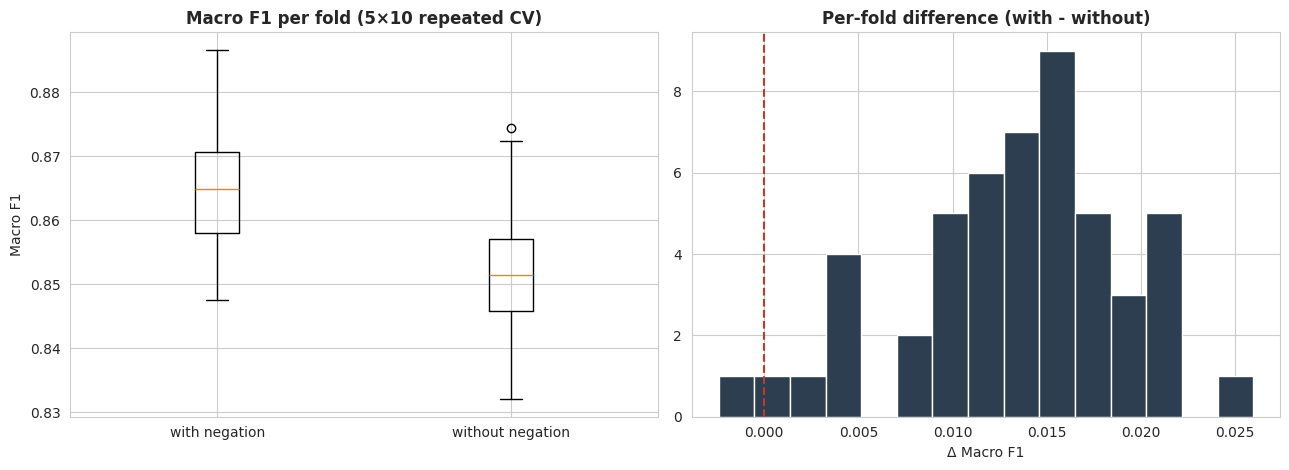

In [19]:
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

def cv_berulang(kolom):
    X = data_model.loc[idx_tr, kolom].values
    est = pipa(SVC(class_weight='balanced', random_state=RANDOM_STATE, **best_svm))
    return cross_validate(est, X, y_tr, cv=RCV, scoring=['f1_macro', 'accuracy'], n_jobs=N_JOBS)

t0 = time.time()
cv_neg, cv_noneg = cv_berulang('clean'), cv_berulang('clean_noneg')
print(f'Selesai dalam {time.time()-t0:.0f} dtk')

abl = pd.DataFrame({'lipatan': np.arange(1, 51),
                    'F1 dengan negasi': cv_neg['test_f1_macro'], 'F1 tanpa negasi': cv_noneg['test_f1_macro'],
                    'Akurasi dengan negasi': cv_neg['test_accuracy'], 'Akurasi tanpa negasi': cv_noneg['test_accuracy']})
abl['Selisih F1'] = abl['F1 dengan negasi'] - abl['F1 tanpa negasi']
simpan_tabel(abl, 't3_ablasi_negasi_per_lipatan', index=False)

d = abl['Selisih F1'].values; k = len(d)
rasio_uji_latih = 1 / 4                                    # 5-fold: 20% uji / 80% latih
t_stat = d.mean() / np.sqrt((1 / k + rasio_uji_latih) * d.var(ddof=1))
p_val = 2 * t_dist.sf(abs(t_stat), df=k - 1)
ringkas_abl = pd.DataFrame({
    'Rata-rata F1 dengan negasi': [abl['F1 dengan negasi'].mean()],
    'Rata-rata F1 tanpa negasi': [abl['F1 tanpa negasi'].mean()],
    'Rata-rata selisih': [d.mean()], 'SD selisih': [d.std(ddof=1)],
    'Lipatan negasi lebih baik': [f'{(d > 0).sum()}/{k}'],
    't terkoreksi': [t_stat], 'p-value': [p_val]}).round(4)
ringkas_abl['p-value'] = [f'{p_val:.2e}']
display(simpan_tabel(ringkas_abl, 't3_ablasi_negasi_ringkas', index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].boxplot([abl['F1 dengan negasi'], abl['F1 tanpa negasi']])
ax[0].set_xticks([1, 2]); ax[0].set_xticklabels(['with negation', 'without negation'])
ax[0].set_title('Macro F1 per fold (5×10 repeated CV)'); ax[0].set_ylabel('Macro F1')
ax[1].hist(d, bins=15, color='#2c3e50', edgecolor='white'); ax[1].axvline(0, color='#c0392b', ls='--')
ax[1].set_title('Per-fold difference (with - without)'); ax[1].set_xlabel('Δ Macro F1')
simpan_gambar('g3_ablasi_negasi')
catat_angka('Tahap3_ablasi_selisih_F1', round(d.mean(), 4)); catat_angka('Tahap3_ablasi_p', '< 0.001' if p_val < 0.001 else round(p_val, 4))

### 3.5 Kinerja per maskapai

In [20]:
te = data_model.loc[idx_te].copy()
te['pred'] = y_pred
te['pred_label'] = le.inverse_transform(y_pred)
te['skor_keputusan'] = svm_best.decision_function(X_te)

per_maskapai = (te.groupby('airline')
                  .apply(lambda g: pd.Series({
                      'n uji': len(g), '% negatif': (g['label'] == KODE_NEG).mean() * 100,
                      'Akurasi': accuracy_score(g['label'], g['pred']),
                      'Macro F1': f1_score(g['label'], g['pred'], average='macro', labels=[0, 1], zero_division=0)}))
                  .reindex(MASKAPAI).round(4))
display(simpan_tabel(per_maskapai, 't3_kinerja_per_maskapai'))

,n uji,% negatif,Akurasi,Macro F1
airline,,,,
United,616.0,83.7662,0.9188,0.8586
US Airways,493.0,90.2637,0.9533,0.8794
American,441.0,86.8481,0.9116,0.8273
Southwest,355.0,67.3239,0.8873,0.8736
JetBlue,306.0,64.0523,0.8856,0.8751
Virgin America,61.0,59.0164,0.8197,0.8063


### 3.6 Analisis kesalahan → `error_analysis.csv`
Isi kolom `jenis_kesalahan` secara manual dengan kode di bawah, lalu unggah kembali sebagai `error_analysis_coded.csv` (sel berikutnya merangkumnya otomatis bila file tersebut ditemukan).

In [21]:
KODE_KESALAHAN = {'S': 'Sarkasme / ironi', 'N': 'Negasi tidak tertangkap', 'C': 'Campuran positif-negatif',
                  'L': 'Label anotator diragukan', 'K': 'Butuh konteks percakapan',
                  'P': 'Pertanyaan / informasi tanpa sentimen jelas', 'O': 'Lainnya'}

err = te.loc[te['label'] != te['pred'],
             ['tweet_id', 'airline', 'text', 'clean', 'airline_sentiment', 'pred_label', 'skor_keputusan']].copy()
err = err.rename(columns={'airline_sentiment': 'label_manusia', 'pred_label': 'prediksi_svm'})
err['jenis_kesalahan'] = ''
err['catatan'] = ''
err = err.sort_values('skor_keputusan', key=np.abs, ascending=False)   # salah paling "yakin" di atas
err.to_csv(f'{OUT}/error_analysis.csv', index=False)
simpan_tabel(err, 't3_error_analysis', index=False)

print(f'{len(err)} tweet salah klasifikasi diekspor ke {OUT}/error_analysis.csv')
print(pd.crosstab(err['label_manusia'], err['prediksi_svm']))
print('\nKode jenis kesalahan:'); [print(f'  {k} = {v}') for k, v in KODE_KESALAHAN.items()]

coded = glob.glob('/kaggle/input/datasets/rizkisyafa/erorrr/error_analysis_coded.csv', recursive=True)
if coded:
    ec = pd.read_csv(coded[0])
    rek = ec['jenis_kesalahan'].str.upper().str.strip().map(KODE_KESALAHAN).value_counts()
    rek = pd.DataFrame({'n': rek, '%': (rek / rek.sum() * 100).round(1)})
    display(simpan_tabel(rek, 't3_rekap_jenis_kesalahan'))

198 tweet salah klasifikasi diekspor ke /kaggle/working/hasil/error_analysis.csv
prediksi_svm   negative  positive
label_manusia                    
negative              0       119
positive             79         0

Kode jenis kesalahan:
  S = Sarkasme / ironi
  N = Negasi tidak tertangkap
  C = Campuran positif-negatif
  L = Label anotator diragukan
  K = Butuh konteks percakapan
  P = Pertanyaan / informasi tanpa sentimen jelas
  O = Lainnya


,n,%
jenis_kesalahan,,
Lainnya,46,23.2
Campuran positif-negatif,40,20.2
Sarkasme / ironi,38,19.2
Butuh konteks percakapan,35,17.7
Negasi tidak tertangkap,18,9.1
Label anotator diragukan,11,5.6
Pertanyaan / informasi tanpa sentimen jelas,10,5.1


### 3.7 Stabilitas kata penanda: bootstrap koefisien SVM linear (100×)
Data latih di-*resample* dengan pengembalian, pipeline (TF-IDF + SVM linear) di-*fit* ulang, lalu dicatat kata mana yang masuk 20 besar. Bila kernel terbaik RBF, C diambil dari konfigurasi linear terbaik di grid.

100 bootstrap selesai dalam 144 dtk (C = 1.0)


,Penanda ketidakpuasan,Bobot |koef|,% masuk top-20 (neg),Penanda kepuasan,Bobot koef,% masuk top-20 (pos)
0,not,4.2413,100.0,thank,6.8284,100.0
1,worst,2.9802,100.0,great,3.6122,100.0
2,hours,2.5847,100.0,awesome,3.5783,100.0
3,delay,2.4540,100.0,love,3.5119,100.0
4,hold,2.4404,100.0,not wait,3.1365,88.0
5,no,2.1759,100.0,best,2.8105,100.0
6,pay,2.0854,85.0,impress,2.5881,78.0
7,lose,2.0647,77.0,good,2.5861,99.0
8,rude,2.0302,77.0,kudos,2.5798,92.0
9,bag,1.9076,87.0,amaze,2.5619,100.0


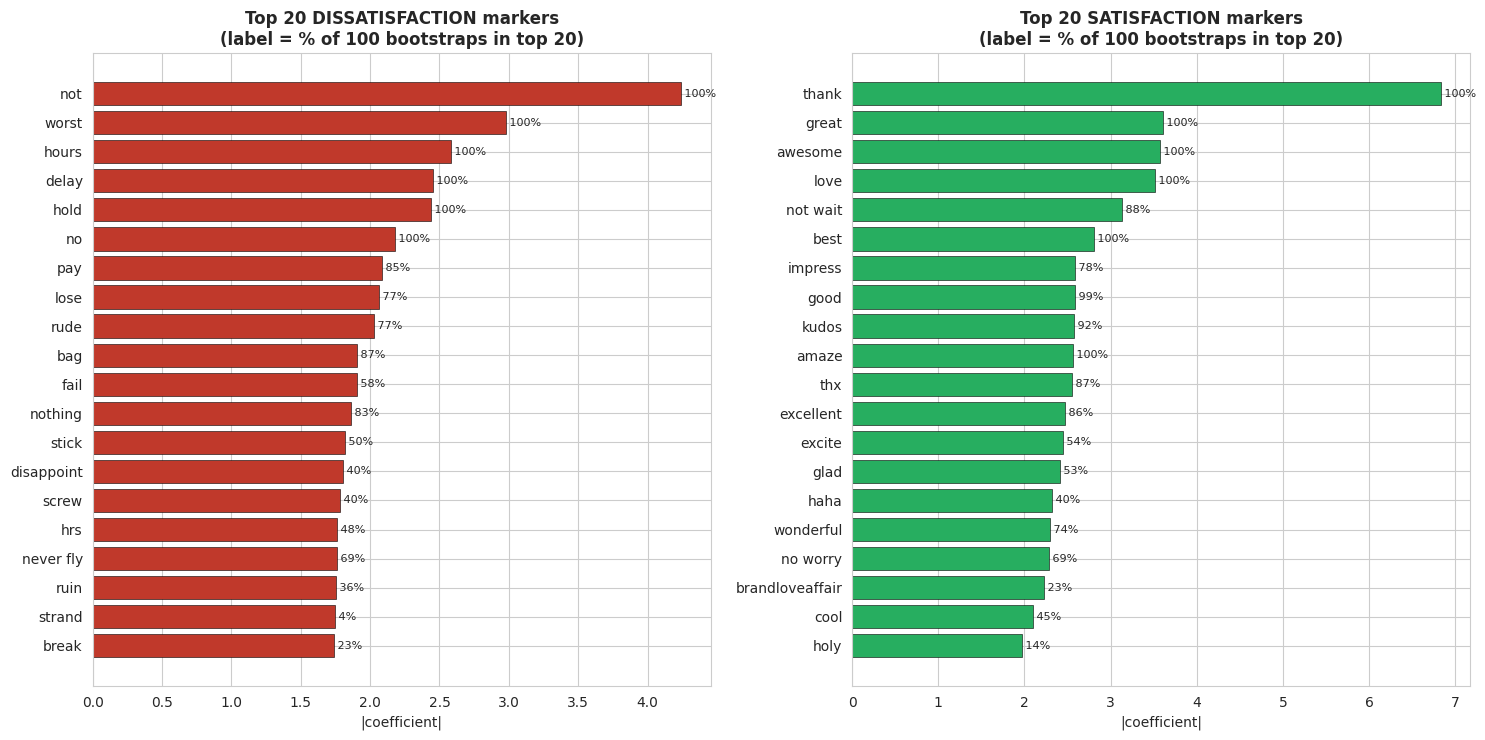

In [22]:
cv_lin = pd.DataFrame(grid_svm.cv_results_)
cv_lin = cv_lin[cv_lin['param_clf__kernel'] == 'linear']
C_LIN = float(cv_lin.loc[cv_lin['mean_test_score'].idxmax(), 'param_clf__C'])
TOPN = 20

def koef_linear(X, y):
    p = pipa(SVC(kernel='linear', C=C_LIN, class_weight='balanced', random_state=RANDOM_STATE)).fit(X, y)
    nama = p.named_steps['tfidf'].get_feature_names_out()
    c = p.named_steps['clf'].coef_
    c = (c.toarray() if hasattr(c, 'toarray') else np.asarray(c)).ravel()
    return nama, c

nama0, koef0 = koef_linear(X_tr, y_tr)              # koef < 0 -> kelas negative (kode 0)
o = np.argsort(koef0)
top_neg0, top_pos0 = nama0[o[:TOPN]], nama0[o[-TOPN:]][::-1]

rng = np.random.default_rng(RANDOM_STATE)
idx_boot = [rng.integers(0, len(X_tr), len(X_tr)) for _ in range(N_BOOT_KOEF)]
def satu_boot(ix):
    n, c = koef_linear(X_tr[ix], y_tr[ix]); o = np.argsort(c)
    return list(n[o[:TOPN]]), list(n[o[-TOPN:]])
t0 = time.time()
hasil_boot = Parallel(n_jobs=N_JOBS)(delayed(satu_boot)(ix) for ix in idx_boot)
print(f'{N_BOOT_KOEF} bootstrap selesai dalam {time.time()-t0:.0f} dtk (C = {C_LIN})')

frek_neg_b = pd.Series([w for a, _ in hasil_boot for w in a]).value_counts() / N_BOOT_KOEF * 100
frek_pos_b = pd.Series([w for _, b in hasil_boot for w in b]).value_counts() / N_BOOT_KOEF * 100
bobot0 = pd.Series(koef0, index=nama0)

stab = pd.DataFrame({
    'Penanda ketidakpuasan': top_neg0, 'Bobot |koef|': np.abs(bobot0[top_neg0].values).round(4),
    '% masuk top-20 (neg)': frek_neg_b.reindex(top_neg0).fillna(0).values.round(1),
    'Penanda kepuasan': top_pos0, 'Bobot koef': bobot0[top_pos0].values.round(4),
    '% masuk top-20 (pos)': frek_pos_b.reindex(top_pos0).fillna(0).values.round(1)})
display(simpan_tabel(stab, 't3_stabilitas_kata_penanda', index=False))
simpan_tabel(pd.DataFrame({'% top-20 negatif': frek_neg_b}), 't3_frekuensi_bootstrap_kata_negatif')
simpan_tabel(pd.DataFrame({'% top-20 positif': frek_pos_b}), 't3_frekuensi_bootstrap_kata_positif')

fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
for a, kata, w, f, warna, judul in [
        (ax[0], top_neg0, np.abs(bobot0[top_neg0].values), frek_neg_b.reindex(top_neg0).fillna(0).values, '#c0392b', 'DISSATISFACTION markers'),
        (ax[1], top_pos0, bobot0[top_pos0].values, frek_pos_b.reindex(top_pos0).fillna(0).values, '#27ae60', 'SATISFACTION markers')]:
    a.barh(kata[::-1], w[::-1], color=warna, edgecolor='black', linewidth=0.4)
    for i, (wi, fi) in enumerate(zip(w[::-1], f[::-1])):
        a.text(wi, i, f' {fi:.0f}%', va='center', fontsize=8)
    a.set_title(f'Top {TOPN} {judul}\n(label = % of {N_BOOT_KOEF} bootstraps in top {TOPN})'); a.set_xlabel('|coefficient|')
simpan_gambar('g3_kata_penanda_bootstrap')

### 3.8 Model 3 kelas (tambahan)
Negatif, netral, positif. Pembagian 80/20 terpisah dengan stratifikasi 3 kelas; grid sama dengan model biner.

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Parameter terbaik 3 kelas: {'clf__C': 1, 'clf__gamma': 1, 'clf__kernel': 'rbf'}
              precision    recall  f1-score   support

    negative     0.8650    0.8793    0.8721      1814
     neutral     0.6130    0.6221    0.6175       606
    positive     0.7112    0.6507    0.6796       458

    accuracy                         0.7887      2878
   macro avg     0.7297    0.7173    0.7231      2878
weighted avg     0.7874    0.7887    0.7878      2878



,Akurasi,Akurasi CI low,Akurasi CI high,Macro F1,F1 CI low,F1 CI high
Model,,,,,,
SVM 3 kelas,0.7887,0.7735,0.8033,0.7231,0.704,0.7422


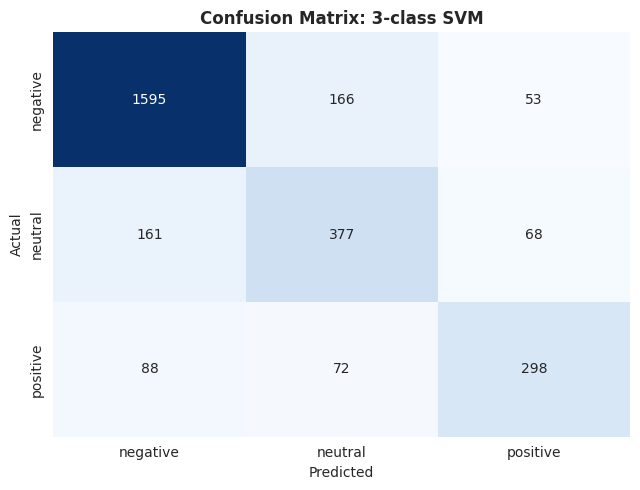

In [23]:
y3 = data['airline_sentiment'].values
i3_tr, i3_te = train_test_split(data.index.values, test_size=0.2, random_state=RANDOM_STATE, stratify=y3)
grid3 = GridSearchCV(pipa(SVC(class_weight='balanced', random_state=RANDOM_STATE)), param_svm,
                     cv=CV5, scoring='f1_macro', n_jobs=N_JOBS, verbose=1, refit=REFIT)
grid3.fit(data.loc[i3_tr, 'clean'].values, y3[i3_tr])
p3 = grid3.predict(data.loc[i3_te, 'clean'].values)
print('Parameter terbaik 3 kelas:', grid3.best_params_)
print(classification_report(y3[i3_te], p3, digits=4))

ci3 = bootstrap_ci(y3[i3_te], {'SVM 3 kelas': p3}, acuan=None)
display(simpan_tabel(ci3, 't3_model_3kelas_ci'))
rep3 = pd.DataFrame(classification_report(y3[i3_te], p3, output_dict=True, digits=4)).T.round(4)
simpan_tabel(rep3, 't3_model_3kelas_laporan')

lab3 = ['negative', 'neutral', 'positive']
plt.figure(figsize=(6.5, 5))
sns.heatmap(confusion_matrix(y3[i3_te], p3, labels=lab3), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=lab3, yticklabels=lab3)
plt.title('Confusion Matrix: 3-class SVM'); plt.xlabel('Predicted'); plt.ylabel('Actual')
simpan_gambar('g3_confusion_3kelas')
catat_angka('Tahap3_3kelas_macroF1', round(ci3.iloc[0]['Macro F1'], 4))

### 3.9 Pembanding transformer (RoBERTa-Twitter)

Menjawab Reviewer A ("at least one stronger model", "comparison with a transformer"). **SVM tetap model utama**; transformer hanya pembanding. Dua versi diuji pada data uji yang sama dengan SVM:

1. **Tanpa fine-tune**: `cardiffnlp/twitter-roberta-base-sentiment-latest` dipakai apa adanya (dilatih di TweetEval, bukan di dataset ini); kelas netral diabaikan, dibandingkan logit negatif vs positif.
2. **Fine-tune**: model yang sama dilatih ulang pada `idx_tr` (10% disisihkan untuk memilih epoch terbaik), loss berbobot kelas agar setara `class_weight='balanced'` pada SVM.

Teks masukan: teks asli dengan mention → `@user` dan URL → `http` (format prapemrosesan model cardiffnlp). Pelatihan memakai **kedua T4** (`DataParallel`) dan fp16.

In [24]:
TRF_MODEL = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
TRF_MAXLEN, TRF_BATCH_PER_GPU, TRF_LR = 128, 32, 2e-5
PAKAI_TRANSFORMER = (torch is not None) and not SMOKE

def siapkan_teks_roberta(t):
    t = html.unescape(str(t))
    t = re.sub(r'@\w+', '@user', t)
    t = re.sub(r'http\S+|www\.\S+', 'http', t)
    return re.sub(r'\s+', ' ', t).strip()

def _prediksi_logit(model, tok, texts, bs):
    model.eval(); out = []
    with torch.inference_mode():
        for s in range(0, len(texts), bs):
            enc = tok(list(texts[s:s + bs]), truncation=True, max_length=TRF_MAXLEN,
                      padding=True, return_tensors='pt').to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16, enabled=N_GPU > 0):
                lg = model(**enc, return_dict=False)[0]
            out.append(torch.softmax(lg.float(), dim=1).cpu().numpy())
    return np.vstack(out)

def roberta_tanpa_finetune(texts):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(TRF_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(TRF_MODEL).to(DEVICE)
    id2lab = {i: l.lower() for i, l in model.config.id2label.items()}
    if N_GPU > 1: model = torch.nn.DataParallel(model)
    p = _prediksi_logit(model, tok, np.asarray(texts, dtype=object), 128 * max(N_GPU, 1))
    del model; torch.cuda.empty_cache() if N_GPU else None
    i_neg = [i for i, l in id2lab.items() if l.startswith('neg')][0]
    i_pos = [i for i, l in id2lab.items() if l.startswith('pos')][0]
    return p, i_neg, i_pos

def finetune_transformer(teks_latih, y_latih, teks_uji, n_label, epochs=3, val_frac=0.1, seed=RANDOM_STATE, desc=''):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    tok = AutoTokenizer.from_pretrained(TRF_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(
        TRF_MODEL, num_labels=n_label, ignore_mismatched_sizes=True).to(DEVICE)
    if N_GPU > 1: model = torch.nn.DataParallel(model)
    teks_latih = np.asarray(teks_latih, dtype=object); y_latih = np.asarray(y_latih)
    i_fit, i_val = train_test_split(np.arange(len(y_latih)), test_size=val_frac, random_state=seed, stratify=y_latih)
    bs = TRF_BATCH_PER_GPU * max(N_GPU, 1)
    hit = np.bincount(y_latih[i_fit], minlength=n_label).clip(min=1)
    bobot = torch.tensor(len(i_fit) / (n_label * hit), dtype=torch.float, device=DEVICE)
    loss_fn = torch.nn.CrossEntropyLoss(weight=bobot)
    opt = torch.optim.AdamW(model.parameters(), lr=TRF_LR, weight_decay=0.01)
    n_step = epochs * int(np.ceil(len(i_fit) / bs))
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * n_step), n_step)
    scaler = torch.amp.GradScaler('cuda', enabled=N_GPU > 0)
    rng = np.random.default_rng(seed); f1_terbaik, state_terbaik, ep_terbaik = -1, None, 0
    for ep in range(epochs):
        model.train()
        urut = rng.permutation(i_fit)
        for s in tqdm(range(0, len(urut), bs), desc=f'{desc} epoch {ep + 1}/{epochs}', leave=False):
            ix = urut[s:s + bs]
            enc = tok(list(teks_latih[ix]), truncation=True, max_length=TRF_MAXLEN,
                      padding=True, return_tensors='pt').to(DEVICE)
            yb = torch.tensor(y_latih[ix], device=DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16, enabled=N_GPU > 0):
                lg = model(**enc, return_dict=False)[0]
            loss = loss_fn(lg.float(), yb)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        pv = _prediksi_logit(model, tok, teks_latih[i_val], bs * 2).argmax(1)
        f1v = f1_score(y_latih[i_val], pv, average='macro')
        print(f'  {desc} epoch {ep + 1}: macro F1 validasi = {f1v:.4f}')
        if f1v > f1_terbaik:
            f1_terbaik, ep_terbaik = f1v, ep + 1
            state_terbaik = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state_terbaik)
    proba = _prediksi_logit(model, tok, np.asarray(teks_uji, dtype=object), bs * 2)
    del model, opt; torch.cuda.empty_cache() if N_GPU else None
    return proba, f1_terbaik, ep_terbaik

data_model['teks_roberta'] = data_model['text'].apply(siapkan_teks_roberta)
T_tr, T_te = data_model.loc[idx_tr, 'teks_roberta'].values, data_model.loc[idx_te, 'teks_roberta'].values

if PAKAI_TRANSFORMER:
    t0 = time.time()
    p0, i_neg, i_pos = roberta_tanpa_finetune(T_te)
    pred_rob0 = np.where(p0[:, i_pos] > p0[:, i_neg], KODE_POS, KODE_NEG)
    proba_ft, f1v, ep = finetune_transformer(T_tr, y_tr, T_te, n_label=2, epochs=3, desc='Sentimen')
    pred_robft = proba_ft.argmax(1)
    print(f'Transformer selesai dalam {time.time() - t0:.0f} dtk (epoch terpilih: {ep})')
else:
    print('MODE UJI / tanpa GPU: prediksi transformer DIGANTI tiruan (bukan hasil sebenarnya).')
    pred_rob0, pred_robft = PRED['VADER (tanpa pelatihan)'].copy(), PRED['Logistic Regression'].copy()

PRED_T = {'SVM': PRED['SVM'], 'Logistic Regression': PRED['Logistic Regression'],
          'RoBERTa-Twitter (tanpa fine-tune)': pred_rob0, 'RoBERTa-Twitter (fine-tune)': pred_robft}
tabel_trf = bootstrap_ci(y_te, PRED_T)
display(simpan_tabel(tabel_trf, 't3_pembanding_transformer_ci'))

baris = []
for m in PRED_T:
    if m == 'SVM': continue
    tab, stat, p = uji_mcnemar(y_te, PRED_T['SVM'], PRED_T[m])
    baris.append({'Pembanding': m, 'SVM benar & pembanding salah': tab[0, 1],
                  'SVM salah & pembanding benar': tab[1, 0], 'Statistik': round(float(stat), 3),
                  'p-value': float(p), 'Signifikan (α=0,05)': 'Ya' if p < 0.05 else 'Tidak'})
display(simpan_tabel(pd.DataFrame(baris).set_index('Pembanding'), 't3_mcnemar_svm_vs_transformer'))

# Kesalahan SVM yang diperbaiki transformer (per arah, dan per jenis bila file kode manual ada)
te['pred_trf'] = pred_robft
salah = te[te['label'] != te['pred']].copy()
salah['trf_benar'] = salah['pred_trf'] == salah['label']
per_arah = salah.groupby('airline_sentiment')['trf_benar'].agg(n='size', diperbaiki='sum')
per_arah['% diperbaiki'] = (per_arah['diperbaiki'] / per_arah['n'] * 100).round(1)
per_arah.index = per_arah.index.map(lambda s: f'Label {s}, SVM salah')
display(simpan_tabel(per_arah, 't3_kesalahan_svm_diperbaiki_transformer_arah'))

coded = glob.glob('/kaggle/input/**/error_analysis_coded.csv', recursive=True)
if coded:
    ec = pd.read_csv(coded[0])[['tweet_id', 'jenis_kesalahan']]
    sj = salah.merge(ec, on='tweet_id', how='left')
    sj['Jenis'] = sj['jenis_kesalahan'].str.upper().str.strip().map(KODE_KESALAHAN)
    per_jenis = sj.groupby('Jenis')['trf_benar'].agg(n='size', diperbaiki='sum')
    per_jenis['% diperbaiki'] = (per_jenis['diperbaiki'] / per_jenis['n'] * 100).round(1)
    display(simpan_tabel(per_jenis.sort_values('n', ascending=False), 't3_kesalahan_svm_diperbaiki_transformer_jenis'))
else:
    print('error_analysis_coded.csv tidak ditemukan; rincian per jenis kesalahan dilewati.')

catat_angka('Tahap3_RoBERTa_finetune_macroF1', round(tabel_trf.loc['RoBERTa-Twitter (fine-tune)', 'Macro F1'], 4))
catat_angka('Tahap3_RoBERTa_tanpa_finetune_macroF1', round(tabel_trf.loc['RoBERTa-Twitter (tanpa fine-tune)', 'Macro F1'], 4))

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

...

  Sentimen epoch 3: macro F1 validasi = 0.9501
Transformer selesai dalam 104 dtk (epoch terpilih: 3)


,Akurasi,Akurasi CI low,Akurasi CI high,Macro F1,F1 CI low,F1 CI high,Selisih F1 (acuan - model),Selisih CI low,Selisih CI high
Model,,,,,,,,,
SVM,0.9129,0.9010,0.9234,0.8686,0.8508,0.8848,NaN,NaN,NaN
Logistic Regression,0.9181,0.9067,0.9283,0.8741,0.8560,0.8897,-0.0054,-0.0128,0.0021
RoBERTa-Twitter (tanpa fine-tune),0.9164,0.9049,0.9283,0.8843,0.8677,0.9005,-0.0160,-0.0350,0.0031
RoBERTa-Twitter (fine-tune),0.9595,0.9511,0.9674,0.9392,0.9262,0.9512,-0.0708,-0.0873,-0.0538


,SVM benar & pembanding salah,SVM salah & pembanding benar,Statistik,p-value,"Signifikan (α=0,05)"
Pembanding,,,,,
Logistic Regression,14,26,3.025,8.199032e-02,Tidak
RoBERTa-Twitter (tanpa fine-tune),128,136,0.186,6.665991e-01,Tidak
RoBERTa-Twitter (fine-tune),42,148,58.026,2.586347e-14,Ya


,n,diperbaiki,% diperbaiki
airline_sentiment,,,
"Label negative, SVM salah",119,86,72.3
"Label positive, SVM salah",79,62,78.5


,n,diperbaiki,% diperbaiki
Jenis,,,
Lainnya,46,45,97.8
Campuran positif-negatif,40,31,77.5
Sarkasme / ironi,38,22,57.9
Butuh konteks percakapan,35,20,57.1
Negasi tidak tertangkap,18,17,94.4
Label anotator diragukan,11,5,45.5
Pertanyaan / informasi tanpa sentimen jelas,10,8,80.0


### 3.10 Uji potongan waktu terpisah (temporal hold-out)

Menjawab Reviewer B tentang klaim penggunaan untuk monitoring. SVM dilatih pada tweet **sebelum 22 Februari** dan diuji pada **22–24 Februari**, meniru situasi model dipakai untuk tweet yang datang kemudian. Hiperparameter sama dengan 3.1. Catatan: American hampir tidak punya tweet di periode latih, sehingga hasil American menunjukkan kemampuan model pada maskapai yang praktis belum pernah dilihat.

In [25]:
BATAS_WAKTU = '2015-02-22'
i_awal = data_model.index[data_model['tanggal'] < BATAS_WAKTU]
i_akhir = data_model.index[data_model['tanggal'] >= BATAS_WAKTU]
est_t = pipa(SVC(class_weight='balanced', random_state=RANDOM_STATE, **best_svm))
est_t.fit(data_model.loc[i_awal, 'clean'].values, y_all[i_awal])
pred_t = est_t.predict(data_model.loc[i_akhir, 'clean'].values)
y_t = y_all[i_akhir]

ci_t = bootstrap_ci(y_t, {'SVM (latih < 22 Feb, uji 22-24 Feb)': pred_t}, acuan=None)
ci_t.loc['SVM (split acak 80/20, 3.2)'] = tabel_ci.loc['SVM', ci_t.columns]
ci_t.insert(0, 'n latih', [len(i_awal), len(idx_tr)]); ci_t.insert(1, 'n uji', [len(i_akhir), len(idx_te)])
display(simpan_tabel(ci_t, 't3_temporal_holdout'))

dft = data_model.loc[i_akhir, ['airline']].assign(y=y_t, p=pred_t)
per_m_t = (dft.groupby('airline').apply(lambda g: pd.Series({
              'n latih (maskapai ini)': int((data_model.loc[i_awal, 'airline'] == g.name).sum()),
              'n uji': len(g), 'Akurasi': accuracy_score(g['y'], g['p']),
              'Macro F1': f1_score(g['y'], g['p'], average='macro', labels=[0, 1], zero_division=0)}))
           .reindex(MASKAPAI).round(4))
display(simpan_tabel(per_m_t, 't3_temporal_holdout_per_maskapai'))
catat_angka('Tahap3_temporal_macroF1', round(ci_t.iloc[0]['Macro F1'], 4))

,n latih,n uji,Akurasi,Akurasi CI low,Akurasi CI high,Macro F1,F1 CI low,F1 CI high
Model,,,,,,,,
"SVM (latih < 22 Feb, uji 22-24 Feb)",5532,5826,0.9113,0.9039,0.9185,0.8457,0.8327,0.8576
"SVM (split acak 80/20, 3.2)",9086,2272,0.9129,0.9010,0.9234,0.8686,0.8508,0.8848


,n latih (maskapai ini),n uji,Akurasi,Macro F1
airline,,,,
United,1815.0,1293.0,0.9118,0.8194
US Airways,1384.0,1137.0,0.9340,0.8074
American,4.0,2157.0,0.9221,0.8478
Southwest,1224.0,526.0,0.8764,0.8585
JetBlue,887.0,599.0,0.8715,0.8492
Virgin America,218.0,114.0,0.8421,0.8334


---
# TAHAP 4 — SVM Penebak Kategori Keluhan

Pemetaan diubah: **Damaged Luggage → Reliability** (kegagalan menjalankan layanan penanganan bagasi secara akurat, sejalan dengan Lost Luggage). Akibatnya dimensi Tangibles tidak lagi muncul di pemetaan berbasis kategori.

In [26]:
SERVQUAL_MAP = {
    'Customer Service Issue'     : 'Responsiveness',
    'longlines'                  : 'Responsiveness',
    'Late Flight'                : 'Reliability',
    'Cancelled Flight'           : 'Reliability',
    'Lost Luggage'               : 'Reliability',
    'Damaged Luggage'            : 'Reliability',     # revisi (sebelumnya Tangibles)
    'Flight Booking Problems'    : 'Reliability',
    'Flight Attendant Complaints': 'Assurance',
    'Bad Flight'                 : 'Assurance',
}
DIMENSI = ['Reliability', 'Responsiveness', 'Assurance', 'Tangibles', 'Empathy']
simpan_tabel(pd.Series(SERVQUAL_MAP, name='Dimensi').rename_axis('Kategori').to_frame(), 't4_pemetaan_servqual')

neg_semua = data_model[data_model['airline_sentiment'] == 'negative']
neg = neg_semua[neg_semua['negativereason'].notna() & (neg_semua['negativereason'] != CT)].copy()
neg_ct = neg_semua[neg_semua['negativereason'] == CT].copy()
catat("Tweet negatif tanpa Can't Tell (neg)", len(neg_semua), len(neg), f'{len(neg_ct)} Can\'t Tell dipisah')

tak_terpetakan = set(neg['negativereason']) - set(SERVQUAL_MAP)
assert not tak_terpetakan, f'Kategori belum dipetakan: {tak_terpetakan}'

neg['partisi'] = np.where(neg.index.isin(idx_tr), 'latih', 'uji')    # idx dari Tahap 3
neg['dim_label'] = neg['negativereason'].map(SERVQUAL_MAP)
neg_tr, neg_te = neg[neg['partisi'] == 'latih'], neg[neg['partisi'] == 'uji']
print(f'neg: {len(neg)} tweet | latih {len(neg_tr)} | uji {len(neg_te)}')
display(pd.crosstab(neg['negativereason'], neg['partisi'], margins=True))

Tweet negatif tanpa Can't Tell (neg)                      9071 ->   7900  (terbuang 1171)
neg: 7900 tweet | latih 6315 | uji 1585


partisi,latih,uji,All
negativereason,,,
Bad Flight,461,113,574
Cancelled Flight,660,168,828
Customer Service Issue,2332,550,2882
Damaged Luggage,61,12,73
Flight Attendant Complaints,363,112,475
Flight Booking Problems,413,110,523
Late Flight,1312,338,1650
Lost Luggage,575,143,718
longlines,138,39,177


### 4.1 LinearSVC multi-kelas (latih hanya pada tweet negatif di partisi latih)

C terbaik = 0.1 | F1-macro CV = 0.5638


,precision,recall,f1-score,support
Bad Flight,0.4887,0.5752,0.5285,113.0000
Cancelled Flight,0.7238,0.7798,0.7507,168.0000
Customer Service Issue,0.7970,0.6782,0.7328,550.0000
Damaged Luggage,0.1538,0.1667,0.1600,12.0000
Flight Attendant Complaints,0.4912,0.5000,0.4956,112.0000
Flight Booking Problems,0.5113,0.6182,0.5597,110.0000
Late Flight,0.7530,0.7308,0.7417,338.0000
Lost Luggage,0.7124,0.7622,0.7365,143.0000
longlines,0.2903,0.4615,0.3564,39.0000
accuracy,0.6744,0.6744,0.6744,0.6744


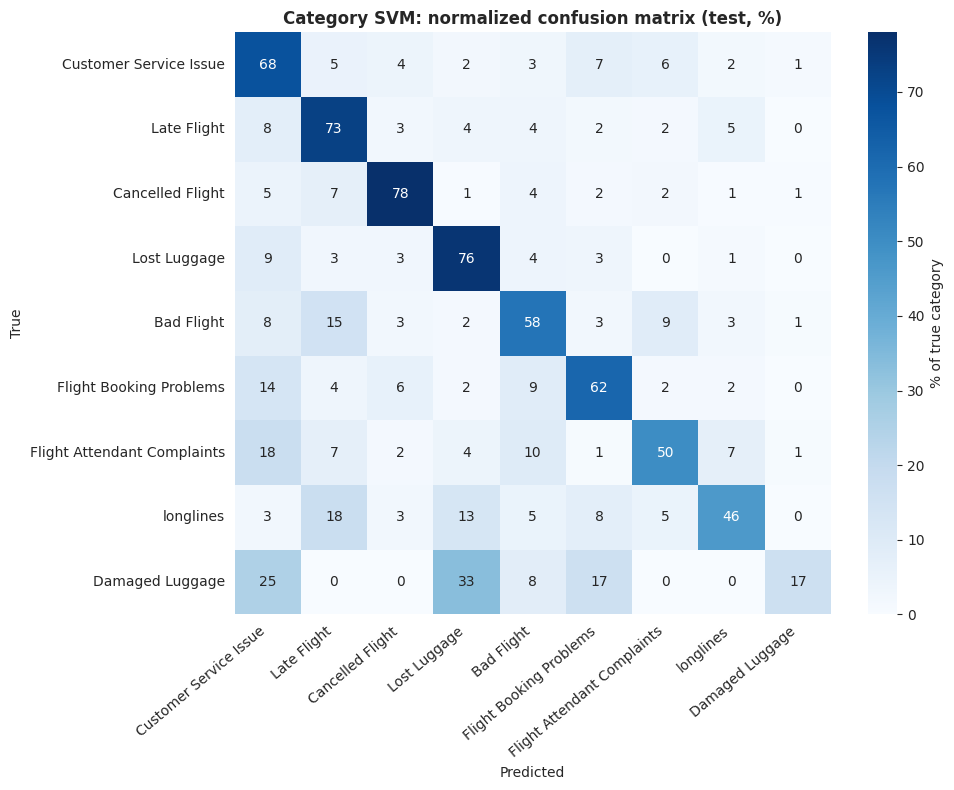

,precision,recall,f1-score,support
Assurance,0.5749,0.6311,0.6017,225.0000
Reliability,0.7859,0.8236,0.8043,771.0000
Responsiveness,0.7604,0.6842,0.7203,589.0000
accuracy,0.7445,0.7445,0.7445,0.7445
macro avg,0.7071,0.7130,0.7088,1585.0000
weighted avg,0.7465,0.7445,0.7443,1585.0000


Akurasi kategori (uji): 0.6744 | macro F1: 0.5624
Akurasi dimensi  (uji): 0.7445 | macro F1: 0.7088


In [27]:
grid_kat = GridSearchCV(
    pipa(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE, max_iter=20000)),
    {'clf__C': [0.01, 0.1, 1, 10]}, cv=CV5, scoring='f1_macro', n_jobs=N_JOBS)
grid_kat.fit(neg_tr['clean'].values, neg_tr['negativereason'].values)
kat_model = grid_kat.best_estimator_
C_KAT = grid_kat.best_params_['clf__C']
print(f'C terbaik = {C_KAT} | F1-macro CV = {grid_kat.best_score_:.4f}')

pred_kat_te = kat_model.predict(neg_te['clean'].values)
rep_kat = pd.DataFrame(classification_report(neg_te['negativereason'], pred_kat_te,
                                             output_dict=True, zero_division=0)).T.round(4)
display(simpan_tabel(rep_kat, 't4_kategori_per_kelas_uji'))

kat_urut = neg['negativereason'].value_counts().index.tolist()
cmk = confusion_matrix(neg_te['negativereason'], pred_kat_te, labels=kat_urut, normalize='true')
plt.figure(figsize=(10, 8))
sns.heatmap(cmk * 100, annot=True, fmt='.0f', cmap='Blues', xticklabels=kat_urut, yticklabels=kat_urut,
            cbar_kws={'label': '% of true category'})
plt.title('Category SVM: normalized confusion matrix (test, %)'); plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(rotation=40, ha='right')
simpan_gambar('g4_confusion_kategori')

# Tingkat dimensi
dim_true_te = neg_te['negativereason'].map(SERVQUAL_MAP)
dim_pred_te = pd.Series(pred_kat_te, index=neg_te.index).map(SERVQUAL_MAP)
rep_dim = pd.DataFrame(classification_report(dim_true_te, dim_pred_te, output_dict=True, zero_division=0)).T.round(4)
display(simpan_tabel(rep_dim, 't4_dimensi_per_kelas_uji'))
print(f'Akurasi kategori (uji): {accuracy_score(neg_te["negativereason"], pred_kat_te):.4f} | '
      f'macro F1: {f1_score(neg_te["negativereason"], pred_kat_te, average="macro"):.4f}')
print(f'Akurasi dimensi  (uji): {accuracy_score(dim_true_te, dim_pred_te):.4f} | '
      f'macro F1: {f1_score(dim_true_te, dim_pred_te, average="macro"):.4f}')
catat_angka('Tahap4_kategori_C', C_KAT)
catat_angka('Tahap4_kategori_akurasi_uji', round(accuracy_score(neg_te['negativereason'], pred_kat_te), 4))
catat_angka('Tahap4_kategori_macroF1_uji', round(f1_score(neg_te['negativereason'], pred_kat_te, average='macro'), 4))
catat_angka('Tahap4_dimensi_akurasi_uji', round(accuracy_score(dim_true_te, dim_pred_te), 4))

### 4.2 Alur penuh di data uji: SVM sentimen → SVM kategori → dimensi
Label pembanding manusia: positif → `Non-negatif`; negatif → dimensi dari `negativereason`. Tweet Can't Tell dikeluarkan dari evaluasi karena tidak punya label dimensi.

In [28]:
e2e = data_model.loc[idx_te].copy()
e2e['sent_pred'] = le.inverse_transform(svm_best.predict(e2e['clean'].values))
kat_semua = kat_model.predict(e2e['clean'].values)
e2e['kat_alur'] = np.where(e2e['sent_pred'] == 'negative', kat_semua, None)
e2e['dim_alur'] = np.where(e2e['sent_pred'] == 'negative',
                           pd.Series(kat_semua, index=e2e.index).map(SERVQUAL_MAP), 'Non-negatif')
e2e['dim_manusia'] = np.where(e2e['airline_sentiment'] == 'positive', 'Non-negatif',
                              e2e['negativereason'].map(SERVQUAL_MAP))
e2e_eval = e2e[e2e['negativereason'] != CT].dropna(subset=['dim_manusia'])

print(f'Tweet uji dievaluasi: {len(e2e_eval)} (Can\'t Tell dikeluarkan: {(e2e["negativereason"] == CT).sum()})')
print(f'Akurasi alur penuh : {accuracy_score(e2e_eval["dim_manusia"], e2e_eval["dim_alur"]):.4f}')
print(f'Macro F1 alur penuh: {f1_score(e2e_eval["dim_manusia"], e2e_eval["dim_alur"], average="macro"):.4f}')
rep_e2e = pd.DataFrame(classification_report(e2e_eval['dim_manusia'], e2e_eval['dim_alur'],
                                             output_dict=True, zero_division=0)).T.round(4)
display(simpan_tabel(rep_e2e, 't4_alur_penuh_laporan'))
display(simpan_tabel(pd.crosstab(e2e_eval['dim_manusia'], e2e_eval['dim_alur'], margins=True,
                                 rownames=['Manusia'], colnames=['Alur SVM']), 't4_alur_penuh_tabel_silang'))

# Distribusi dimensi di antara keluhan: manusia vs alur
dist = pd.DataFrame({
    'Manusia (%)': e2e_eval.loc[e2e_eval['dim_manusia'] != 'Non-negatif', 'dim_manusia'].value_counts(normalize=True) * 100,
    'Alur SVM (%)': e2e_eval.loc[e2e_eval['dim_alur'] != 'Non-negatif', 'dim_alur'].value_counts(normalize=True) * 100}).round(2)
dist['Selisih (pp)'] = (dist['Alur SVM (%)'] - dist['Manusia (%)']).round(2)
display(simpan_tabel(dist, 't4_alur_penuh_distribusi_dimensi'))
catat_angka('Tahap4_alur_penuh_akurasi', round(accuracy_score(e2e_eval['dim_manusia'], e2e_eval['dim_alur']), 4))
catat_angka('Tahap4_alur_penuh_macroF1', round(f1_score(e2e_eval['dim_manusia'], e2e_eval['dim_alur'], average='macro'), 4))

Tweet uji dievaluasi: 2042 (Can't Tell dikeluarkan: 230)
Akurasi alur penuh : 0.7331
Macro F1 alur penuh: 0.7062


,precision,recall,f1-score,support
Assurance,0.5242,0.5778,0.5497,225.0000
Non-negatif,0.8094,0.8271,0.8182,457.0000
Reliability,0.7652,0.7860,0.7754,771.0000
Responsiveness,0.7159,0.6503,0.6815,589.0000
accuracy,0.7331,0.7331,0.7331,0.7331
macro avg,0.7037,0.7103,0.7062,2042.0000
weighted avg,0.7343,0.7331,0.7330,2042.0000


Alur SVM,Assurance,Non-negatif,Reliability,Responsiveness,All
Manusia,,,,,
Assurance,130,22,36,37,225
Non-negatif,25,378,23,31,457
Reliability,43,38,606,84,771
Responsiveness,50,29,127,383,589
All,248,467,792,535,2042


,Manusia (%),Alur SVM (%),Selisih (pp)
Reliability,48.64,50.29,1.65
Responsiveness,37.16,33.97,-3.19
Assurance,14.20,15.75,1.55


### 4.3 Prediksi out-of-fold untuk semua tweet negatif (`cat_pred`, `dim_pred`, `dim_label`)
Setiap tweet diprediksi oleh model yang tidak melihat tweet tersebut saat dilatih (5-fold, C dari 4.1).

In [29]:
oof_est = pipa(LinearSVC(C=C_KAT, class_weight='balanced', random_state=RANDOM_STATE, max_iter=20000))
neg['cat_pred'] = cross_val_predict(oof_est, neg['clean'].values, neg['negativereason'].values,
                                    cv=CV5, n_jobs=N_JOBS)
neg['dim_pred'] = neg['cat_pred'].map(SERVQUAL_MAP)
# dim_label sudah dibuat di awal Tahap 4 dari label manusia (negativereason)

ringkas_oof = pd.DataFrame({
    'Akurasi': [accuracy_score(neg['negativereason'], neg['cat_pred']), accuracy_score(neg['dim_label'], neg['dim_pred'])],
    'Macro F1': [f1_score(neg['negativereason'], neg['cat_pred'], average='macro'),
                 f1_score(neg['dim_label'], neg['dim_pred'], average='macro')],
    "Cohen's kappa": [cohen_kappa_score(neg['negativereason'], neg['cat_pred']),
                      cohen_kappa_score(neg['dim_label'], neg['dim_pred'])]},
    index=['Kategori (OOF)', 'Dimensi (OOF)']).round(4)
display(simpan_tabel(ringkas_oof, 't4_oof_ringkas'))
display(simpan_tabel(pd.DataFrame({'dim_label (%)': neg['dim_label'].value_counts(normalize=True) * 100,
                                   'dim_pred (%)': neg['dim_pred'].value_counts(normalize=True) * 100}).round(2),
                     't4_oof_distribusi_dimensi'))
catat_angka('Tahap4_OOF_dimensi_kappa', ringkas_oof.loc['Dimensi (OOF)', "Cohen's kappa"])

,Akurasi,Macro F1,Cohen's kappa
Kategori (OOF),0.6733,0.5776,0.5945
Dimensi (OOF),0.7446,0.7051,0.5762


,dim_label (%),dim_pred (%)
Reliability,48.00,50.80
Responsiveness,38.72,34.61
Assurance,13.28,14.59


### 4.4 Ilustrasi: prediksi kategori untuk tweet Can't Tell
Model dilatih pada seluruh `neg`, lalu diterapkan ke tweet Can't Tell. Ini **ilustrasi**, bukan hasil utama, karena tidak ada label pembanding.

In [30]:
kat_final = pipa(LinearSVC(C=C_KAT, class_weight='balanced', random_state=RANDOM_STATE, max_iter=20000))
kat_final.fit(neg['clean'].values, neg['negativereason'].values)
neg_ct['cat_pred'] = kat_final.predict(neg_ct['clean'].values)
neg_ct['dim_pred'] = neg_ct['cat_pred'].map(SERVQUAL_MAP)

ct_dist = pd.DataFrame({'n': neg_ct['cat_pred'].value_counts()})
ct_dist['%'] = (ct_dist['n'] / ct_dist['n'].sum() * 100).round(2)
ct_dist['Dimensi'] = ct_dist.index.map(SERVQUAL_MAP)
display(simpan_tabel(ct_dist, 't4_cant_tell_prediksi_kategori'))
contoh_ct = (neg_ct.sample(frac=1, random_state=RANDOM_STATE).groupby('cat_pred').head(2)
             .sort_values('cat_pred')[['airline', 'text', 'cat_pred', 'dim_pred']])
display(simpan_tabel(contoh_ct, 't4_cant_tell_contoh', index=False))

,n,%,Dimensi
cat_pred,,,
Customer Service Issue,438,37.40,Responsiveness
Bad Flight,236,20.15,Assurance
Flight Booking Problems,144,12.30,Reliability
Late Flight,108,9.22,Reliability
Flight Attendant Complaints,81,6.92,Assurance
Lost Luggage,72,6.15,Reliability
longlines,36,3.07,Responsiveness
Cancelled Flight,28,2.39,Reliability
Damaged Luggage,28,2.39,Reliability


,airline,text,cat_pred,dim_pred
10080,American,@AmericanAir really,Bad Flight,Assurance
1576,United,@united now the weight restriction? 'We'll try...,Bad Flight,Assurance
6857,US Airways,@USAirways is the worst. I have to pay $200 ju...,Cancelled Flight,Reliability
5137,Southwest,@SouthwestAir no flights out of #nashville tod...,Cancelled Flight,Reliability
5501,JetBlue,@JetBlue ill call in the morning. too upset ri...,Customer Service Issue,Responsiveness
1922,United,@united yes refund my ticket and give me email...,Customer Service Issue,Responsiveness
5906,JetBlue,@JetBlue where did my travel bank credit go? ...,Damaged Luggage,Reliability
4351,Southwest,@SouthwestAir Gary Kelly should be ashamed of ...,Damaged Luggage,Reliability
1349,United,@united - 3 of 6 First seats open on UA5097. N...,Flight Attendant Complaints,Assurance
8279,US Airways,@USAirways Know what I like about gate 35X @Na...,Flight Attendant Complaints,Assurance


### 4.5 Pembanding transformer untuk kategori keluhan (out-of-fold)

RoBERTa-Twitter di-*fine-tune* untuk menebak 9 kategori keluhan dengan **lipatan 5-fold yang sama persis** dengan OOF SVM (4.3), sehingga perbandingan adil. Hasilnya (`cat_pred_trf`, `dim_pred_trf`) dipakai di Tahap 6.2 untuk memeriksa apakah kesimpulan per maskapai berubah bila model diganti.

In [31]:
kat_kelas = sorted(neg['negativereason'].unique())
kat2id = {k: i for i, k in enumerate(kat_kelas)}
y_kat = neg['negativereason'].map(kat2id).values
teks_neg = neg['text'].apply(siapkan_teks_roberta).values

if PAKAI_TRANSFORMER:
    t0 = time.time(); oof_trf = np.empty(len(neg), dtype=object)
    for f, (a, b) in enumerate(CV5.split(teks_neg, y_kat)):
        proba, _, ep = finetune_transformer(teks_neg[a], y_kat[a], teks_neg[b], n_label=len(kat_kelas),
                                            epochs=4, desc=f'Kategori fold {f + 1}/5')
        oof_trf[b] = np.array(kat_kelas)[proba.argmax(1)]
    print(f'OOF transformer kategori selesai dalam {time.time() - t0:.0f} dtk')
else:
    print('MODE UJI / tanpa GPU: cat_pred_trf DIGANTI tiruan (salinan cat_pred).')
    oof_trf = neg['cat_pred'].values.copy()
neg['cat_pred_trf'] = oof_trf
neg['dim_pred_trf'] = neg['cat_pred_trf'].map(SERVQUAL_MAP)

bandingan = pd.DataFrame({
    'Akurasi kategori': [accuracy_score(neg['negativereason'], neg[c]) for c in ['cat_pred', 'cat_pred_trf']],
    'Macro F1 kategori': [f1_score(neg['negativereason'], neg[c], average='macro') for c in ['cat_pred', 'cat_pred_trf']],
    'Akurasi dimensi': [accuracy_score(neg['dim_label'], neg[c]) for c in ['dim_pred', 'dim_pred_trf']],
    'Macro F1 dimensi': [f1_score(neg['dim_label'], neg[c], average='macro') for c in ['dim_pred', 'dim_pred_trf']],
    "Kappa dimensi vs manusia": [cohen_kappa_score(neg['dim_label'], neg[c]) for c in ['dim_pred', 'dim_pred_trf']]},
    index=['SVM (OOF)', 'RoBERTa-Twitter (OOF)']).round(4)
display(simpan_tabel(bandingan, 't4_pembanding_transformer_kategori'))

f1_kat = pd.DataFrame({
    'F1 SVM': f1_score(neg['negativereason'], neg['cat_pred'], labels=kat_kelas, average=None),
    'F1 RoBERTa': f1_score(neg['negativereason'], neg['cat_pred_trf'], labels=kat_kelas, average=None),
    'n': neg['negativereason'].value_counts().reindex(kat_kelas).values}, index=kat_kelas).round(4)
f1_kat['Selisih (RoBERTa - SVM)'] = (f1_kat['F1 RoBERTa'] - f1_kat['F1 SVM']).round(4)
display(simpan_tabel(f1_kat.sort_values('n', ascending=False), 't4_pembanding_transformer_per_kategori'))
display(simpan_tabel(pd.DataFrame({k: neg[c].value_counts(normalize=True) * 100 for k, c in
                                   [('Manusia (%)', 'dim_label'), ('SVM (%)', 'dim_pred'), ('RoBERTa (%)', 'dim_pred_trf')]}).round(2),
                     't4_pembanding_transformer_distribusi_dimensi'))
catat_angka('Tahap4_RoBERTa_kategori_macroF1_OOF', bandingan.loc['RoBERTa-Twitter (OOF)', 'Macro F1 kategori'])

[transformers] You passed `num_labels=9` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([9])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([9, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect 

Kategori fold 1/5 epoch 1/4:   0%|          | 0/89 [00:00<?, ?it/s]

  Kategori fold 1/5 epoch 1: macro F1 validasi = 0.5098


...

Kategori fold 5/5 epoch 4/4:   0%|          | 0/89 [00:00<?, ?it/s]

  Kategori fold 5/5 epoch 4: macro F1 validasi = 0.6365
OOF transformer kategori selesai dalam 402 dtk


,Akurasi kategori,Macro F1 kategori,Akurasi dimensi,Macro F1 dimensi,Kappa dimensi vs manusia
SVM (OOF),0.6733,0.5776,0.7446,0.7051,0.5762
RoBERTa-Twitter (OOF),0.6737,0.6114,0.7484,0.7200,0.5849


,F1 SVM,F1 RoBERTa,n,Selisih (RoBERTa - SVM)
Customer Service Issue,0.7339,0.7240,2882,-0.0099
Late Flight,0.7322,0.7281,1650,-0.0041
Cancelled Flight,0.7406,0.7451,828,0.0045
Lost Luggage,0.7373,0.7783,718,0.0410
Bad Flight,0.5151,0.5770,574,0.0619
Flight Booking Problems,0.5401,0.5251,523,-0.0150
Flight Attendant Complaints,0.4740,0.5448,475,0.0708
longlines,0.3150,0.3401,177,0.0251
Damaged Luggage,0.4106,0.5402,73,0.1296


,Manusia (%),SVM (%),RoBERTa (%)
Reliability,48.00,50.80,52.76
Responsiveness,38.72,34.61,30.58
Assurance,13.28,14.59,16.66


---
# TAHAP 5 — Validasi Pemetaan dengan Zero-shot (BART-MNLI)

Penyesuaian terhadap kode di dokumen Panduan Validasi:

* `read_csv` dan `neg = ...` **tidak** dijalankan ulang; `neg` diambil dari Tahap 4.
* `neg["dim_mapping"] = neg["dim_label"]`.
* Teks zero-shot disimpan di kolom **`zs_text`** (teks asli tanpa mention/URL, tanpa stemming/stopword), supaya kolom `clean` milik SVM tidak tertimpa.

Label kandidat berupa **definisi Parasuraman, Zeithaml & Berry (1988)** untuk kelima dimensi, termasuk Empathy. Skor per dimensi = softmax logit *entailment* antar-label (setara `pipeline('zero-shot-classification', multi_label=False)`), tetapi dijalankan manual supaya **kedua T4 terpakai** (`DataParallel`) dengan fp16 dan batch besar. Hasil disimpan ke cache sehingga *re-run* tidak menghitung ulang.

In [32]:
neg['dim_mapping'] = neg['dim_label']

def bersih_ringan(t):
    t = html.unescape(str(t))
    t = re.sub(r'@\w+', ' ', t)
    t = re.sub(r'http\S+|www\.\S+', ' ', t)
    t = t.replace('#', ' ')
    return re.sub(r'\s+', ' ', t).strip()

neg['zs_text'] = neg['text'].apply(bersih_ringan)
neg.loc[neg['zs_text'] == '', 'zs_text'] = neg['text']

DEFINISI_PZB = {   # Parasuraman, Zeithaml & Berry (1988)
    'Tangibles'     : 'physical facilities, equipment, and appearance of personnel',
    'Reliability'   : 'ability to perform the promised service dependably and accurately',
    'Responsiveness': 'willingness to help customers and provide prompt service',
    'Assurance'     : 'knowledge and courtesy of employees and their ability to inspire trust and confidence',
    'Empathy'       : 'caring, individualized attention the firm provides its customers',
}
ZS_TEMPLATE = 'This complaint is about {}.'
ZS_MODEL = 'facebook/bart-large-mnli'
ZS_BATCH_PER_GPU = 128          # pasangan (tweet, hipotesis) per GPU per langkah; turunkan bila OOM
ZS_CACHE = f'{OUT}/zs_cache_{len(neg)}.csv'
print(f'{len(neg)} tweet x {len(DEFINISI_PZB)} label = {len(neg) * len(DEFINISI_PZB)} pasangan NLI')

7900 tweet x 5 label = 39500 pasangan NLI


In [33]:
def zero_shot_multi_gpu(teks, label_teks, template, model_name, batch_per_gpu=128, max_len=160):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(model_name)
    dtype = torch.float16 if N_GPU else torch.float32
    model = AutoModelForSequenceClassification.from_pretrained(model_name, torch_dtype=dtype)
    ent_id = [i for lab, i in model.config.label2id.items() if lab.lower().startswith('entail')][0]
    model.eval().to(DEVICE)
    if N_GPU > 1:
        model = torch.nn.DataParallel(model)            # batch dibelah ke cuda:0 dan cuda:1
    hip = [template.format(l) for l in label_teks]
    L = len(hip)
    per_langkah = max(1, (batch_per_gpu * max(N_GPU, 1)) // L)   # jumlah tweet per langkah
    urut = np.argsort([len(t) for t in teks])[::-1]                # terpanjang dulu: OOM ketahuan di awal
    skor = np.zeros((len(teks), L), dtype=np.float32)
    with torch.inference_mode():
        for s in tqdm(range(0, len(urut), per_langkah), desc=f'Zero-shot ({max(N_GPU,1)} {DEVICE})'):
            ids = urut[s:s + per_langkah]
            prem = [teks[i] for i in ids for _ in range(L)]
            enc = tok(prem, hip * len(ids), return_tensors='pt', padding=True,
                      truncation='only_first', max_length=max_len).to(DEVICE)
            logits = model(**enc, use_cache=False, return_dict=False)[0]
            ent = logits[:, ent_id].float().view(len(ids), L)
            skor[ids] = torch.softmax(ent, dim=1).cpu().numpy()
    del model
    if N_GPU: torch.cuda.empty_cache()
    return skor

nama_dim = list(DEFINISI_PZB)
kol_skor = [f'zs_{d}' for d in nama_dim]

if os.path.exists(ZS_CACHE) and set(pd.read_csv(ZS_CACHE)['tweet_id']) == set(neg['tweet_id']):
    zs = pd.read_csv(ZS_CACHE)
    print('Memakai cache zero-shot:', ZS_CACHE)
elif SMOKE or torch is None:
    print('MODE UJI: skor zero-shot ACAK (bukan hasil sebenarnya).')
    rng = np.random.default_rng(RANDOM_STATE)
    zs = pd.DataFrame(rng.dirichlet(np.ones(len(nama_dim)), len(neg)), columns=kol_skor)
    zs.insert(0, 'tweet_id', neg['tweet_id'].values)
else:
    if N_GPU == 0:
        print('PERINGATAN: tidak ada GPU, zero-shot di CPU bisa memakan waktu > 1 jam.')
    t0 = time.time()
    skor = zero_shot_multi_gpu(neg['zs_text'].tolist(), [DEFINISI_PZB[d] for d in nama_dim],
                               ZS_TEMPLATE, ZS_MODEL, batch_per_gpu=ZS_BATCH_PER_GPU)
    print(f'Zero-shot selesai dalam {time.time()-t0:.0f} dtk')
    zs = pd.DataFrame(skor, columns=kol_skor); zs.insert(0, 'tweet_id', neg['tweet_id'].values)
    zs.to_csv(ZS_CACHE, index=False)

zs = zs.set_index('tweet_id').reindex(neg['tweet_id'])
for c in kol_skor:
    neg[c] = zs[c].values
neg['zs_dim'] = np.array(nama_dim)[neg[kol_skor].values.argmax(1)]
neg['zs_conf'] = neg[kol_skor].values.max(1)
print(neg['zs_dim'].value_counts())

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Zero-shot (2 cuda):   0%|          | 0/155 [00:00<?, ?it/s]

Zero-shot selesai dalam 79 dtk
zs_dim
Reliability       5660
Responsiveness    1067
Assurance          704
Tangibles          450
Empathy             19
Name: count, dtype: int64


### 5.1 Kesepakatan: Cohen's kappa, tabel silang, tabel per kategori

,Cohen's kappa,% sama,Tafsiran
Perbandingan,,,
Pemetaan kategori (manusia) vs zero-shot,0.1359,48.85,sangat lemah
Pemetaan dari cat_pred (SVM) vs zero-shot,0.1566,51.39,sangat lemah
Pemetaan manusia vs cat_pred (SVM),0.5762,74.46,sedang


Zero-shot,Tangibles,Reliability,Responsiveness,Assurance,Empathy,All
Pemetaan,,,,,,
Assurance,157,608,63,216,5,1049
Reliability,180,3039,400,165,8,3792
Responsiveness,113,2013,604,323,6,3059
All,450,5660,1067,704,19,7900


,n,Dimensi pemetaan,% ZS setuju,Dimensi ZS terbanyak,% ZS terbanyak,Rata-rata keyakinan ZS
negativereason,,,,,,
Customer Service Issue,2882,Responsiveness,20.06,Reliability,65.86,0.46
Late Flight,1650,Reliability,77.21,Reliability,77.21,0.48
Cancelled Flight,828,Reliability,84.42,Reliability,84.42,0.48
Lost Luggage,718,Reliability,81.20,Reliability,81.20,0.49
Bad Flight,574,Assurance,4.88,Reliability,67.42,0.48
Flight Booking Problems,523,Reliability,83.17,Reliability,83.17,0.50
Flight Attendant Complaints,475,Assurance,39.58,Reliability,46.53,0.46
longlines,177,Responsiveness,14.69,Reliability,64.97,0.46
Damaged Luggage,73,Reliability,65.75,Reliability,65.75,0.45


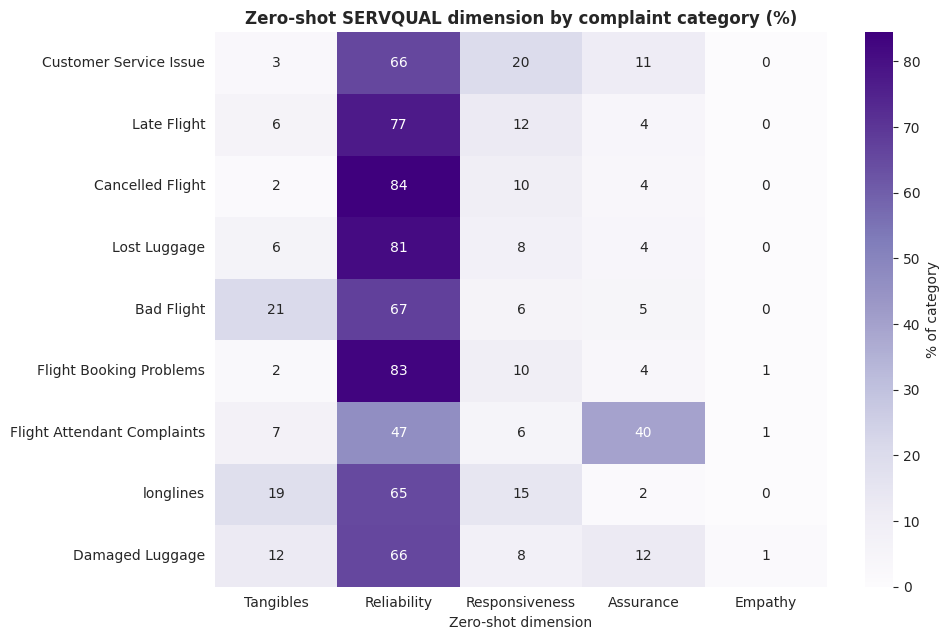

,ZS mentah (%),ZS terkalibrasi (%),Pemetaan (%)
Tangibles,5.70,22.68,0.00
Reliability,71.65,25.41,48.00
Responsiveness,13.51,19.37,38.72
Assurance,8.91,17.29,13.28
Empathy,0.24,15.25,0.00


Kappa pemetaan vs ZS mentah      : 0.1359
Kappa pemetaan vs ZS terkalibrasi: 0.0845 (sangat lemah)


,n,Dimensi pemetaan,% ZS kalibrasi setuju,Dimensi ZS kalibrasi terbanyak,% terbanyak
negativereason,,,,,
Customer Service Issue,2882,Responsiveness,25.64,Responsiveness,25.64
Late Flight,1650,Reliability,30.30,Reliability,30.30
Cancelled Flight,828,Reliability,28.99,Reliability,28.99
Lost Luggage,718,Reliability,31.62,Reliability,31.62
Bad Flight,574,Assurance,8.89,Tangibles,50.70
Flight Booking Problems,523,Reliability,39.01,Reliability,39.01
Flight Attendant Complaints,475,Assurance,53.05,Assurance,53.05
longlines,177,Responsiveness,20.90,Tangibles,46.89
Damaged Luggage,73,Reliability,10.96,Tangibles,43.84


In [34]:
def tafsir_kappa(k):   # Landis & Koch (1977)
    return ('buruk' if k < 0 else 'sangat lemah' if k <= .20 else 'lemah' if k <= .40 else
            'sedang' if k <= .60 else 'substansial' if k <= .80 else 'hampir sempurna')

pasangan = [('dim_mapping', 'zs_dim', 'Pemetaan kategori (manusia) vs zero-shot'),
            ('dim_pred', 'zs_dim', 'Pemetaan dari cat_pred (SVM) vs zero-shot'),
            ('dim_mapping', 'dim_pred', 'Pemetaan manusia vs cat_pred (SVM)')]
kappa_tab = pd.DataFrame([{'Perbandingan': ket, "Cohen's kappa": round(cohen_kappa_score(neg[a], neg[b]), 4),
                           '% sama': round((neg[a] == neg[b]).mean() * 100, 2),
                           'Tafsiran': tafsir_kappa(cohen_kappa_score(neg[a], neg[b]))}
                          for a, b, ket in pasangan]).set_index('Perbandingan')
display(simpan_tabel(kappa_tab, 't5_kappa'))

silang = pd.crosstab(neg['dim_mapping'], neg['zs_dim'], margins=True,
                     rownames=['Pemetaan'], colnames=['Zero-shot']).reindex(columns=nama_dim + ['All'], fill_value=0)
display(simpan_tabel(silang, 't5_tabel_silang_mapping_vs_zs'))

per_kat = neg.groupby('negativereason').apply(lambda g: pd.Series({
    'n': len(g), 'Dimensi pemetaan': g['dim_mapping'].iloc[0],
    '% ZS setuju': (g['zs_dim'] == g['dim_mapping']).mean() * 100,
    'Dimensi ZS terbanyak': g['zs_dim'].mode().iloc[0],
    '% ZS terbanyak': g['zs_dim'].value_counts(normalize=True).iloc[0] * 100,
    'Rata-rata keyakinan ZS': g['zs_conf'].mean()})).sort_values('n', ascending=False).round(2)
display(simpan_tabel(per_kat, 't5_per_kategori'))

pct = pd.crosstab(neg['negativereason'], neg['zs_dim'], normalize='index').reindex(columns=nama_dim, fill_value=0) * 100
plt.figure(figsize=(10, 6.5))
sns.heatmap(pct.loc[per_kat.index], annot=True, fmt='.0f', cmap='Purples', cbar_kws={'label': '% of category'})
plt.title('Zero-shot SERVQUAL dimension by complaint category (%)'); plt.xlabel('Zero-shot dimension'); plt.ylabel('')
simpan_gambar('g5_zeroshot_per_kategori')

catat_angka('Tahap5_kappa_mapping_vs_ZS', kappa_tab.iloc[0]["Cohen's kappa"])

# --- Kalibrasi prior ---
# Zero-shot mentah condong ke Reliability untuk hampir semua teks (definisinya cocok dengan keluhan apa pun).
# Skor tiap label dibagi rata-rata skornya di seluruh korpus, lalu dinormalisasi ulang, sehingga yang
# dibaca adalah "label ini lebih cocok dari biasanya" (bukan kecocokan absolut).
P = neg[kol_skor].values
P_cal = P / P.mean(axis=0, keepdims=True)
P_cal = P_cal / P_cal.sum(axis=1, keepdims=True)
neg['zs_dim_cal'] = np.array(nama_dim)[P_cal.argmax(1)]

dist_zs = pd.DataFrame({'ZS mentah (%)': neg['zs_dim'].value_counts(normalize=True) * 100,
                        'ZS terkalibrasi (%)': neg['zs_dim_cal'].value_counts(normalize=True) * 100,
                        'Pemetaan (%)': neg['dim_mapping'].value_counts(normalize=True) * 100}
                       ).reindex(nama_dim).fillna(0).round(2)
display(simpan_tabel(dist_zs, 't5_distribusi_zs_mentah_vs_kalibrasi'))
kappa_cal = cohen_kappa_score(neg['dim_mapping'], neg['zs_dim_cal'])
kappa_mentah = kappa_tab.iloc[0]["Cohen's kappa"]
print(f'Kappa pemetaan vs ZS mentah      : {kappa_mentah:.4f}')
print(f'Kappa pemetaan vs ZS terkalibrasi: {kappa_cal:.4f} ({tafsir_kappa(kappa_cal)})')

per_kat_cal = neg.groupby('negativereason').apply(lambda g: pd.Series({
    'n': len(g), 'Dimensi pemetaan': g['dim_mapping'].iloc[0],
    '% ZS kalibrasi setuju': (g['zs_dim_cal'] == g['dim_mapping']).mean() * 100,
    'Dimensi ZS kalibrasi terbanyak': g['zs_dim_cal'].mode().iloc[0],
    '% terbanyak': g['zs_dim_cal'].value_counts(normalize=True).iloc[0] * 100})).sort_values('n', ascending=False).round(2)
display(simpan_tabel(per_kat_cal, 't5_per_kategori_kalibrasi'))

PETA_ZS = per_kat_cal['Dimensi ZS kalibrasi terbanyak'].to_dict()    # dipakai skenario F
if len(set(PETA_ZS.values())) == 1:
    print('PERINGATAN: skenario F memetakan semua kategori ke satu dimensi; abaikan F saat menafsirkan stabilitas.')
catat_angka('Tahap5_kappa_mapping_vs_ZS_kalibrasi', round(kappa_cal, 4))

> **Posisi zero-shot dalam naskah.** Validasi pakar tidak dilakukan. Zero-shot **bukan pengganti pakar**; perannya pemeriksaan independen dari mesin. Kesepakatan tingkat tweet rendah (kappa di atas), tetapi tabel per kategori menunjukkan pola yang informatif: kategori operasional disepakati tinggi, kategori yang secara konseptual ambigu (Customer Service Issue, Bad Flight, longlines) tidak. Ketiadaan validasi pakar ditulis sebagai keterbatasan, diimbangi analisis sensitivitas (5.2) dan aturan konsensus (6.2).

### 5.2 Analisis sensitivitas pemetaan (skenario A–F)

Dijalankan dua kali: kategori dari `negativereason` (label manusia) dan dari `cat_pred` (SVM). Untuk tiap skenario dihitung dimensi terbanyak per maskapai dan selisihnya dengan dimensi kedua.

> **Periksa:** definisi skenario di bawah adalah alternatif pemetaan yang paling bisa diperdebatkan. Jika dokumen Panduan Validasi memakai definisi A–F yang berbeda, **cukup ubah isi `SKENARIO`**; sisa kode tidak perlu disentuh.

In [35]:
SKENARIO = {
    'A': ('Baseline (pemetaan revisi)', {}),
    'B': ('Bad Flight -> Tangibles', {'Bad Flight': 'Tangibles'}),
    'C': ('Customer Service Issue -> Empathy', {'Customer Service Issue': 'Empathy'}),
    'D': ('Flight Attendant Complaints -> Empathy', {'Flight Attendant Complaints': 'Empathy'}),
    'E': ('Flight Booking Problems -> Responsiveness', {'Flight Booking Problems': 'Responsiveness'}),
    'F': ('Mayoritas zero-shot terkalibrasi per kategori', 'ZS'),
}

def peta_skenario(ubah):
    p = dict(SERVQUAL_MAP)
    p.update(PETA_ZS if ubah == 'ZS' else ubah)
    return p

def sensitivitas(df, kol_kat):
    baris = []
    for kode, (ket, ubah) in SKENARIO.items():
        d = df[kol_kat].map(peta_skenario(ubah))
        tab = pd.crosstab(df['airline'], d, normalize='index') * 100
        tab.loc['Semua maskapai'] = d.value_counts(normalize=True) * 100
        for m in MASKAPAI + ['Semua maskapai']:
            r = tab.loc[m].sort_values(ascending=False)
            baris.append({'Sumber kategori': kol_kat, 'Skenario': kode, 'Keterangan': ket, 'Maskapai': m,
                          'Dimensi teratas': r.index[0], '% teratas': round(r.iloc[0], 2),
                          'Dimensi kedua': r.index[1] if len(r) > 1 else '-',
                          '% kedua': round(r.iloc[1], 2) if len(r) > 1 else 0,
                          'Selisih (pp)': round(r.iloc[0] - (r.iloc[1] if len(r) > 1 else 0), 2)})
    return pd.DataFrame(baris)

for kol in ['negativereason', 'cat_pred']:
    sens = sensitivitas(neg, kol)
    simpan_tabel(sens, f't5_sensitivitas_{kol}', index=False)
    top = sens.pivot(index='Maskapai', columns='Skenario', values='Dimensi teratas')
    gap = sens.pivot(index='Maskapai', columns='Skenario', values='Selisih (pp)')
    top['Stabil A-F?'] = np.where(top.nunique(axis=1) == 1, 'Ya', 'Tidak')
    gabung = top.copy()
    for s in SKENARIO:
        gabung[s] = top[s] + ' (' + gap[s].map('{:.1f}'.format) + ')'
    print(f'\n=== Sumber kategori: {kol} | sel = dimensi teratas (selisih pp dengan dimensi kedua) ===')
    display(simpan_tabel(gabung.reindex(MASKAPAI + ['Semua maskapai']), f't5_sensitivitas_ringkas_{kol}'))
    catat_angka(f'Tahap5_maskapai_stabil_A-F_{kol}', int((top.loc[MASKAPAI, 'Stabil A-F?'] == 'Ya').sum()))
print('\nPemetaan skenario F (mayoritas ZS):', PETA_ZS)


=== Sumber kategori: negativereason | sel = dimensi teratas (selisih pp dengan dimensi kedua) ===


Skenario,A,B,C,D,E,F,Stabil A-F?
Maskapai,,,,,,,
United,Reliability (18.2),Reliability (18.2),Reliability (20.4),Reliability (18.2),Reliability (5.5),Reliability (19.4),Ya
US Airways,Reliability (3.5),Reliability (3.5),Reliability (6.0),Reliability (3.5),Responsiveness (8.6),Reliability (5.4),Tidak
American,Responsiveness (2.1),Responsiveness (2.1),Empathy (0.1),Responsiveness (2.1),Responsiveness (16.9),Responsiveness (0.8),Tidak
Southwest,Reliability (5.8),Reliability (5.8),Reliability (8.7),Reliability (5.8),Responsiveness (6.0),Reliability (7.3),Tidak
JetBlue,Reliability (28.4),Reliability (28.4),Reliability (30.2),Reliability (28.4),Reliability (16.9),Reliability (28.8),Ya
Virgin America,Reliability (5.7),Reliability (5.7),Reliability (7.5),Reliability (5.7),Responsiveness (29.6),Reliability (5.0),Tidak
Semua maskapai,Reliability (9.3),Reliability (9.3),Reliability (11.5),Reliability (9.3),Responsiveness (4.0),Reliability (10.6),Tidak



=== Sumber kategori: cat_pred | sel = dimensi teratas (selisih pp dengan dimensi kedua) ===


Skenario,A,B,C,D,E,F,Stabil A-F?
Maskapai,,,,,,,
United,Reliability (24.2),Reliability (24.2),Reliability (27.3),Reliability (24.2),Reliability (7.9),Reliability (26.1),Ya
US Airways,Reliability (8.0),Reliability (8.0),Reliability (11.1),Reliability (8.0),Responsiveness (5.2),Reliability (10.5),Tidak
American,Reliability (7.4),Reliability (7.4),Reliability (10.4),Reliability (7.4),Responsiveness (8.5),Reliability (9.5),Tidak
Southwest,Reliability (19.6),Reliability (19.6),Reliability (22.6),Reliability (19.6),Reliability (3.2),Reliability (21.4),Ya
JetBlue,Reliability (25.9),Reliability (25.9),Reliability (29.3),Reliability (25.9),Reliability (12.9),Reliability (27.9),Ya
Virgin America,Reliability (30.2),Reliability (30.2),Reliability (32.7),Reliability (30.2),Responsiveness (21.4),Reliability (30.8),Tidak
Semua maskapai,Reliability (16.2),Reliability (16.2),Reliability (19.2),Reliability (16.2),Reliability (0.4),Reliability (18.3),Ya



Pemetaan skenario F (mayoritas ZS): {'Customer Service Issue': 'Responsiveness', 'Late Flight': 'Reliability', 'Cancelled Flight': 'Reliability', 'Lost Luggage': 'Reliability', 'Bad Flight': 'Tangibles', 'Flight Booking Problems': 'Reliability', 'Flight Attendant Complaints': 'Assurance', 'longlines': 'Tangibles', 'Damaged Luggage': 'Tangibles'}


---
# TAHAP 6 — Uji Statistik

Peringkat komposit versi lama (rata-rata peringkat tiga indikator, termasuk `airline_sentiment_confidence`) **dihapus**. Penggantinya proporsi tweet negatif per maskapai dengan Wilson 95% CI. Analisis utama memakai `DIM = "dim_pred"`, lalu diulang dengan `"dim_label"` sebagai pembanding.

,n,negatif,% negatif,Wilson CI low,Wilson CI high
airline,,,,,
US Airways,2900,2259,77.90,76.35,79.37
American,2586,1862,72.00,70.24,73.70
United,3798,2631,69.27,67.79,70.72
Southwest,2399,1185,49.40,47.40,51.40
JetBlue,2203,953,43.26,41.20,45.34
Virgin America,502,181,36.06,31.98,40.35


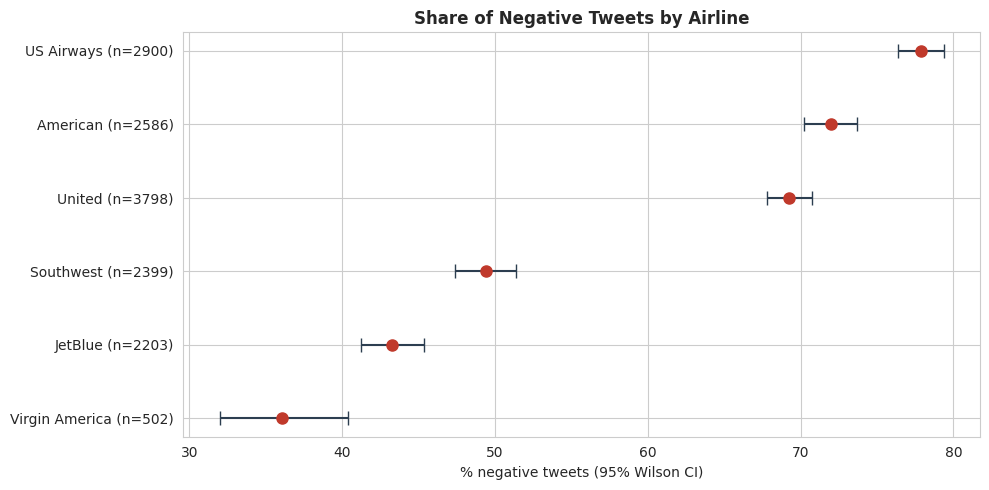

Chi-square maskapai x negatif: χ²(5) = 1145.82, p = 1.6e-245, Cramér's V = 0.282, sel harapan < 5: 0


In [36]:
DIM = 'dim_pred'              # utama
DIM_PEMBANDING = 'dim_label'  # pembanding (label manusia)

def cramers_v(chi2, n, r, k):
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# --- Proporsi negatif per maskapai (Wilson CI), basis: semua tweet termasuk netral ---
pn = data.groupby('airline')['airline_sentiment'].agg(n='size', negatif=lambda s: (s == 'negative').sum())
lo, hi = proportion_confint(pn['negatif'], pn['n'], alpha=0.05, method='wilson')
pn['% negatif'] = pn['negatif'] / pn['n'] * 100
pn['Wilson CI low'], pn['Wilson CI high'] = lo * 100, hi * 100
pn = pn.sort_values('% negatif', ascending=False).round(2)
display(simpan_tabel(pn, 't6_proporsi_negatif_wilson'))

plt.figure(figsize=(10, 5))
plt.errorbar(pn['% negatif'], range(len(pn)), xerr=[pn['% negatif'] - pn['Wilson CI low'], pn['Wilson CI high'] - pn['% negatif']],
             fmt='o', color='#c0392b', ecolor='#2c3e50', capsize=5, markersize=8)
plt.yticks(range(len(pn)), [f'{m} (n={n})' for m, n in zip(pn.index, pn['n'])]); plt.gca().invert_yaxis()
plt.xlabel('% negative tweets (95% Wilson CI)'); plt.title('Share of Negative Tweets by Airline')
simpan_gambar('g6_proporsi_negatif_wilson')

# --- Chi-square maskapai x negatif ---
tab_neg = pd.crosstab(data['airline'], data['airline_sentiment'] == 'negative')
chi2, p, dof, exp = chi2_contingency(tab_neg)
V = cramers_v(chi2, tab_neg.values.sum(), *tab_neg.shape)
print(f'Chi-square maskapai x negatif: χ²({dof}) = {chi2:.2f}, p = {p:.3g}, Cramér\'s V = {V:.3f}, '
      f'sel harapan < 5: {(exp < 5).sum()}')
catat_angka('Tahap6_chi2_maskapai_x_negatif', f'chi2({dof})={chi2:.2f}, p={p:.3g}, V={V:.3f}')

### 6.1 H1: maskapai × dimensi SERVQUAL (chi-square, Cramér's V, residual terstandar, sel harapan < 5)


=== H1 | dim_pred | data penuh ===


dim_pred,Assurance,Reliability,Responsiveness
airline,,,
United,4.33,2.94,-6.31
US Airways,-2.71,-3.28,5.46
American,-4.38,-2.50,5.87
Southwest,-1.21,1.59,-0.78
JetBlue,3.97,1.43,-4.45
Virgin America,1.77,1.16,-2.53


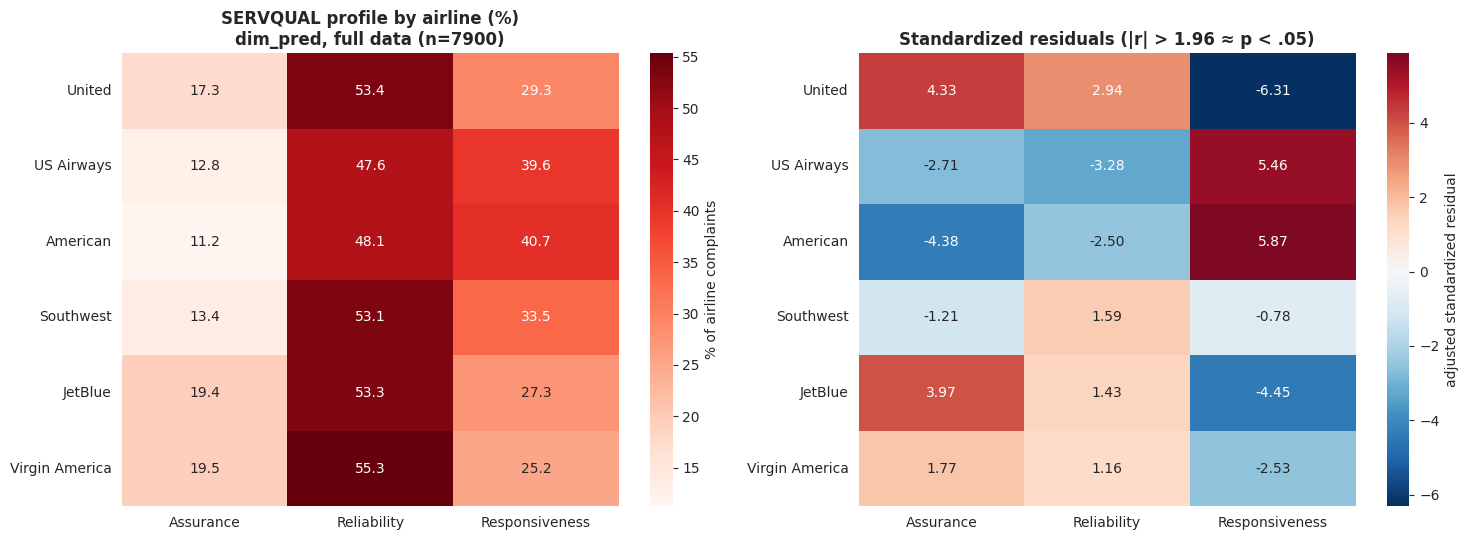

Bootstrap selisih dua dimensi teratas per maskapai (dim_pred, penuh):


,n,Dimensi 1,% 1,Dimensi 2,% 2,Selisih (pp),CI low,CI high,P(selisih > 0)
Maskapai,,,,,,,,,
United,2252,Reliability,53.419,Responsiveness,29.263,24.156,20.693,27.577,1.0
US Airways,2015,Reliability,47.643,Responsiveness,39.603,8.040,4.020,12.208,1.0
American,1680,Reliability,48.095,Responsiveness,40.655,7.440,2.738,11.964,1.0
Southwest,1026,Reliability,53.119,Responsiveness,33.528,19.591,13.938,25.146,1.0
JetBlue,768,Reliability,53.255,Responsiveness,27.344,25.911,19.922,31.771,1.0
Virgin America,159,Reliability,55.346,Responsiveness,25.157,30.189,16.965,43.396,1.0



=== H1 | dim_label | data penuh ===


dim_label,Assurance,Reliability,Responsiveness
airline,,,
United,6.17,2.95,-7.32
US Airways,-3.09,-1.97,4.17
American,-4.87,-3.60,7.08
Southwest,-0.81,-0.90,1.49
JetBlue,2.46,4.74,-6.58
Virgin America,0.68,-0.69,0.24


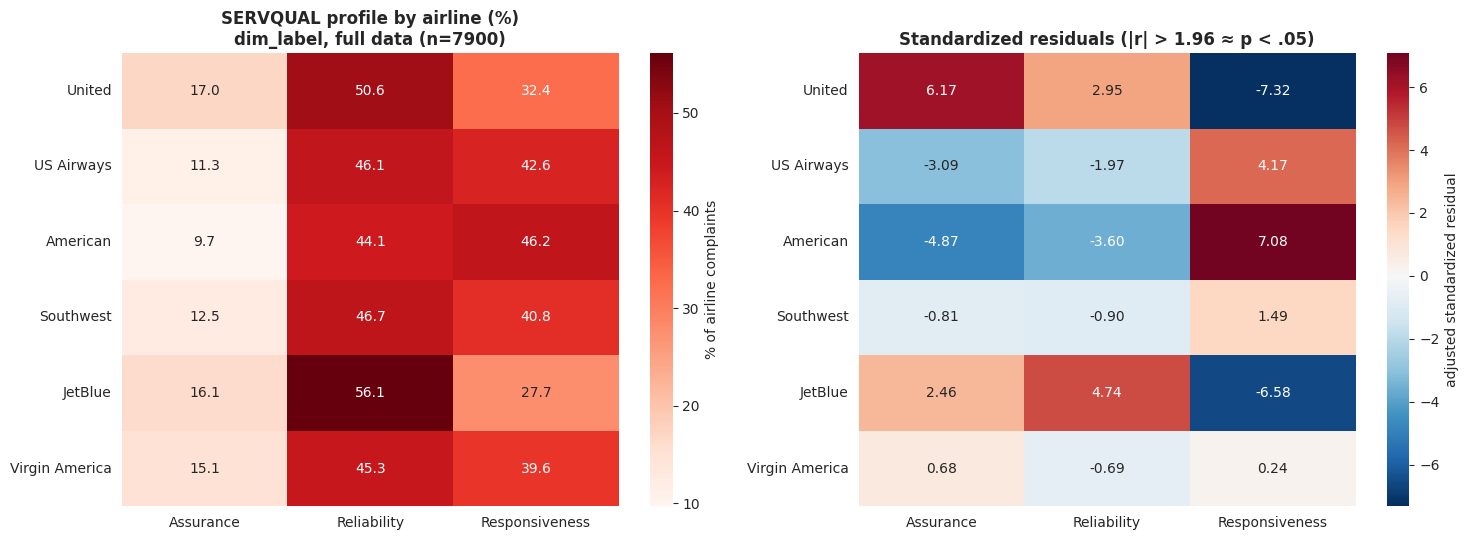

Bootstrap selisih dua dimensi teratas per maskapai (dim_label, penuh):


,n,Dimensi 1,% 1,Dimensi 2,% 2,Selisih (pp),CI low,CI high,P(selisih > 0)
Maskapai,,,,,,,,,
United,2252,Reliability,50.622,Responsiveness,32.371,18.250,14.520,21.936,1.000
US Airways,2015,Reliability,46.104,Responsiveness,42.630,3.474,-0.546,7.593,0.956
American,1680,Responsiveness,46.190,Reliability,44.107,2.083,-2.321,6.726,0.810
Southwest,1026,Reliability,46.686,Responsiveness,40.838,5.848,0.195,11.501,0.978
JetBlue,768,Reliability,56.120,Responsiveness,27.734,28.385,22.005,34.766,1.000
Virgin America,159,Reliability,45.283,Responsiveness,39.623,5.660,-8.176,20.126,0.768


,Kolom dimensi,Data,n,chi2,df,p-value,Cramér's V,Sel harapan < 5,% sel < 5,Harapan minimum
0,dim_pred,Penuh,7900,123.941,10,8.009126e-22,0.0886,0,0.0,23.21
1,dim_pred,common_days (3 hari),4246,91.496,10,2.704073e-15,0.1038,0,0.0,8.10
2,dim_pred,1 tweet/pengguna,4212,75.910,10,3.162863e-12,0.0949,0,0.0,18.37
3,dim_label,Penuh,7900,153.526,10,7.006397e-28,0.0986,0,0.0,21.11
4,dim_label,common_days (3 hari),4246,118.706,10,9.259785e-21,0.1182,0,0.0,7.32
5,dim_label,1 tweet/pengguna,4212,98.535,10,1.070126e-16,0.1082,0,0.0,16.95


In [37]:
def uji_h1(df, kol_dim):
    tab = pd.crosstab(df['airline'], df[kol_dim]).reindex(MASKAPAI).fillna(0).astype(int)
    tab = tab.loc[:, tab.sum() > 0]
    chi2, p, dof, exp = chi2_contingency(tab)
    n = tab.values.sum()
    rp, cp = tab.sum(1).values[:, None] / n, tab.sum(0).values[None, :] / n
    resid = (tab.values - exp) / np.sqrt(exp * (1 - rp) * (1 - cp))   # adjusted standardized residual
    ringkas = {'n': int(n), 'chi2': round(chi2, 3), 'df': int(dof), 'p-value': float(p),
               "Cramér's V": round(cramers_v(chi2, n, *tab.shape), 4),
               'Sel harapan < 5': int((exp < 5).sum()), '% sel < 5': round((exp < 5).mean() * 100, 1),
               'Harapan minimum': round(exp.min(), 2)}
    return ringkas, tab, pd.DataFrame(resid, index=tab.index, columns=tab.columns).round(2), \
           pd.DataFrame(exp, index=tab.index, columns=tab.columns).round(2)

def gambar_h1(tab, resid, judul, nama):
    pct = tab.div(tab.sum(1), axis=0) * 100
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.heatmap(pct, annot=True, fmt='.1f', cmap='Reds', ax=ax[0], cbar_kws={'label': '% of airline complaints'})
    ax[0].set_title(f'SERVQUAL profile by airline (%)\n{judul}'); ax[0].set_ylabel(''); ax[0].set_xlabel('')
    sns.heatmap(resid, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[1],
                cbar_kws={'label': 'adjusted standardized residual'})
    ax[1].set_title('Standardized residuals (|r| > 1.96 ≈ p < .05)'); ax[1].set_ylabel(''); ax[1].set_xlabel('')
    simpan_gambar(nama)

def boot_selisih_dua_teratas(df, kol_dim, B=N_BOOT, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); baris = []
    for m in MASKAPAI:
        d = df.loc[df['airline'] == m, kol_dim].to_numpy(dtype=object)
        vc = pd.Series(d).value_counts(normalize=True)
        if len(vc) < 2: continue
        a, b = vc.index[0], vc.index[1]
        ia, ib = (d == a), (d == b)
        sel = np.empty(B)
        for s in range(0, B, 250):                        # dicicil agar hemat memori
            ix = rng.integers(0, len(d), size=(min(250, B - s), len(d)))
            sel[s:s + len(ix)] = (ia[ix].mean(1) - ib[ix].mean(1)) * 100
        baris.append({'Maskapai': m, 'n': len(d), 'Dimensi 1': a, '% 1': vc[a] * 100, 'Dimensi 2': b, '% 2': vc[b] * 100,
                      'Selisih (pp)': (vc[a] - vc[b]) * 100, 'CI low': np.percentile(sel, 2.5),
                      'CI high': np.percentile(sel, 97.5), 'P(selisih > 0)': (sel > 0).mean()})
    return pd.DataFrame(baris).set_index('Maskapai').round(3)

neg_common = neg[neg['tanggal'].isin(common_days)]
neg_user1 = neg[neg['tweet_id'].isin(df_user1['tweet_id'])]
SUBSET = [('Penuh', 'penuh', neg), (f'common_days ({len(common_days)} hari)', 'commondays', neg_common),
          ('1 tweet/pengguna', 'user1', neg_user1)]

rekap_h1 = []
HASIL_H1 = {}
for kol in [DIM, DIM_PEMBANDING]:
    for nama_sub, kode_sub, df_sub in SUBSET:
        r, tab, resid, exp = uji_h1(df_sub, kol)
        rekap_h1.append({'Kolom dimensi': kol, 'Data': nama_sub, **r})
        slug = f'{kol}_{kode_sub}'
        simpan_tabel(tab, f't6_h1_frekuensi_{slug}'); simpan_tabel(resid, f't6_h1_residual_{slug}')
        simpan_tabel(exp, f't6_h1_harapan_{slug}')
        if nama_sub == 'Penuh':
            print(f'\n=== H1 | {kol} | data penuh ===')
            display(resid)
            gambar_h1(tab, resid, f'{kol}, full data (n={r["n"]})', f'g6_h1_{kol}_penuh')
        bs = boot_selisih_dua_teratas(df_sub, kol)
        HASIL_H1[(kol, kode_sub)] = {'tab': tab, 'resid': resid, 'bs': bs}
        simpan_tabel(bs, f't6_bootstrap_selisih_dua_teratas_{slug}')
        if nama_sub == 'Penuh':
            print(f'Bootstrap selisih dua dimensi teratas per maskapai ({kol}, penuh):')
            display(bs)

rekap_h1 = pd.DataFrame(rekap_h1)
display(simpan_tabel(rekap_h1, 't6_h1_rekap', index=False))
r0 = rekap_h1.iloc[0]; v0 = r0["Cramér's V"]
catat_angka('Tahap6_H1_utama', f"chi2({r0['df']})={r0['chi2']}, p={r0['p-value']:.3g}, V={v0}, n={r0['n']}")

### 6.2 Konsensus dua sumber label (dasar penulisan temuan)

Keputusan penulisan: **klaim substantif hanya ditulis bila muncul di kedua sumber label**, yaitu `dim_pred` (SVM) dan `dim_label` (manusia). Alasannya, SVM kategori menggeser distribusi (Reliability naik, Responsiveness turun) sehingga beberapa hasil per maskapai berbeda antar sumber. Pola yang muncul di keduanya tidak bergantung pada pilihan sumber label.

Dua jenis klaim diperiksa:

1. **Residual terstandar**: sel maskapai × dimensi dinyatakan *lebih tinggi* atau *lebih rendah* dari harapan bila |r| > 1,96 **di kedua sumber** dengan arah yang sama. Ketahanannya dicek lagi di `common_days` dan data 1 tweet/pengguna.
2. **Dimensi terbesar per maskapai**: dinyatakan jelas bila kedua sumber menunjuk dimensi yang sama **dan** CI bootstrap selisih dengan dimensi kedua tidak mencakup nol di keduanya.

,Maskapai,Dimensi,r SVM (dim_pred),r manusia (dim_label),r RoBERTa (pembanding),RoBERTa searah?,Status,Bertahan di,Jumlah subset bertahan
0,United,Assurance,4.33,6.17,4.54,Ya,Konsensus: lebih tinggi,"common_days, 1 tweet/pengguna",2/2
1,United,Reliability,2.94,2.95,2.19,Ya,Konsensus: lebih tinggi,"common_days, 1 tweet/pengguna",2/2
2,United,Responsiveness,-6.31,-7.32,-6.04,Ya,Konsensus: lebih rendah,"common_days, 1 tweet/pengguna",2/2
3,US Airways,Assurance,-2.71,-3.09,-3.16,Ya,Konsensus: lebih rendah,,0/2
4,US Airways,Reliability,-3.28,-1.97,-3.11,Ya,Konsensus: lebih rendah,,0/2
5,US Airways,Responsiveness,5.46,4.17,5.92,Ya,Konsensus: lebih tinggi,"common_days, 1 tweet/pengguna",2/2
6,American,Assurance,-4.38,-4.87,-3.09,Ya,Konsensus: lebih rendah,"common_days, 1 tweet/pengguna",2/2
7,American,Reliability,-2.50,-3.60,-3.38,Ya,Konsensus: lebih rendah,common_days,1/2
8,American,Responsiveness,5.87,7.08,6.16,Ya,Konsensus: lebih tinggi,"common_days, 1 tweet/pengguna",2/2
9,Southwest,Assurance,-1.21,-0.81,-2.15,-,Tidak berbeda dari harapan,-,-


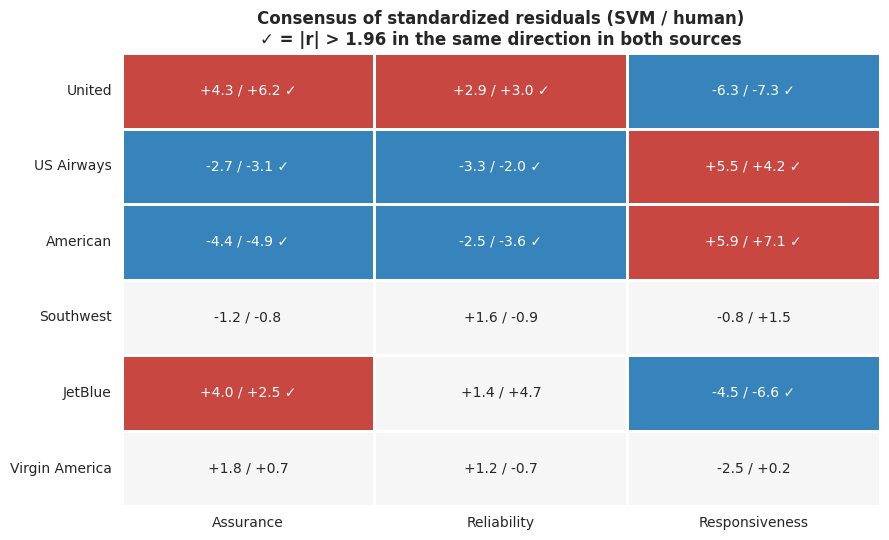

,Maskapai,Dimensi 1 (SVM),% SVM,Selisih SVM [CI],Dimensi 1 (manusia),% manusia,Selisih manusia [CI],Status,Dimensi 1 (RoBERTa),RoBERTa sepakat?
0,United,Reliability,53.4,24.2 [20.7; 27.6],Reliability,50.6,18.2 [14.5; 21.9],Konsensus jelas,Reliability,Ya
1,US Airways,Reliability,47.6,8.0 [4.0; 12.2],Reliability,46.1,3.5 [-0.5; 7.6],"Sama, tapi selisih belum jelas",Reliability,-
2,American,Reliability,48.1,7.4 [2.7; 12.0],Responsiveness,46.2,2.1 [-2.3; 6.7],Sumber berbeda,Reliability,-
3,Southwest,Reliability,53.1,19.6 [13.9; 25.1],Reliability,46.7,5.8 [0.2; 11.5],Konsensus jelas,Reliability,Ya
4,JetBlue,Reliability,53.3,25.9 [19.9; 31.8],Reliability,56.1,28.4 [22.0; 34.8],Konsensus jelas,Reliability,Ya
5,Virgin America,Reliability,55.3,30.2 [17.0; 43.4],Reliability,45.3,5.7 [-8.2; 20.1],"Sama, tapi selisih belum jelas",Reliability,-


,SVM (%),Manusia (%),Peringkat SVM,Peringkat manusia
Reliability,50.80,48.00,1,1
Responsiveness,34.61,38.72,2,2
Assurance,14.59,13.28,3,3


KLAIM YANG DIDUKUNG KEDUA SUMBER LABEL:


,Jenis,Maskapai,Klaim,Bertahan di subset
0,Gabungan,Semua,Reliability adalah dimensi terbesar (50.8% SVM...,-
1,Dimensi terbesar,United,"Reliability dimensi terbesar (53.4% / 50.6%), ...",-
2,Dimensi terbesar,Southwest,"Reliability dimensi terbesar (53.1% / 46.7%), ...",-
3,Dimensi terbesar,JetBlue,"Reliability dimensi terbesar (53.3% / 56.1%), ...",-
4,Residual,United,porsi keluhan Assurance lebih tinggi dari yang...,2/2
5,Residual,United,porsi keluhan Reliability lebih tinggi dari ya...,2/2
6,Residual,United,porsi keluhan Responsiveness lebih rendah dari...,2/2
7,Residual,US Airways,porsi keluhan Assurance lebih rendah dari yang...,0/2
8,Residual,US Airways,porsi keluhan Reliability lebih rendah dari ya...,0/2
9,Residual,US Airways,porsi keluhan Responsiveness lebih tinggi dari...,2/2



Jangan menulis "dimensi terbesar" secara tegas untuk: US Airways, American, Virgin America

Pemeriksaan model: 11/11 sel residual konsensus tetap searah dan signifikan bila memakai RoBERTa.


In [38]:
Z_KRITIS = 1.96
SUB_CEK = [('commondays', 'common_days'), ('user1', '1 tweet/pengguna')]

def arah_signifikan(r):
    return np.where(r > Z_KRITIS, 1, np.where(r < -Z_KRITIS, -1, 0))

def status_sel(kode_sub, m, d):
    ra = HASIL_H1[(DIM, kode_sub)]['resid']; rb = HASIL_H1[(DIM_PEMBANDING, kode_sub)]['resid']
    if m not in ra.index or d not in ra.columns or m not in rb.index or d not in rb.columns:
        return np.nan, np.nan, 0
    a, b = ra.loc[m, d], rb.loc[m, d]
    sa, sb = int(arah_signifikan(a)), int(arah_signifikan(b))
    return a, b, (sa if sa == sb and sa != 0 else 0)

# Pemeriksaan tambahan: apakah kesimpulan berubah bila SVM diganti transformer?
_, _, resid_trf, _ = uji_h1(neg, 'dim_pred_trf')
bs_trf = boot_selisih_dua_teratas(neg, 'dim_pred_trf')

ra0 = HASIL_H1[(DIM, 'penuh')]['resid']
dims_sama = [d for d in ra0.columns if d in HASIL_H1[(DIM_PEMBANDING, 'penuh')]['resid'].columns]
baris_r, mat_kode, mat_teks = [], pd.DataFrame(0, index=MASKAPAI, columns=dims_sama), pd.DataFrame('', index=MASKAPAI, columns=dims_sama)
for m in MASKAPAI:
    for d in dims_sama:
        a, b, k = status_sel('penuh', m, d)
        sa, sb = int(arah_signifikan(a)), int(arah_signifikan(b))
        if k != 0:
            status = 'Konsensus: lebih tinggi' if k > 0 else 'Konsensus: lebih rendah'
        elif sa != 0 or sb != 0:
            status = 'Hanya satu sumber' if sa * sb >= 0 else 'Berlawanan arah'
        else:
            status = 'Tidak berbeda dari harapan'
        tahan = [nama for kode, nama in SUB_CEK if status_sel(kode, m, d)[2] == k] if k != 0 else []
        rt = resid_trf.loc[m, d] if (m in resid_trf.index and d in resid_trf.columns) else np.nan
        baris_r.append({'Maskapai': m, 'Dimensi': d, 'r SVM (dim_pred)': round(a, 2), 'r manusia (dim_label)': round(b, 2),
                        'r RoBERTa (pembanding)': round(rt, 2),
                        'RoBERTa searah?': ('Ya' if int(arah_signifikan(rt)) == k else 'Tidak') if k != 0 else '-',
                        'Status': status, 'Bertahan di': ', '.join(tahan) if k != 0 else '-',
                        'Jumlah subset bertahan': f'{len(tahan)}/{len(SUB_CEK)}' if k != 0 else '-'})
        mat_kode.loc[m, d] = k
        mat_teks.loc[m, d] = f'{a:+.1f} / {b:+.1f}' + (' ✓' if k != 0 else '')
konsensus_r = pd.DataFrame(baris_r)
display(simpan_tabel(konsensus_r, 't6_konsensus_residual', index=False))

plt.figure(figsize=(9, 5.5))
sns.heatmap(mat_kode, annot=mat_teks.values, fmt='', cmap='RdBu_r', center=0, vmin=-1.5, vmax=1.5, cbar=False,
            linewidths=1, linecolor='white')
plt.title('Consensus of standardized residuals (SVM / human)\n✓ = |r| > 1.96 in the same direction in both sources')
plt.xlabel(''); plt.ylabel('')
simpan_gambar('g6_konsensus_residual')

# --- Dimensi terbesar per maskapai ---
baris_d = []
for m in MASKAPAI:
    a = HASIL_H1[(DIM, 'penuh')]['bs'].reindex([m]).iloc[0]
    b = HASIL_H1[(DIM_PEMBANDING, 'penuh')]['bs'].reindex([m]).iloc[0]
    sama = a['Dimensi 1'] == b['Dimensi 1']
    jelas = (a['CI low'] > 0) and (b['CI low'] > 0)
    status = 'Konsensus jelas' if sama and jelas else ('Sumber berbeda' if not sama else 'Sama, tapi selisih belum jelas')
    baris_d.append({'Maskapai': m, 'Dimensi 1 (SVM)': a['Dimensi 1'], '% SVM': round(a['% 1'], 1),
                    'Selisih SVM [CI]': f"{a['Selisih (pp)']:.1f} [{a['CI low']:.1f}; {a['CI high']:.1f}]",
                    'Dimensi 1 (manusia)': b['Dimensi 1'], '% manusia': round(b['% 1'], 1),
                    'Selisih manusia [CI]': f"{b['Selisih (pp)']:.1f} [{b['CI low']:.1f}; {b['CI high']:.1f}]",
                    'Status': status,
                    'Dimensi 1 (RoBERTa)': bs_trf['Dimensi 1'].get(m, '-'),
                    'RoBERTa sepakat?': ('Ya' if bs_trf['Dimensi 1'].get(m) == a['Dimensi 1'] and bs_trf['CI low'].get(m, -1) > 0
                                         else 'Tidak') if status == 'Konsensus jelas' else '-'})
konsensus_d = pd.DataFrame(baris_d)
display(simpan_tabel(konsensus_d, 't6_konsensus_dimensi_terbesar', index=False))

# --- Gabungan semua maskapai ---
gab = pd.DataFrame({'SVM (%)': neg[DIM].value_counts(normalize=True) * 100,
                    'Manusia (%)': neg[DIM_PEMBANDING].value_counts(normalize=True) * 100}).round(2)
gab['Peringkat SVM'] = gab['SVM (%)'].rank(ascending=False).astype(int)
gab['Peringkat manusia'] = gab['Manusia (%)'].rank(ascending=False).astype(int)
display(simpan_tabel(gab, 't6_konsensus_gabungan'))

# --- Daftar klaim yang boleh ditulis ---
klaim = []
if gab['Peringkat SVM'].idxmin() == gab['Peringkat manusia'].idxmin():
    d0 = gab['Peringkat SVM'].idxmin()
    klaim.append({'Jenis': 'Gabungan', 'Maskapai': 'Semua', 'Klaim':
                  f"{d0} adalah dimensi terbesar ({gab.loc[d0, 'SVM (%)']:.1f}% SVM / {gab.loc[d0, 'Manusia (%)']:.1f}% manusia)",
                  'Bertahan di subset': '-'})
for _, r in konsensus_d[konsensus_d['Status'] == 'Konsensus jelas'].iterrows():
    klaim.append({'Jenis': 'Dimensi terbesar', 'Maskapai': r['Maskapai'], 'Klaim':
                  f"{r['Dimensi 1 (SVM)']} dimensi terbesar ({r['% SVM']}% / {r['% manusia']}%), selisih dengan dimensi kedua jelas di kedua sumber",
                  'Bertahan di subset': '-'})
for _, r in konsensus_r[konsensus_r['Status'].str.startswith('Konsensus')].iterrows():
    arah = 'lebih tinggi' if 'tinggi' in r['Status'] else 'lebih rendah'
    klaim.append({'Jenis': 'Residual', 'Maskapai': r['Maskapai'], 'Klaim':
                  f"porsi keluhan {r['Dimensi']} {arah} dari yang diharapkan (r = {r['r SVM (dim_pred)']:+.2f} SVM / {r['r manusia (dim_label)']:+.2f} manusia)",
                  'Bertahan di subset': r['Jumlah subset bertahan']})
tidak_boleh = konsensus_d[konsensus_d['Status'] != 'Konsensus jelas']['Maskapai'].tolist()
klaim = pd.DataFrame(klaim)
print('KLAIM YANG DIDUKUNG KEDUA SUMBER LABEL:')
display(simpan_tabel(klaim, 't6_konsensus_klaim', index=False))
print('\nJangan menulis "dimensi terbesar" secara tegas untuk:', ', '.join(tidak_boleh) if tidak_boleh else '-')

catat_angka('Tahap6_konsensus_jumlah_sel_residual', int((konsensus_r['Status'].str.startswith('Konsensus')).sum()))
catat_angka('Tahap6_konsensus_maskapai_dimensi_jelas', ', '.join(konsensus_d.loc[konsensus_d['Status'] == 'Konsensus jelas', 'Maskapai']))
catat_angka('Tahap6_maskapai_tanpa_dimensi_terbesar_jelas', ', '.join(tidak_boleh))
n_k = int(konsensus_r['Status'].str.startswith('Konsensus').sum())
n_kt = int((konsensus_r['RoBERTa searah?'] == 'Ya').sum())
print(f'\nPemeriksaan model: {n_kt}/{n_k} sel residual konsensus tetap searah dan signifikan bila memakai RoBERTa.')
catat_angka('Tahap6_konsensus_residual_tetap_dengan_RoBERTa', f'{n_kt}/{n_k}')

### 6.3 Deskriptif pendukung: Pareto kategori (manusia vs SVM)

,negativereason (n),cat_pred (n),negativereason (%),cat_pred (%),Kumulatif negativereason (%),Dimensi
Customer Service Issue,2882,2492,36.48,31.54,36.48,Responsiveness
Late Flight,1650,1595,20.89,20.19,57.37,Reliability
Cancelled Flight,828,895,10.48,11.33,67.85,Reliability
Lost Luggage,718,820,9.09,10.38,76.94,Reliability
Bad Flight,574,649,7.27,8.22,84.21,Assurance
Flight Booking Problems,523,625,6.62,7.91,90.83,Reliability
Flight Attendant Complaints,475,504,6.01,6.38,96.84,Assurance
longlines,177,242,2.24,3.06,99.08,Responsiveness
Damaged Luggage,73,78,0.92,0.99,100.00,Reliability


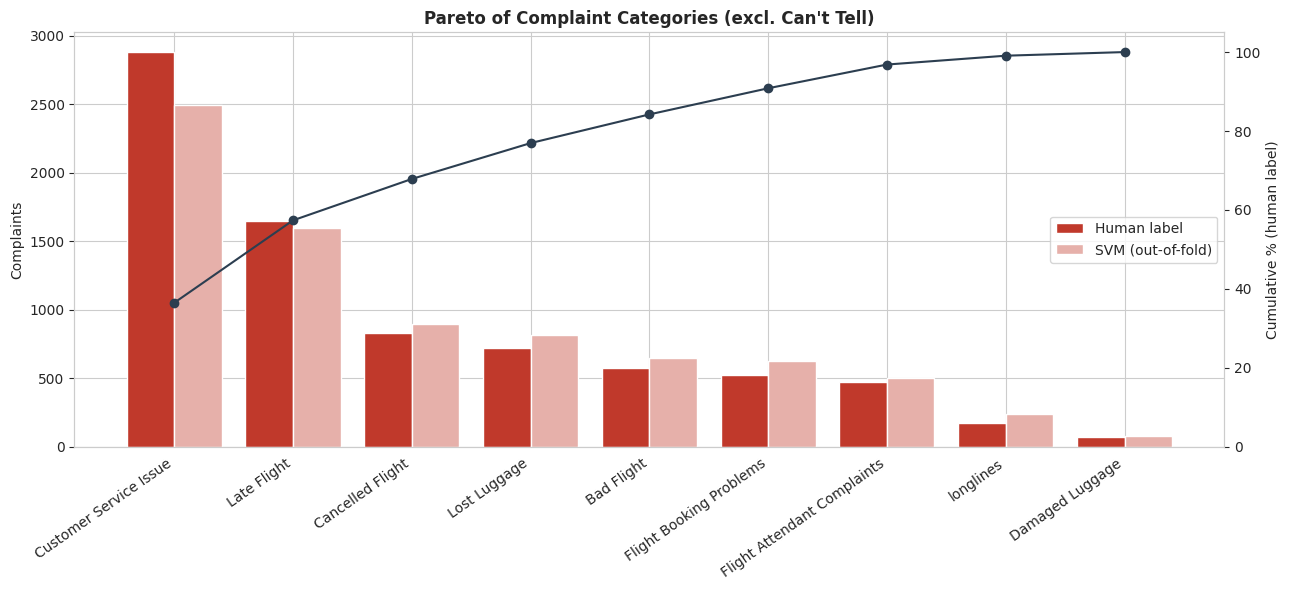

In [39]:
par = pd.DataFrame({'negativereason (n)': neg['negativereason'].value_counts(),
                    'cat_pred (n)': neg['cat_pred'].value_counts()}).fillna(0).astype(int)
par = par.sort_values('negativereason (n)', ascending=False)
for c in ['negativereason', 'cat_pred']:
    par[f'{c} (%)'] = (par[f'{c} (n)'] / par[f'{c} (n)'].sum() * 100).round(2)
par['Kumulatif negativereason (%)'] = par['negativereason (%)'].cumsum().round(2)
par['Dimensi'] = par.index.map(SERVQUAL_MAP)
display(simpan_tabel(par, 't6_pareto_kategori'))

fig, ax1 = plt.subplots(figsize=(13, 6)); x = np.arange(len(par))
ax1.bar(x - 0.2, par['negativereason (n)'], 0.4, label='Human label', color='#c0392b')
ax1.bar(x + 0.2, par['cat_pred (n)'], 0.4, label='SVM (out-of-fold)', color='#e6b0aa')
ax1.set_xticks(x); ax1.set_xticklabels(par.index, rotation=35, ha='right'); ax1.set_ylabel('Complaints')
ax2 = ax1.twinx(); ax2.plot(x, par['Kumulatif negativereason (%)'], 'o-', color='#2c3e50'); ax2.set_ylim(0, 105)
ax2.set_ylabel('Cumulative % (human label)'); ax2.grid(False)
ax1.legend(loc='center right'); ax1.set_title("Pareto of Complaint Categories (excl. Can't Tell)")
simpan_gambar('g6_pareto_kategori')

---
# TAHAP 7 — Intensitas dan Prioritas

`airline_sentiment_confidence` **tidak dipakai lagi** (kolom sudah dibuang di Tahap 1; kolom itu mengukur kesepakatan anotator, bukan kekuatan emosi). Intensitas diganti skor VADER dari teks asli:

$$\text{intensitas} = \frac{1 - \text{compound}}{2} \in [0, 1]$$

Nilai 1 berarti sangat negatif. Pembagian kuadran berbasis median dihapus; prioritas dihitung sebagai **skor = frekuensi (proporsi) × intensitas rata-rata**, lengkap dengan bootstrap 95% CI dan peluang tiap kategori menjadi peringkat 1.

> **Revisi ronde 2.** Peringkat **frekuensi** keluhan adalah hasil utama Tahap 7. Skor frekuensi × intensitas dan semua klaim intensitas (mis. "Cancelled Flight paling intens") diperlakukan sebagai **analisis sensitivitas**, karena VADER lemah sebagai ukuran intensitas (macro F1 0,6185 untuk sentimen biner; Spearman dengan tanda seru 0,03 dan dengan huruf kapital 0,04). Sel di bawah menambahkan peringkat frekuensi murni dengan interval bootstrap peringkat.

,Spearman rho,p-value,n
Fitur,,,
n_seru,0.0276,0.014086,7900
rasio_kapital,0.0368,0.001080,7900


Deskripsi intensitas:
count    7900.0000
mean        0.5128
std         0.2284
min         0.0142
25%         0.3194
50%         0.5000
75%         0.7010
max         0.9787


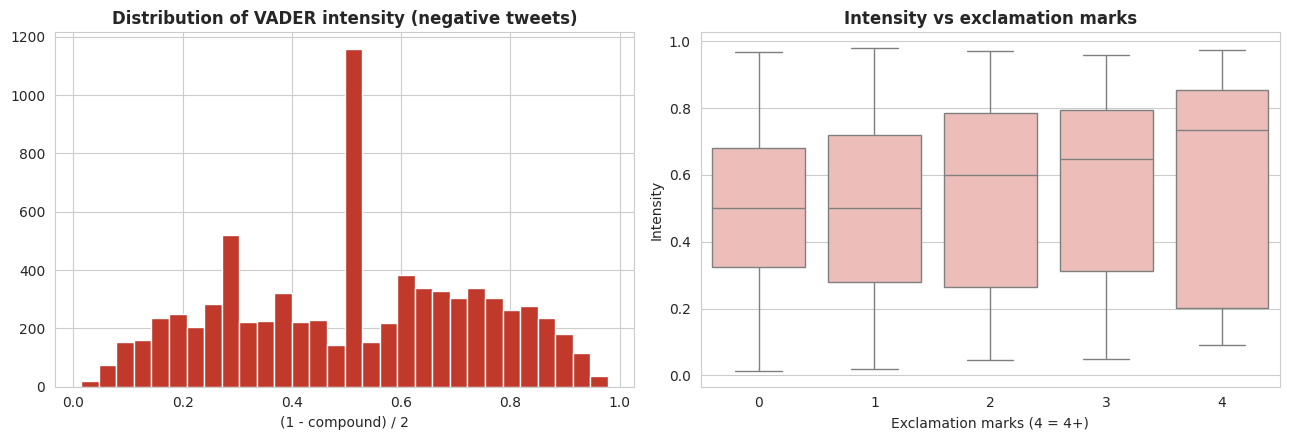

In [40]:
assert 'airline_sentiment_confidence' not in neg.columns
assert CT not in set(neg['negativereason']) and CT not in set(neg['cat_pred']), "Can't Tell ikut terhitung!"

neg['intensitas'] = (1 - neg['vader_compound']) / 2

def fitur_gaya(t):
    t = re.sub(r'@\w+|http\S+|www\.\S+', ' ', html.unescape(str(t)))
    huruf = [c for c in t if c.isalpha()]
    return t.count('!'), (sum(c.isupper() for c in huruf) / len(huruf) if huruf else 0.0)

neg[['n_seru', 'rasio_kapital']] = pd.DataFrame(neg['text'].apply(fitur_gaya).tolist(), index=neg.index)

kor = []
for f in ['n_seru', 'rasio_kapital']:
    rho, p = spearmanr(neg[f], neg['intensitas'])
    kor.append({'Fitur': f, 'Spearman rho': round(rho, 4), 'p-value': p, 'n': len(neg)})
kor = pd.DataFrame(kor).set_index('Fitur')
display(simpan_tabel(kor, 't7_korelasi_gaya_vs_intensitas'))
print('Deskripsi intensitas:'); print(neg['intensitas'].describe().round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(neg['intensitas'], bins=30, color='#c0392b', edgecolor='white')
ax[0].set_title('Distribution of VADER intensity (negative tweets)'); ax[0].set_xlabel('(1 - compound) / 2')
sns.boxplot(x=neg['n_seru'].clip(upper=4), y=neg['intensitas'], ax=ax[1], color='#f5b7b1')
ax[1].set_xlabel('Exclamation marks (4 = 4+)'); ax[1].set_ylabel('Intensity'); ax[1].set_title('Intensity vs exclamation marks')
simpan_gambar('g7_intensitas_vader')
catat_angka('Tahap7_rata_intensitas', round(neg['intensitas'].mean(), 4))


=== Prioritas | kategori dari cat_pred ===


,Peringkat,Dimensi,n,Frekuensi,Frek CI low,Frek CI high,Intensitas,Int CI low,Int CI high,Skor prioritas,Skor CI low,Skor CI high,P(peringkat 1)
Kategori,,,,,,,,,,,,,
Customer Service Issue,1,Responsiveness,2492,0.3154,0.3059,0.3260,0.4968,0.4875,0.5058,0.1567,0.1514,0.1627,1.0
Late Flight,2,Reliability,1595,0.2019,0.1930,0.2106,0.5294,0.5187,0.5405,0.1069,0.1016,0.1122,0.0
Cancelled Flight,3,Reliability,895,0.1133,0.1065,0.1206,0.5757,0.5612,0.5896,0.0652,0.0609,0.0697,0.0
Lost Luggage,4,Reliability,820,0.1038,0.0971,0.1103,0.4892,0.4734,0.5051,0.0508,0.0470,0.0542,0.0
Bad Flight,5,Assurance,649,0.0822,0.0761,0.0882,0.5010,0.4833,0.5187,0.0412,0.0377,0.0446,0.0
Flight Booking Problems,6,Reliability,625,0.0791,0.0735,0.0851,0.4656,0.4487,0.4826,0.0368,0.0339,0.0399,0.0
Flight Attendant Complaints,7,Assurance,504,0.0638,0.0586,0.0694,0.5311,0.5099,0.5533,0.0339,0.0308,0.0373,0.0
longlines,8,Responsiveness,242,0.0306,0.0270,0.0344,0.5182,0.4907,0.5472,0.0159,0.0137,0.0181,0.0
Damaged Luggage,9,Reliability,78,0.0099,0.0078,0.0120,0.5557,0.4992,0.6122,0.0055,0.0042,0.0068,0.0


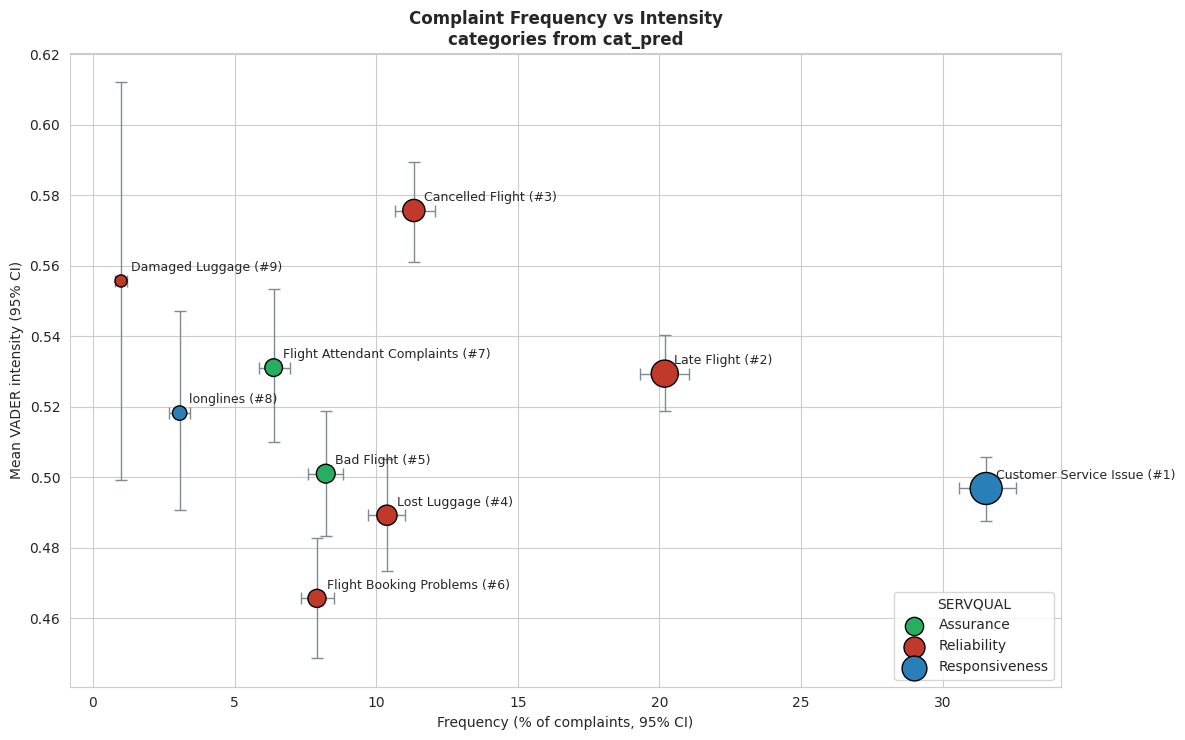

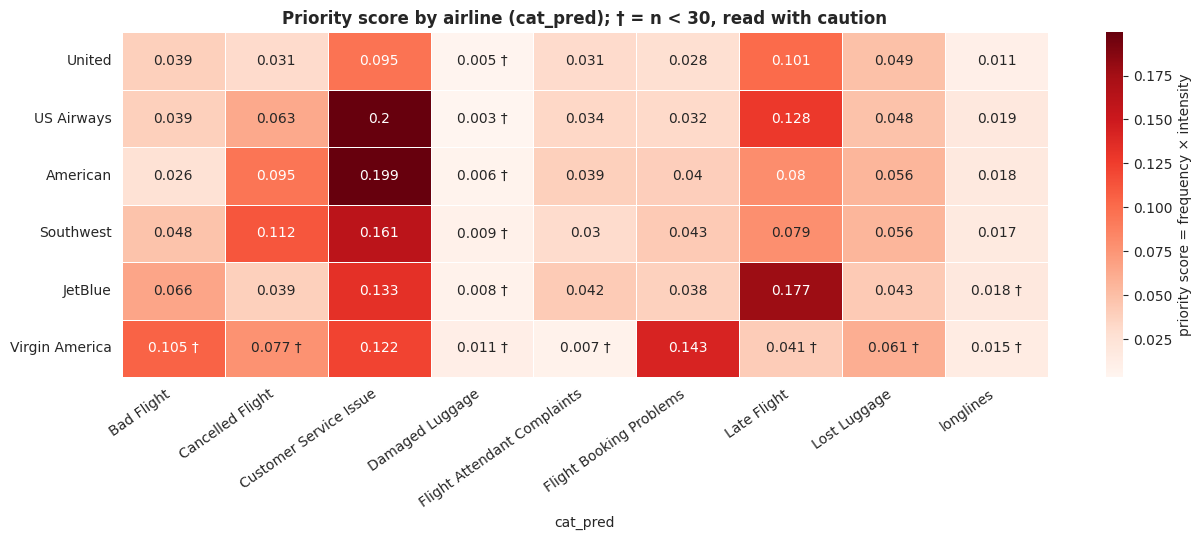


=== Prioritas | kategori dari negativereason ===


,Peringkat,Dimensi,n,Frekuensi,Frek CI low,Frek CI high,Intensitas,Int CI low,Int CI high,Skor prioritas,Skor CI low,Skor CI high,P(peringkat 1)
Kategori,,,,,,,,,,,,,
Customer Service Issue,1,Responsiveness,2882,0.3648,0.3544,0.3757,0.5065,0.4978,0.5149,0.1848,0.1788,0.1912,1.0
Late Flight,2,Reliability,1650,0.2089,0.1994,0.2176,0.5244,0.5138,0.5352,0.1095,0.1041,0.1149,0.0
Cancelled Flight,3,Reliability,828,0.1048,0.0980,0.1115,0.5643,0.5487,0.5790,0.0591,0.0549,0.0631,0.0
Lost Luggage,4,Reliability,718,0.0909,0.0847,0.0970,0.4772,0.4611,0.4936,0.0434,0.0400,0.0466,0.0
Bad Flight,5,Assurance,574,0.0727,0.0666,0.0785,0.5096,0.4910,0.5292,0.0370,0.0338,0.0403,0.0
Flight Attendant Complaints,6,Assurance,475,0.0601,0.0549,0.0656,0.5258,0.5035,0.5477,0.0316,0.0287,0.0348,0.0
Flight Booking Problems,7,Reliability,523,0.0662,0.0609,0.0718,0.4646,0.4454,0.4833,0.0308,0.0280,0.0335,0.0
longlines,8,Responsiveness,177,0.0224,0.0192,0.0256,0.5200,0.4878,0.5538,0.0116,0.0098,0.0135,0.0
Damaged Luggage,9,Reliability,73,0.0092,0.0072,0.0114,0.5365,0.4751,0.5961,0.0050,0.0037,0.0062,0.0


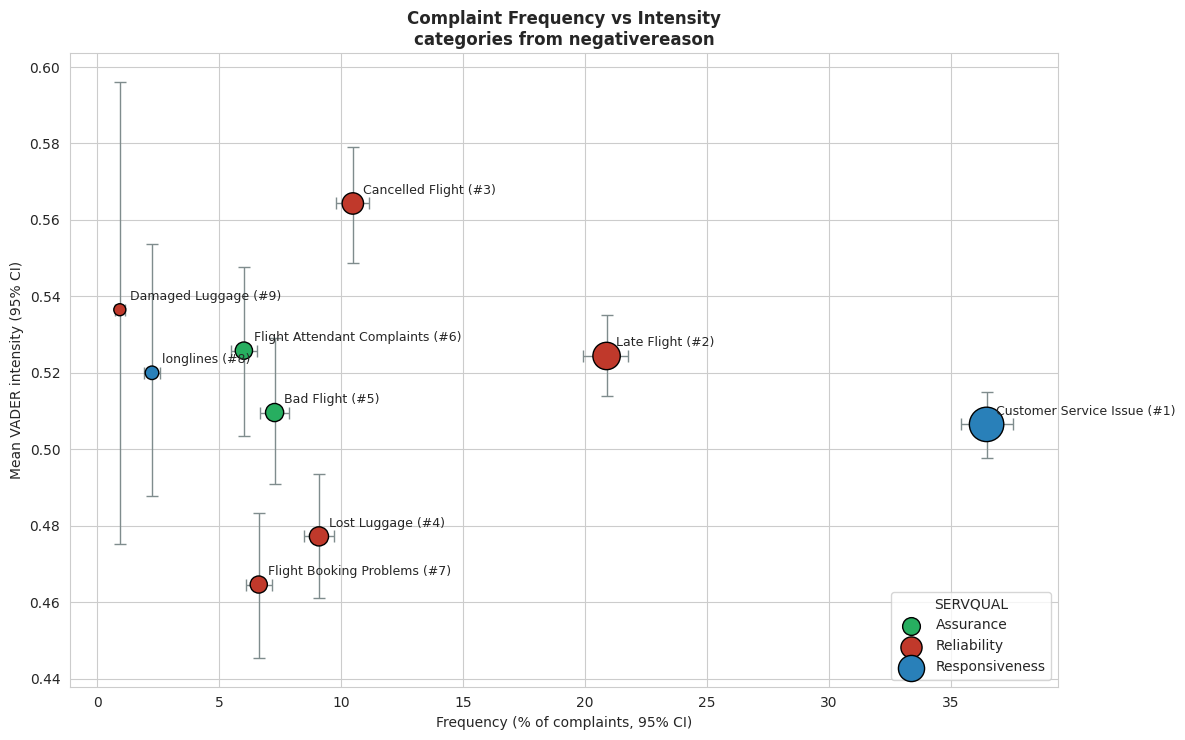

In [41]:
def prioritas_bootstrap(df, kol_kat, B=N_BOOT, seed=RANDOM_STATE):
    kat = df[kol_kat].value_counts().index.tolist()
    c = df[kol_kat].to_numpy(dtype=object); it = df['intensitas'].to_numpy(dtype=np.float32); n = len(df)
    rng = np.random.default_rng(seed)
    F = np.empty((B, len(kat))); I = np.empty((B, len(kat)))
    for s in range(0, B, 100):
        ix = rng.integers(0, n, size=(min(100, B - s), n))
        cb, ib = c[ix], it[ix]
        for j, k in enumerate(kat):
            m = (cb == k)
            cnt = m.sum(1)
            F[s:s + len(ix), j] = cnt / n
            I[s:s + len(ix), j] = np.where(cnt > 0, (m * ib).sum(1) / np.maximum(cnt, 1), np.nan)
    S = F * I
    rank1 = pd.Series(np.nanargmax(S, axis=1)).value_counts().reindex(range(len(kat)), fill_value=0) / B
    hasil = []
    for j, k in enumerate(kat):
        m = c == k
        f0, i0 = m.mean(), it[m].mean()
        hasil.append({'Kategori': k, 'Dimensi': SERVQUAL_MAP.get(k, '-'), 'n': int(m.sum()),
                      'Frekuensi': f0, 'Frek CI low': np.nanpercentile(F[:, j], 2.5), 'Frek CI high': np.nanpercentile(F[:, j], 97.5),
                      'Intensitas': i0, 'Int CI low': np.nanpercentile(I[:, j], 2.5), 'Int CI high': np.nanpercentile(I[:, j], 97.5),
                      'Skor prioritas': f0 * i0, 'Skor CI low': np.nanpercentile(S[:, j], 2.5),
                      'Skor CI high': np.nanpercentile(S[:, j], 97.5), 'P(peringkat 1)': rank1.iloc[j]})
    out = pd.DataFrame(hasil).sort_values('Skor prioritas', ascending=False)
    out.insert(1, 'Peringkat', range(1, len(out) + 1))
    return out.set_index('Kategori').round(4)

def gambar_prioritas(pr, judul, nama):
    fig, ax = plt.subplots(figsize=(12, 7.5))
    ax.errorbar(pr['Frekuensi'] * 100, pr['Intensitas'],
                xerr=[(pr['Frekuensi'] - pr['Frek CI low']) * 100, (pr['Frek CI high'] - pr['Frekuensi']) * 100],
                yerr=[pr['Intensitas'] - pr['Int CI low'], pr['Int CI high'] - pr['Intensitas']],
                fmt='none', ecolor='#7f8c8d', elinewidth=1, capsize=4, zorder=2)
    warna = {'Reliability': '#c0392b', 'Responsiveness': '#2980b9', 'Assurance': '#27ae60'}
    for d, g in pr.groupby('Dimensi'):
        ax.scatter(g['Frekuensi'] * 100, g['Intensitas'], s=60 + g['Skor prioritas'] * 3000,
                   color=warna.get(d, '#8e44ad'), edgecolor='black', label=d, zorder=3)
    for k, r in pr.iterrows():
        ax.annotate(f"{k} (#{int(r['Peringkat'])})", (r['Frekuensi'] * 100, r['Intensitas']),
                    xytext=(7, 7), textcoords='offset points', fontsize=9)
    ax.set_xlabel('Frequency (% of complaints, 95% CI)'); ax.set_ylabel('Mean VADER intensity (95% CI)')
    ax.set_title(f'Complaint Frequency vs Intensity\n{judul}'); ax.legend(title='SERVQUAL', loc='lower right')
    simpan_gambar(nama)

def matriks_per_maskapai(df, kol_kat, n_min=30):
    g = df.groupby(['airline', kol_kat])
    n = g.size().unstack(fill_value=0).reindex(MASKAPAI)
    frek = n.div(n.sum(1), axis=0)
    inten = g['intensitas'].mean().unstack().reindex(MASKAPAI)
    skor = (frek * inten)
    teks = skor.round(3).astype(str)
    label = teks.where(n >= n_min, teks + ' †').where(skor.notna(), '')
    return skor.round(4), n, label

PR, SKOR_MASKAPAI, N_MASKAPAI = {}, {}, {}
for kol in ['cat_pred', 'negativereason']:
    pr = prioritas_bootstrap(neg, kol)
    PR[kol] = pr
    print(f'\n=== Prioritas | kategori dari {kol} ===')
    display(simpan_tabel(pr, f't7_prioritas_{kol}'))
    gambar_prioritas(pr, f'categories from {kol}', f'g7_frekuensi_vs_intensitas_{kol}')

    skor, n, label = matriks_per_maskapai(neg, kol)
    SKOR_MASKAPAI[kol], N_MASKAPAI[kol] = skor, n
    simpan_tabel(skor, f't7_matriks_prioritas_maskapai_{kol}'); simpan_tabel(n, f't7_matriks_n_maskapai_{kol}')
    simpan_tabel(label, f't7_matriks_prioritas_maskapai_berlabel_{kol}')
    if kol == 'cat_pred':
        catat_angka('Tahap7_prioritas_1', f"{pr.index[0]} (P(rank1)={pr['P(peringkat 1)'].iloc[0]:.2f})")
        plt.figure(figsize=(13, 5.5))
        sns.heatmap(skor, annot=label.values, fmt='', cmap='Reds', linewidths=0.6,
                    cbar_kws={'label': 'priority score = frequency × intensity'})
        plt.title(f'Priority score by airline ({kol}); † = n < 30, read with caution')
        plt.xticks(rotation=35, ha='right'); plt.ylabel('')
        simpan_gambar(f'g7_matriks_prioritas_maskapai_{kol}')

### 7.1 Konsensus prioritas: SVM vs manusia

In [42]:
kp = pd.DataFrame({'Peringkat (SVM)': PR['cat_pred']['Peringkat'], 'Peringkat (manusia)': PR['negativereason']['Peringkat'],
                   'Skor SVM': PR['cat_pred']['Skor prioritas'], 'Skor manusia': PR['negativereason']['Skor prioritas'],
                   'P(peringkat 1) SVM': PR['cat_pred']['P(peringkat 1)'],
                   'P(peringkat 1) manusia': PR['negativereason']['P(peringkat 1)']}).sort_values('Peringkat (manusia)')
kp['Peringkat sama?'] = np.where(kp['Peringkat (SVM)'] == kp['Peringkat (manusia)'], 'Ya', 'Tidak')
rho_rank, _ = spearmanr(kp['Peringkat (SVM)'], kp['Peringkat (manusia)'])
display(simpan_tabel(kp, 't7_konsensus_prioritas'))
print(f'Spearman peringkat SVM vs manusia: {rho_rank:.3f} | peringkat sama di {(kp["Peringkat sama?"] == "Ya").sum()}/{len(kp)} kategori')

# Prioritas teratas per maskapai (hanya kategori dengan n >= 30 di kedua sumber)
baris = []
for m in MASKAPAI:
    ok = (N_MASKAPAI['cat_pred'].loc[m] >= 30) & (N_MASKAPAI['negativereason'].reindex(columns=N_MASKAPAI['cat_pred'].columns).loc[m] >= 30)
    sa = SKOR_MASKAPAI['cat_pred'].loc[m][ok].sort_values(ascending=False)
    sb = SKOR_MASKAPAI['negativereason'].reindex(columns=SKOR_MASKAPAI['cat_pred'].columns).loc[m][ok].sort_values(ascending=False)
    baris.append({'Maskapai': m, 'Prioritas 1 (SVM)': sa.index[0], 'Prioritas 1 (manusia)': sb.index[0],
                  'Prioritas 2 (SVM)': sa.index[1] if len(sa) > 1 else '-', 'Prioritas 2 (manusia)': sb.index[1] if len(sb) > 1 else '-',
                  'Prioritas 1 sama?': 'Ya' if sa.index[0] == sb.index[0] else 'Tidak'})
kpm = pd.DataFrame(baris)
display(simpan_tabel(kpm, 't7_konsensus_prioritas_maskapai', index=False))
catat_angka('Tahap7_spearman_peringkat_SVM_vs_manusia', round(rho_rank, 3))
catat_angka('Tahap7_maskapai_prioritas1_sama', f"{(kpm['Prioritas 1 sama?'] == 'Ya').sum()}/{len(kpm)}")

,Peringkat (SVM),Peringkat (manusia),Skor SVM,Skor manusia,P(peringkat 1) SVM,P(peringkat 1) manusia,Peringkat sama?
Kategori,,,,,,,
Customer Service Issue,1,1,0.1567,0.1848,1.0,1.0,Ya
Late Flight,2,2,0.1069,0.1095,0.0,0.0,Ya
Cancelled Flight,3,3,0.0652,0.0591,0.0,0.0,Ya
Lost Luggage,4,4,0.0508,0.0434,0.0,0.0,Ya
Bad Flight,5,5,0.0412,0.0370,0.0,0.0,Ya
Flight Attendant Complaints,7,6,0.0339,0.0316,0.0,0.0,Tidak
Flight Booking Problems,6,7,0.0368,0.0308,0.0,0.0,Tidak
longlines,8,8,0.0159,0.0116,0.0,0.0,Ya
Damaged Luggage,9,9,0.0055,0.0050,0.0,0.0,Ya


Spearman peringkat SVM vs manusia: 0.983 | peringkat sama di 7/9 kategori


,Maskapai,Prioritas 1 (SVM),Prioritas 1 (manusia),Prioritas 2 (SVM),Prioritas 2 (manusia),Prioritas 1 sama?
0,United,Late Flight,Customer Service Issue,Customer Service Issue,Late Flight,Tidak
1,US Airways,Customer Service Issue,Customer Service Issue,Late Flight,Late Flight,Ya
2,American,Customer Service Issue,Customer Service Issue,Cancelled Flight,Cancelled Flight,Ya
3,Southwest,Customer Service Issue,Customer Service Issue,Cancelled Flight,Cancelled Flight,Ya
4,JetBlue,Late Flight,Late Flight,Customer Service Issue,Customer Service Issue,Ya
5,Virgin America,Customer Service Issue,Customer Service Issue,-,-,Ya


In [43]:
# Peringkat frekuensi murni dengan bootstrap peringkat (hasil utama RQ5 setelah revisi ronde 2)
def peringkat_frekuensi(df, kol, B=N_BOOT, seed=RANDOM_STATE):
    kat = df[kol].value_counts().index.tolist(); c = df[kol].to_numpy(dtype=object); n = len(c)
    rng = np.random.default_rng(seed); R = np.empty((B, len(kat)), dtype=int)
    for s in range(0, B, 200):
        ix = rng.integers(0, n, size=(min(200, B - s), n)); cb = c[ix]
        cnt = np.stack([(cb == k).sum(1) for k in kat], axis=1)
        R[s:s + len(ix)] = (-cnt).argsort(axis=1).argsort(axis=1) + 1
    out = pd.DataFrame({'n': [int((c == k).sum()) for k in kat], 'Porsi (%)': [round((c == k).mean() * 100, 2) for k in kat],
                        'Peringkat 2,5%': np.percentile(R, 2.5, axis=0).astype(int), 'Peringkat 97,5%': np.percentile(R, 97.5, axis=0).astype(int),
                        'P(peringkat 1)': (R == 1).mean(axis=0).round(3)}, index=kat)
    out.insert(0, 'Peringkat', range(1, len(kat) + 1)); return out
for kol, ket in [('negativereason', 'manusia'), ('cat_pred', 'SVM')]:
    pf = peringkat_frekuensi(neg, kol)
    print(f'\nPeringkat frekuensi | label {ket}'); display(simpan_tabel(pf, f't7_peringkat_frekuensi_{ket}'))


Peringkat frekuensi | label manusia


,Peringkat,n,Porsi (%),"Peringkat 2,5%","Peringkat 97,5%",P(peringkat 1)
Customer Service Issue,1,2882,36.48,1,1,1.0
Late Flight,2,1650,20.89,2,2,0.0
Cancelled Flight,3,828,10.48,3,3,0.0
Lost Luggage,4,718,9.09,4,4,0.0
Bad Flight,5,574,7.27,5,6,0.0
Flight Booking Problems,6,523,6.62,5,7,0.0
Flight Attendant Complaints,7,475,6.01,6,7,0.0
longlines,8,177,2.24,8,8,0.0
Damaged Luggage,9,73,0.92,9,9,0.0



Peringkat frekuensi | label SVM


,Peringkat,n,Porsi (%),"Peringkat 2,5%","Peringkat 97,5%",P(peringkat 1)
Customer Service Issue,1,2492,31.54,1,1,1.0
Late Flight,2,1595,20.19,2,2,0.0
Cancelled Flight,3,895,11.33,3,4,0.0
Lost Luggage,4,820,10.38,3,4,0.0
Bad Flight,5,649,8.22,5,6,0.0
Flight Booking Problems,6,625,7.91,5,6,0.0
Flight Attendant Complaints,7,504,6.38,7,7,0.0
longlines,8,242,3.06,8,8,0.0
Damaged Luggage,9,78,0.99,9,9,0.0


---
# TAHAP 8 — Validasi Eksternal dengan Data DOT/BTS

Data *On-Time Performance* BTS Februari 2015 (kolom `FlightDate`, `Reporting_Airline`, `ArrDel15`, `Cancelled`). Urutan sumber: file `ontime_feb2015.csv` di working dir → file yang sama di `/kaggle/input` → unduh otomatis dari arsip PREZIP BTS. Jika unduhan gagal, unduh manual dari TranStats (*Reporting Carrier On-Time Performance*, Februari 2015) lalu unggah sebagai dataset Kaggle bernama `ontime_feb2015.csv`.

Korelasi Spearman dengan **n = 6** hanya dibaca **deskriptif** (arah dan besaran), bukan uji inferensial.

Validasi memakai **keterlambatan dan pembatalan** saja. Data bagasi bermasalah (ATCR) tidak dipakai karena hanya tersedia sebagai angka sebulan penuh (Februari 2015), sehingga tidak sejajar dengan jendela 9 hari tweet; data BTS on-time bisa difilter per tanggal sehingga periodenya sama persis.

In [44]:
BTS_CSV = os.path.join(os.path.dirname(OUT) if OUT.startswith('/kaggle') else '.', 'ontime_feb2015.csv')
BTS_URL = ('https://transtats.bts.gov/PREZIP/'
           'On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2015_2.zip')
KOLOM_BTS = ['FlightDate', 'Reporting_Airline', 'ArrDel15', 'Cancelled']
bts = None

if os.path.exists(BTS_CSV):
    bts = pd.read_csv(BTS_CSV)
elif glob.glob('/kaggle/input/**/ontime_feb2015.csv', recursive=True):
    bts = pd.read_csv(glob.glob('/kaggle/input/**/ontime_feb2015.csv', recursive=True)[0])
else:
    try:
        print('Mengunduh data BTS (± 25 MB) ...')
        req = urllib.request.Request(BTS_URL, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=600) as r:
            buf = r.read()
        z = zipfile.ZipFile(io.BytesIO(buf))
        nama_csv = [n for n in z.namelist() if n.lower().endswith('.csv')][0]
        bts = pd.read_csv(z.open(nama_csv), usecols=KOLOM_BTS, low_memory=False)
    except Exception as e:
        print('Unduhan BTS gagal:', repr(e))
        print('Unggah ontime_feb2015.csv secara manual lalu jalankan ulang sel ini.')

if bts is not None:
    bts = bts[KOLOM_BTS]
    bts.to_csv(BTS_CSV, index=False)
    print('Data BTS:', bts.shape, '| disimpan di', os.path.abspath(BTS_CSV))

Mengunduh data BTS (± 25 MB) ...
Data BTS: (429191, 4) | disimpan di /kaggle/working/ontime_feb2015.csv


Kode BTS yang dipakai: {'United': 'UA', 'US Airways': 'US', 'American': 'AA', 'Southwest': 'WN', 'Virgin America': 'VX', 'JetBlue': 'B6'}


,Penerbangan,Tingkat_terlambat,Tingkat_batal,n_keluhan,Porsi_Late_Flight,Porsi_Cancelled_Flight,Porsi_Reliability,Tingkat_gangguan
Reporting_Airline,,,,,,,,
United,12199,0.2483,0.0149,2252,0.2318,0.0750,0.5342,0.2632
US Airways,9807,0.3148,0.0538,2015,0.2179,0.1022,0.4764,0.3686
American,12932,0.2381,0.0648,1680,0.1417,0.1554,0.4810,0.3029
Southwest,29524,0.2173,0.0489,1026,0.1442,0.1862,0.5312,0.2662
JetBlue,6491,0.4101,0.0183,768,0.3086,0.0651,0.5326,0.4284
Virgin America,1377,0.1925,0.0356,159,0.0692,0.1132,0.5535,0.2280


,Data,Indikator DOT,Porsi keluhan,n maskapai,Spearman rho,p (deskriptif)
0,16-24 Feb 2015,Tingkat_terlambat,Porsi_Late_Flight,6,0.886,0.019
1,16-24 Feb 2015,Tingkat_batal,Porsi_Cancelled_Flight,6,0.657,0.156
2,16-24 Feb 2015,Tingkat_gangguan,Porsi_Reliability,6,-0.657,0.156


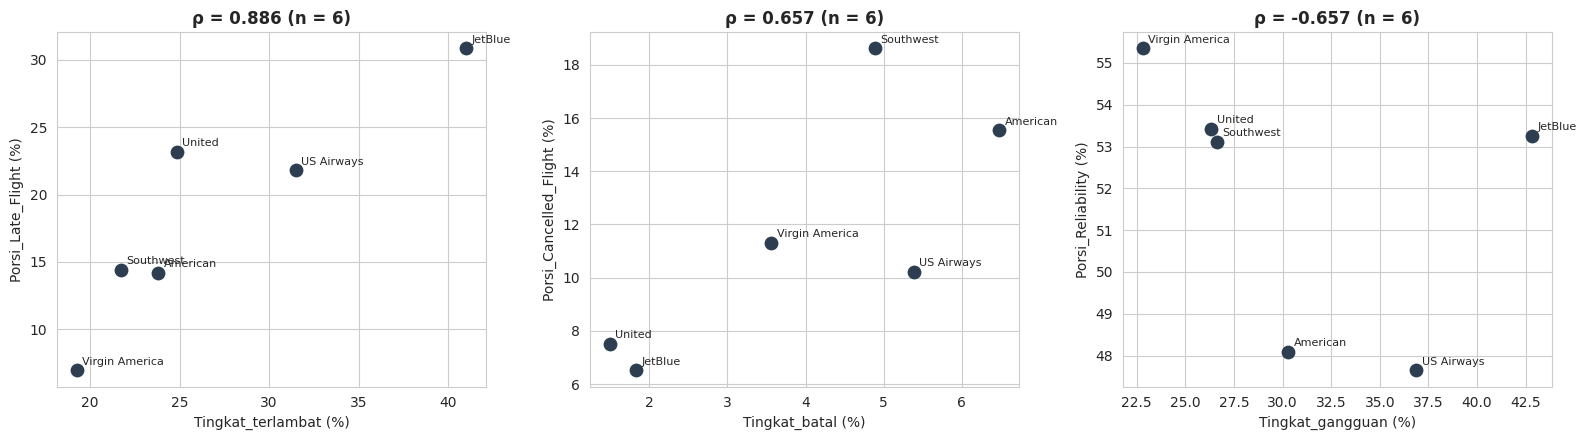

,Data,Indikator DOT,Porsi keluhan,n maskapai,Spearman rho,p (deskriptif)
0,common_days (3 hari),Tingkat_terlambat,Porsi_Late_Flight,6,0.714,0.111
1,common_days (3 hari),Tingkat_batal,Porsi_Cancelled_Flight,6,0.943,0.005
2,common_days (3 hari),Tingkat_gangguan,Porsi_Reliability,6,-0.771,0.072


,Data,Indikator DOT,Porsi keluhan,rho SVM,rho manusia,Arah sama?
0,16-24 Feb 2015,Tingkat_terlambat,Porsi_Late_Flight,0.886,0.886,Ya
1,16-24 Feb 2015,Tingkat_batal,Porsi_Cancelled_Flight,0.657,0.657,Ya
2,16-24 Feb 2015,Tingkat_gangguan,Porsi_Reliability,-0.657,0.314,Tidak
3,common_days (3 hari),Tingkat_terlambat,Porsi_Late_Flight,0.714,0.486,Ya
4,common_days (3 hari),Tingkat_batal,Porsi_Cancelled_Flight,0.943,0.771,Ya
5,common_days (3 hari),Tingkat_gangguan,Porsi_Reliability,-0.771,-0.486,Ya


Tulis arah korelasi hanya bila "Arah sama?" = Ya di kedua periode; n = 6, tetap deskriptif.


In [45]:
KODE_BTS = {'United': 'UA', 'US Airways': 'US', 'American': 'AA', 'Southwest': 'WN', 'Virgin America': 'VX'}
if GANTI_DELTA_KE_JETBLUE:
    KODE_BTS['JetBlue'] = 'B6'      # tweet berlabel "Delta" ternyata ditujukan ke @JetBlue (lihat 1.0)
else:
    KODE_BTS['Delta'] = 'DL'
print('Kode BTS yang dipakai:', KODE_BTS)


def validasi_dot(neg_df, hari, label, kol_kat='cat_pred', kol_dim='dim_pred'):
    b = bts.copy()
    b['FlightDate'] = pd.to_datetime(b['FlightDate']).dt.strftime('%Y-%m-%d')
    b = b[b['FlightDate'].isin(hari) & b['Reporting_Airline'].isin(KODE_BTS.values())]
    ops = b.groupby('Reporting_Airline').agg(Penerbangan=('Cancelled', 'size'),
                                             Tingkat_terlambat=('ArrDel15', 'mean'),   # NaN (batal/divert) diabaikan
                                             Tingkat_batal=('Cancelled', 'mean'))
    ops.index = ops.index.map({v: k for k, v in KODE_BTS.items()})

    nd = neg_df[neg_df['tanggal'].isin(hari)]
    g = nd.groupby('airline')
    kel = pd.DataFrame({
        'n_keluhan': g.size(),
        'Porsi_Late_Flight': g[kol_kat].apply(lambda s: (s == 'Late Flight').mean()),
        'Porsi_Cancelled_Flight': g[kol_kat].apply(lambda s: (s == 'Cancelled Flight').mean()),
        'Porsi_Reliability': g[kol_dim].apply(lambda s: (s == 'Reliability').mean())})
    tab = ops.join(kel).reindex(MASKAPAI)
    tab['Tingkat_gangguan'] = tab['Tingkat_terlambat'] + tab['Tingkat_batal']

    pasangan = [('Tingkat_terlambat', 'Porsi_Late_Flight'), ('Tingkat_batal', 'Porsi_Cancelled_Flight'),
                ('Tingkat_gangguan', 'Porsi_Reliability')]
    kor = []
    for a, k in pasangan:
        sub = tab[[a, k]].dropna()
        if len(sub) >= 3:
            rho, p = spearmanr(sub[a], sub[k])
        else:
            rho, p = np.nan, np.nan
        kor.append({'Data': label, 'Indikator DOT': a, 'Porsi keluhan': k, 'n maskapai': len(sub),
                    'Spearman rho': round(rho, 3) if pd.notna(rho) else np.nan,
                    'p (deskriptif)': round(p, 3) if pd.notna(p) else np.nan})
    return tab, pd.DataFrame(kor)

if bts is not None:
    hari_penuh = [f'2015-02-{d}' for d in range(16, 25)]
    tab_dot, kor_dot = validasi_dot(neg, hari_penuh, '16-24 Feb 2015')
    display(simpan_tabel(tab_dot.round(4), 't8_dot_vs_keluhan'))
    display(simpan_tabel(kor_dot, 't8_spearman_dot', index=False))

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    for a_, (_, r) in zip(ax, kor_dot.iterrows()):
        sub = tab_dot[[r['Indikator DOT'], r['Porsi keluhan']]].dropna()
        a_.scatter(sub.iloc[:, 0] * 100, sub.iloc[:, 1] * 100, s=80, color='#2c3e50')
        for m, rr in sub.iterrows():
            a_.annotate(m, (rr.iloc[0] * 100, rr.iloc[1] * 100),
                        xytext=(4, 4), textcoords='offset points', fontsize=8)
        a_.set_xlabel(r['Indikator DOT'] + ' (%)')
        a_.set_ylabel(r['Porsi keluhan'] + ' (%)')
        a_.set_title(f"ρ = {r['Spearman rho']} (n = {r['n maskapai']})")
    simpan_gambar('g8_dot_vs_keluhan')

    # Opsional: hanya common_days
    tab_dot_c, kor_dot_c = validasi_dot(neg, common_days, f'common_days ({len(common_days)} hari)')
    display(simpan_tabel(kor_dot_c, 't8_spearman_dot_common_days', index=False))
    simpan_tabel(tab_dot_c.round(4), 't8_dot_vs_keluhan_common_days')
    for _, r in kor_dot.iterrows():
        catat_angka(f"Tahap8_rho_{r['Indikator DOT']}_vs_{r['Porsi keluhan']}", r['Spearman rho'])

    # Konsensus: ulangi dengan label manusia; arah korelasi ditulis hanya bila sama di kedua sumber
    baris = []
    for hari, nama in [(hari_penuh, '16-24 Feb 2015'), (common_days, f'common_days ({len(common_days)} hari)')]:
        ks = validasi_dot(neg, hari, nama, 'cat_pred', 'dim_pred')[1]
        km = validasi_dot(neg, hari, nama, 'negativereason', 'dim_label')[1]
        for (_, a), (_, b) in zip(ks.iterrows(), km.iterrows()):
            if pd.isna(a['Spearman rho']) or pd.isna(b['Spearman rho']):
                continue
            baris.append({'Data': nama, 'Indikator DOT': a['Indikator DOT'], 'Porsi keluhan': a['Porsi keluhan'],
                          'rho SVM': a['Spearman rho'], 'rho manusia': b['Spearman rho'],
                          'Arah sama?': 'Ya' if np.sign(a['Spearman rho']) == np.sign(b['Spearman rho']) else 'Tidak'})
    kons_dot = pd.DataFrame(baris)
    display(simpan_tabel(kons_dot, 't8_konsensus_dot', index=False))
    print('Tulis arah korelasi hanya bila "Arah sama?" = Ya di kedua periode; n = 6, tetap deskriptif.')

---
# TAHAP 6B — Analisis level kategori keluhan (revisi ronde 2, jalur B)

Analisis utama dipindah ke **kategori keluhan** (sembilan kategori informatif), karena pemetaan ke SERVQUAL belum divalidasi pengkode independen. Sel ini memuat:

1. Chi-square maskapai × kategori untuk label manusia dan SVM, pada data penuh, `common_days`, dan satu tweet per pengguna (dengan p-value permutasi karena beberapa sel punya nilai harapan < 5).
2. Residual terstandar dengan ambang 1,96 **dan Bonferroni** (54 sel kategori; 18 sel dimensi), aturan konsensus dua sumber, serta ketahanan di subset.
3. **Tingkat pemulihan dan sel palsu SVM**: seberapa jauh SVM mereproduksi sel yang signifikan pada label manusia.
4. **Konsentrasi waktu**: analisis tanpa dua hari paling ramai, dan uji **Cochran-Mantel-Haenszel per hari** (tabel 2×2 per hari untuk tiap sel maskapai × kategori).
5. Keluhan per 1.000 penerbangan (BTS), pelengkap yang dikaitkan dengan catatan bahwa volume tweet bergantung pada jumlah pengikut maskapai.

Jalankan **setelah** sel BTS di atas (memakai `bts` dan `KODE_BTS`).

In [46]:
# ============================================================
# TAHAP 6B-a (revisi ronde 2) — Analisis level KATEGORI keluhan
# Jalankan SETELAH sel BTS (Tahap 8, sel yang mendefinisikan KODE_BTS dan validasi_dot).
# Memakai: neg, neg_common, neg_user1, df_user1, common_days, MASKAPAI, bts, KODE_BTS,
#          simpan_tabel, catat_angka, cramers_v, RANDOM_STATE
# ============================================================
from scipy.stats import norm, chi2_contingency
from scipy.stats import chi2 as chi2_dist

KAT = ['Customer Service Issue', 'Late Flight', 'Cancelled Flight', 'Lost Luggage', 'Bad Flight',
       'Flight Booking Problems', 'Flight Attendant Complaints', 'longlines', 'Damaged Luggage']
SUMBER = [('negativereason', 'manusia'), ('cat_pred', 'SVM')]
N_SEL = len(MASKAPAI) * len(KAT)                      # 6 x 9 = 54 sel
Z_BONF = norm.ppf(1 - 0.05 / (2 * N_SEL))             # ambang dua sisi, Bonferroni 54 sel
Z_BONF_DIM = norm.ppf(1 - 0.05 / (2 * len(MASKAPAI) * 3))   # 6 x 3 = 18 sel (dimensi)
print(f'Ambang Bonferroni kategori (54 sel): |z| > {Z_BONF:.3f} | dimensi (18 sel): |z| > {Z_BONF_DIM:.3f}')

def uji_kat(df, kol, kats=KAT):
    tab = pd.crosstab(df['airline'], df[kol]).reindex(index=MASKAPAI, columns=kats).fillna(0).astype(int)
    chi2, p, dof, exp = chi2_contingency(tab)
    n = tab.values.sum()
    rp, cp = tab.sum(axis=1).values[:, None] / n, tab.sum(0).values[None, :] / n
    resid = (tab.values - exp) / np.sqrt(exp * (1 - rp) * (1 - cp))
    # p-value permutasi (10.000 acak) karena beberapa sel harapan < 5 (Damaged Luggage, Virgin America)
    rng = np.random.default_rng(RANDOM_STATE)
    a = df['airline'].to_numpy(dtype=object); k = df[kol].to_numpy(dtype=object)
    ai = pd.Categorical(a, categories=MASKAPAI).codes; ki = pd.Categorical(k, categories=kats).codes
    ok = (ai >= 0) & (ki >= 0); ai, ki = ai[ok], ki[ok]
    R_, K_ = len(MASKAPAI), len(kats)
    def chi_cepat(ai_, ki_):
        t = np.bincount(ai_ * K_ + ki_, minlength=R_ * K_).reshape(R_, K_).astype(float)
        e = t.sum(axis=1)[:, None] * t.sum(axis=0)[None, :] / t.sum()
        return ((t - e) ** 2 / e).sum()
    obs = chi_cepat(ai, ki)
    lebih = sum(chi_cepat(ai, rng.permutation(ki)) >= obs for _ in range(10000))
    p_perm = (lebih + 1) / 10001
    ring = {'n': int(n), 'chi2': round(chi2, 2), 'df': int(dof), 'p': float(p), 'p_permutasi': round(p_perm, 4),
            "Cramér's V": round(cramers_v(chi2, n, *tab.shape), 4),
            'Sel harapan < 5': int((exp < 5).sum()), 'Harapan minimum': round(exp.min(), 2)}
    return ring, tab, pd.DataFrame(resid, index=tab.index, columns=tab.columns).round(2)

# ---------- 1. Uji maskapai x kategori, tiga subset, dua sumber label ----------
SUBS = [('Penuh', neg), ('common_days', neg_common), ('1 tweet/pengguna', neg_user1)]
HASIL_K, baris = {}, []
for nama_sub, d in SUBS:
    for kol, ket in SUMBER:
        ring, tab, resid = uji_kat(d, kol)
        HASIL_K[(ket, nama_sub)] = (ring, tab, resid)
        baris.append({'Sumber': ket, 'Data': nama_sub, **ring})
tab_chi = pd.DataFrame(baris)
display(simpan_tabel(tab_chi, 't9_kategori_chi2', index=False))

# ---------- 2. Residual terstandar, ambang 1,96 dan Bonferroni, konsensus ----------
rM, rS = HASIL_K[('manusia', 'Penuh')][2], HASIL_K[('SVM', 'Penuh')][2]
rows = []
for m in MASKAPAI:
    for k in KAT:
        a, b = rS.loc[m, k], rM.loc[m, k]
        def tanda(x, z): return 1 if x > z else (-1 if x < -z else 0)
        s196 = tanda(a, 1.96) if tanda(a, 1.96) == tanda(b, 1.96) else 0
        sbon = tanda(a, Z_BONF) if tanda(a, Z_BONF) == tanda(b, Z_BONF) else 0
        tahan = [nm for nm, d in SUBS[1:] if
                 (lambda ra, rb: (tanda(ra, Z_BONF) == tanda(rb, Z_BONF) == sbon))(
                     HASIL_K[('SVM', nm)][2].loc[m, k], HASIL_K[('manusia', nm)][2].loc[m, k])] if sbon != 0 else []
        rows.append({'Maskapai': m, 'Kategori': k, 'n manusia': int(HASIL_K[('manusia', 'Penuh')][1].loc[m, k]),
                     'r SVM': a, 'r manusia': b,
                     'Konsensus 1,96': {1: 'lebih tinggi', -1: 'lebih rendah', 0: ''}[s196],
                     'Konsensus Bonferroni': {1: 'lebih tinggi', -1: 'lebih rendah', 0: ''}[sbon],
                     'Bertahan di subset (Bonferroni)': ', '.join(tahan)})
res_k = pd.DataFrame(rows)
display(simpan_tabel(res_k, 't9_kategori_residual_konsensus', index=False))
print('Sel konsensus 1,96 :', (res_k['Konsensus 1,96'] != '').sum(),
      '| sel konsensus Bonferroni:', (res_k['Konsensus Bonferroni'] != '').sum(),
      '| sel signifikan manusia (Bonf.):', (rM.abs() > Z_BONF).values.sum(),
      '| SVM (Bonf.):', (rS.abs() > Z_BONF).values.sum())
display(simpan_tabel(res_k[res_k['Konsensus Bonferroni'] != ''], 't9_kategori_konsensus_bonferroni', index=False))

# Pembanding level dimensi dengan Bonferroni (18 sel), memakai HASIL_H1 dari Tahap 6
try:
    ra, rb = HASIL_H1[(DIM, 'penuh')]['resid'], HASIL_H1[(DIM_PEMBANDING, 'penuh')]['resid']
    dm = []
    for m in MASKAPAI:
        for d_ in [c for c in ra.columns if c in rb.columns]:
            x, y = ra.loc[m, d_], rb.loc[m, d_]
            dm.append({'Maskapai': m, 'Dimensi': d_, 'r SVM': x, 'r manusia': y,
                       '1,96 konsensus': (np.sign(x) == np.sign(y)) and abs(x) > 1.96 and abs(y) > 1.96,
                       'Bonferroni konsensus': (np.sign(x) == np.sign(y)) and abs(x) > Z_BONF_DIM and abs(y) > Z_BONF_DIM})
    dm = pd.DataFrame(dm)
    display(simpan_tabel(dm, 't9_dimensi_bonferroni', index=False))
    print('Dimensi: konsensus 1,96 =', int(dm['1,96 konsensus'].sum()), '| konsensus Bonferroni =', int(dm['Bonferroni konsensus'].sum()))
except NameError as e:
    print('Lewati pembanding dimensi:', e)

# ---------- 2b. Tingkat pemulihan: seberapa jauh pipeline SVM mereproduksi temuan dari label manusia ----------
# Acuan = sel signifikan pada label manusia. Pemulihan = acuan yang juga signifikan searah pada SVM.
# Sel palsu = signifikan pada SVM tetapi tidak signifikan searah pada label manusia.
def pemulihan(rS_, rM_, z):
    sM, sS = (rM_.abs() > z), (rS_.abs() > z)
    kons = sM & sS & (np.sign(rM_) == np.sign(rS_))
    return {'Ambang |z|': round(z, 3), 'Sel diuji': int(rM_.size), 'Signifikan manusia (acuan)': int(sM.values.sum()),
            'Signifikan SVM': int(sS.values.sum()), 'Konsensus (sama arah)': int(kons.values.sum()),
            'Terlewat SVM': int(sM.values.sum() - kons.values.sum()),
            'Sel palsu SVM': int(sS.values.sum() - kons.values.sum()),
            'Tingkat pemulihan (%)': round(kons.values.sum() / max(sM.values.sum(), 1) * 100, 1)}
rows = [{'Level': 'Kategori', **pemulihan(rS, rM, 1.96)}, {'Level': 'Kategori', **pemulihan(rS, rM, Z_BONF)}]
try:
    rows += [{'Level': 'Dimensi', **pemulihan(ra, rb, 1.96)}, {'Level': 'Dimensi', **pemulihan(ra, rb, Z_BONF_DIM)}]
except NameError:
    pass
display(simpan_tabel(pd.DataFrame(rows), 't9_pemulihan_dan_sel_palsu', index=False))
# daftar sel yang terlewat dan sel palsu pada ambang 1,96 (kategori)
lewat = [(m, k, rS.loc[m, k], rM.loc[m, k]) for m in MASKAPAI for k in KAT
         if abs(rM.loc[m, k]) > 1.96 and not (abs(rS.loc[m, k]) > 1.96 and np.sign(rS.loc[m, k]) == np.sign(rM.loc[m, k]))]
palsu = [(m, k, rS.loc[m, k], rM.loc[m, k]) for m in MASKAPAI for k in KAT
         if abs(rS.loc[m, k]) > 1.96 and not (abs(rM.loc[m, k]) > 1.96 and np.sign(rS.loc[m, k]) == np.sign(rM.loc[m, k]))]
display(simpan_tabel(pd.DataFrame(lewat, columns=['Maskapai', 'Kategori', 'r SVM', 'r manusia']), 't9_sel_terlewat_svm', index=False))
display(simpan_tabel(pd.DataFrame(palsu, columns=['Maskapai', 'Kategori', 'r SVM', 'r manusia']), 't9_sel_palsu_svm', index=False))

# ---------- 3. Porsi kategori per maskapai (untuk tabel hasil) ----------
for kol, ket in SUMBER:
    pct = (HASIL_K[(ket, 'Penuh')][1].div(HASIL_K[(ket, 'Penuh')][1].sum(axis=1), axis=0) * 100).round(1)
    pct['n keluhan'] = HASIL_K[(ket, 'Penuh')][1].sum(axis=1)
    display(simpan_tabel(pct, f't9_porsi_kategori_{ket}'))



Ambang Bonferroni kategori (54 sel): |z| > 3.312 | dimensi (18 sel): |z| > 2.991


,Sumber,Data,n,chi2,df,p,p_permutasi,Cramér's V,Sel harapan < 5,Harapan minimum
0,manusia,Penuh,7900,462.35,40,2.949509e-73,0.0001,0.1082,2,1.47
1,SVM,Penuh,7900,510.85,40,5.702714e-83,0.0001,0.1137,2,1.57
2,manusia,common_days,4246,341.95,40,1.370785e-49,0.0001,0.1269,7,0.49
3,SVM,common_days,4246,333.44,40,6.028819e-48,0.0001,0.1253,7,0.60
4,manusia,1 tweet/pengguna,4212,340.27,40,2.899247e-49,0.0001,0.1271,3,1.01
5,SVM,1 tweet/pengguna,4212,411.74,40,3.210178e-63,0.0001,0.1398,3,1.04


,Maskapai,Kategori,n manusia,r SVM,r manusia,"Konsensus 1,96",Konsensus Bonferroni,Bertahan di subset (Bonferroni)
0,United,Customer Service Issue,681,-6.51,-7.28,lebih rendah,lebih rendah,"common_days, 1 tweet/pengguna"
1,United,Late Flight,525,4.18,3.35,lebih tinggi,lebih tinggi,1 tweet/pengguna
2,United,Cancelled Flight,180,-6.77,-4.56,lebih rendah,lebih rendah,1 tweet/pengguna
3,United,Lost Luggage,269,5.74,5.58,lebih tinggi,lebih tinggi,"common_days, 1 tweet/pengguna"
4,United,Bad Flight,215,3.18,4.93,lebih tinggi,,
5,United,Flight Booking Problems,144,0.45,-0.51,,,
6,United,Flight Attendant Complaints,168,2.68,3.42,lebih tinggi,,
7,United,longlines,48,0.15,-0.41,,,
8,United,Damaged Luggage,22,0.70,0.31,,,
9,US Airways,Customer Service Issue,809,5.63,3.96,lebih tinggi,lebih tinggi,


Sel konsensus 1,96 : 24 | sel konsensus Bonferroni: 15 | sel signifikan manusia (Bonf.): 19 | SVM (Bonf.): 18


,Maskapai,Kategori,n manusia,r SVM,r manusia,"Konsensus 1,96",Konsensus Bonferroni,Bertahan di subset (Bonferroni)
0,United,Customer Service Issue,681,-6.51,-7.28,lebih rendah,lebih rendah,"common_days, 1 tweet/pengguna"
1,United,Late Flight,525,4.18,3.35,lebih tinggi,lebih tinggi,1 tweet/pengguna
2,United,Cancelled Flight,180,-6.77,-4.56,lebih rendah,lebih rendah,1 tweet/pengguna
3,United,Lost Luggage,269,5.74,5.58,lebih tinggi,lebih tinggi,"common_days, 1 tweet/pengguna"
9,US Airways,Customer Service Issue,809,5.63,3.96,lebih tinggi,lebih tinggi,
18,American,Customer Service Issue,743,6.10,7.43,lebih tinggi,lebih tinggi,"common_days, 1 tweet/pengguna"
19,American,Late Flight,234,-6.93,-7.91,lebih rendah,lebih rendah,"common_days, 1 tweet/pengguna"
20,American,Cancelled Flight,228,6.13,4.66,lebih tinggi,lebih tinggi,"common_days, 1 tweet/pengguna"
22,American,Bad Flight,82,-5.71,-4.24,lebih rendah,lebih rendah,"common_days, 1 tweet/pengguna"
28,Southwest,Late Flight,152,-4.93,-5.13,lebih rendah,lebih rendah,1 tweet/pengguna


...

,Level,Ambang |z|,Sel diuji,Signifikan manusia (acuan),Signifikan SVM,Konsensus (sama arah),Terlewat SVM,Sel palsu SVM,Tingkat pemulihan (%)
0,Kategori,1.960,54,29,29,24,5,5,82.8
1,Kategori,3.312,54,19,18,15,4,3,78.9
2,Dimensi,1.960,18,12,12,11,1,1,91.7
3,Dimensi,2.991,18,9,8,6,3,2,66.7


,Maskapai,Kategori,r SVM,r manusia
0,American,Flight Attendant Complaints,0.09,-2.31
1,Southwest,Bad Flight,0.45,1.99
2,JetBlue,Flight Attendant Complaints,1.40,2.21
3,Virgin America,Lost Luggage,-0.40,-2.63
4,Virgin America,Damaged Luggage,1.16,2.12


,Maskapai,Kategori,r SVM,r manusia
0,US Airways,Flight Booking Problems,-2.53,-1.18
1,JetBlue,Lost Luggage,-2.33,-1.82
2,JetBlue,Bad Flight,3.86,1.20
3,Virgin America,Customer Service Issue,-2.44,0.33
4,Virgin America,Flight Attendant Complaints,-2.67,-1.54


negativereason,Customer Service Issue,Late Flight,Cancelled Flight,Lost Luggage,Bad Flight,Flight Booking Problems,Flight Attendant Complaints,longlines,Damaged Luggage,n keluhan
airline,,,,,,,,,,
United,30.2,23.3,8.0,11.9,9.5,6.4,7.5,2.1,1.0,2252
US Airways,40.1,22.5,9.4,7.6,5.2,6.1,6.1,2.5,0.5,2015
American,44.2,13.9,13.6,8.6,4.9,7.4,4.8,2.0,0.7,1680
Southwest,38.0,14.8,15.8,8.8,8.8,5.9,3.7,2.8,1.4,1026
JetBlue,25.9,35.0,6.6,7.3,8.3,5.7,7.8,1.8,1.4,768
Virgin America,37.7,10.7,11.3,3.1,11.9,17.6,3.1,1.9,2.5,159


cat_pred,Customer Service Issue,Late Flight,Cancelled Flight,Lost Luggage,Bad Flight,Flight Booking Problems,Flight Attendant Complaints,longlines,Damaged Luggage,n keluhan
airline,,,,,,,,,,
United,26.2,23.2,7.5,13.5,9.8,8.1,7.5,3.1,1.1,2252
US Airways,36.6,21.8,10.2,8.5,6.9,6.6,5.8,3.0,0.5,2015
American,37.7,14.2,15.5,9.5,4.8,8.0,6.4,3.0,0.9,1680
Southwest,30.5,14.4,18.6,10.6,8.6,8.2,4.8,3.0,1.3,1026
JetBlue,24.0,30.9,6.5,7.9,11.8,6.5,7.6,3.4,1.4,768
Virgin America,22.6,6.9,11.3,9.4,18.2,25.8,1.3,2.5,1.9,159


In [47]:
# ============================================================
# TAHAP 6B-b — Konsentrasi waktu (hari puncak dibuang + CMH per hari)
# Butuh sel 6B-a sudah dijalankan (fungsi uji_kat, KAT, SUMBER, MASKAPAI, Z_BONF, N_SEL, HASIL_K)
# ============================================================
from scipy.stats import chi2 as chi2_dist
# ---------- 4. Konsentrasi waktu: (a) buang hari puncak, (b) CMH per hari ----------
per_hari = neg.groupby('tanggal').size().sort_values(ascending=False)
print('Jumlah keluhan per hari (terbanyak dulu):'); print(per_hari.head(5))
hari_puncak = list(per_hari.index[:2])
print('Hari puncak yang dibuang:', hari_puncak)
neg_tanpa_puncak = neg[~neg['tanggal'].isin(hari_puncak)]
am = neg.groupby(['tanggal', 'airline']).size().unstack(fill_value=0).reindex(columns=MASKAPAI, fill_value=0)
print('Keluhan per hari x maskapai:'); display(am)

baris = []
for kol, ket in SUMBER:
    ring, tab, resid = uji_kat(neg_tanpa_puncak, kol)
    HASIL_K[(ket, 'tanpa_puncak')] = (ring, tab, resid)
    baris.append({'Sumber': ket, 'Data': f'tanpa {hari_puncak}', **ring})
display(simpan_tabel(pd.DataFrame(baris), 't9_kategori_tanpa_puncak', index=False))
rows = []
for m in MASKAPAI:
    for k in KAT:
        a, b = HASIL_K[('SVM', 'tanpa_puncak')][2].loc[m, k], HASIL_K[('manusia', 'tanpa_puncak')][2].loc[m, k]
        rows.append({'Maskapai': m, 'Kategori': k, 'r SVM': a, 'r manusia': b,
                     'Konsensus Bonferroni': bool(np.sign(a) == np.sign(b) and min(abs(a), abs(b)) > Z_BONF)})
tp = pd.DataFrame(rows)
display(simpan_tabel(tp[tp['Konsensus Bonferroni']], 't9_konsensus_tanpa_puncak', index=False))

# CMH (Mantel-Haenszel, ditulis manual): untuk tiap maskapai x kategori, tabel 2x2 per hari
# (maskapai ini vs lainnya; kategori ini vs lainnya). Variansi log-OR: Robins-Breslow-Greenland.
def cmh_sel(df, kol, m, k):
    T = []
    for hari, g in df.groupby('tanggal'):
        a = ((g['airline'] == m) & (g[kol] == k)).sum(); b = ((g['airline'] == m) & (g[kol] != k)).sum()
        c = ((g['airline'] != m) & (g[kol] == k)).sum(); d_ = ((g['airline'] != m) & (g[kol] != k)).sum()
        if min(a + b, c + d_, a + c, b + d_) > 0:
            T.append((a, b, c, d_))
    if len(T) < 2: return None
    T = np.array(T, dtype=float); a, b, c, d_ = T.T; n_ = T.sum(axis=1)
    R, S = (a * d_ / n_).sum(), (b * c / n_).sum()
    if R == 0 or S == 0: return None
    or_mh = R / S
    P, Q = (a + d_) / n_, (b + c) / n_
    var = (P * (a * d_ / n_)).sum() / (2 * R ** 2) + ((P * (b * c / n_) + Q * (a * d_ / n_)).sum()) / (2 * R * S) \
          + (Q * (b * c / n_)).sum() / (2 * S ** 2)
    se = np.sqrt(var); lo, hi = np.exp(np.log(or_mh) - 1.96 * se), np.exp(np.log(or_mh) + 1.96 * se)
    E = (a + b) * (a + c) / n_; V = (a + b) * (c + d_) * (a + c) * (b + d_) / (n_ ** 2 * (n_ - 1))
    stat = (abs((a - E).sum()) - 0.5) ** 2 / V.sum()
    p_cmh = chi2_dist.sf(stat, 1)
    # homogenitas (Woolf), koreksi 0,5
    a2, b2, c2, d2 = a + .5, b + .5, c + .5, d_ + .5
    lor = np.log(a2 * d2 / (b2 * c2)); w = 1 / (1 / a2 + 1 / b2 + 1 / c2 + 1 / d2)
    lor_bar = (w * lor).sum() / w.sum(); het = (w * (lor - lor_bar) ** 2).sum()
    p_het = chi2_dist.sf(het, len(T) - 1)
    A, B_, C, D = [x.sum() + .5 for x in (a, b, c, d_)]
    return {'OR gabungan': or_mh, 'CI bawah': lo, 'CI atas': hi, 'p CMH': p_cmh,
            'OR kasar': A * D / (B_ * C), 'p homogenitas': p_het, 'hari dipakai': len(T)}
baris = []
for kol, ket in SUMBER:
    for m in MASKAPAI:
        for k in KAT:
            r = cmh_sel(neg, kol, m, k)
            if r: baris.append({'Sumber': ket, 'Maskapai': m, 'Kategori': k, **r})
cmh = pd.DataFrame(baris)
cmh['signifikan Bonferroni'] = cmh['p CMH'] < 0.05 / N_SEL
display(simpan_tabel(cmh.round(4), 't9_cmh_per_hari', index=False))
pv = cmh.pivot_table(index=['Maskapai', 'Kategori'], columns='Sumber', values=['signifikan Bonferroni'], aggfunc='first')
kons_cmh = pv[('signifikan Bonferroni', 'SVM')].fillna(False) & pv[('signifikan Bonferroni', 'manusia')].fillna(False)
print('Sel signifikan Bonferroni di CMH pada KEDUA sumber:', int(kons_cmh.sum()))
print(kons_cmh[kons_cmh].index.tolist())



Jumlah keluhan per hari (terbanyak dulu):
tanggal
2015-02-22    2020
2015-02-23    1632
2015-02-21     920
2015-02-17     741
2015-02-20     713
dtype: int64
Hari puncak yang dibuang: ['2015-02-22', '2015-02-23']
Keluhan per hari x maskapai:


airline,United,US Airways,American,Southwest,JetBlue,Virgin America
tanggal,,,,,,
2015-02-16,2,0,0,0,0,0
2015-02-17,236,217,0,189,87,12
2015-02-18,218,218,1,98,87,16
2015-02-19,234,169,0,101,115,21
2015-02-20,293,210,1,109,82,18
2015-02-21,302,268,1,235,81,33
2015-02-22,469,507,694,111,213,26
2015-02-23,381,321,738,94,71,27
2015-02-24,117,105,245,89,32,6


,Sumber,Data,n,chi2,df,p,p_permutasi,Cramér's V,Sel harapan < 5,Harapan minimum
0,manusia,"tanpa ['2015-02-22', '2015-02-23']",4248,212.29,40,2.472039e-25,0.0001,0.1000,4,1.07
1,SVM,"tanpa ['2015-02-22', '2015-02-23']",4248,248.41,40,6.811071e-32,0.0001,0.1081,4,1.07


,Maskapai,Kategori,r SVM,r manusia,Konsensus Bonferroni
2,United,Cancelled Flight,-5.30,-4.18,True
3,United,Lost Luggage,4.01,3.33,True
9,US Airways,Customer Service Issue,4.88,3.43,True
28,Southwest,Late Flight,-4.57,-5.31,True
29,Southwest,Cancelled Flight,9.14,6.68,True
46,Virgin America,Late Flight,-3.59,-3.80,True
50,Virgin America,Flight Booking Problems,6.30,3.93,True


,Sumber,Maskapai,Kategori,OR gabungan,CI bawah,CI atas,p CMH,OR kasar,p homogenitas,hari dipakai,signifikan Bonferroni
0,manusia,United,Customer Service Issue,0.6926,0.6232,0.7697,0.0000,0.6800,0.0000,8,True
1,manusia,United,Late Flight,1.1609,1.0304,1.3080,0.0152,1.2179,0.5307,8,False
2,manusia,United,Cancelled Flight,0.6949,0.5837,0.8274,0.0000,0.6722,0.0745,8,True
3,manusia,United,Lost Luggage,1.6548,1.4074,1.9458,0.0000,1.5732,0.2861,8,True
4,manusia,United,Bad Flight,1.4955,1.2520,1.7863,0.0000,1.5577,0.0000,8,True
...,...,...,...,...,...,...,...,...,...,...,...
103,SVM,Virgin America,Bad Flight,2.4944,1.6449,3.7825,0.0000,2.5937,0.0495,8,True
104,SVM,Virgin America,Flight Booking Problems,4.2084,2.9144,6.0768,0.0000,4.2873,0.6384,8,True
105,SVM,Virgin America,Flight Attendant Complaints,0.1904,0.0470,0.7714,0.0151,0.2286,0.9625,8,False
106,SVM,Virgin America,longlines,0.7940,0.2920,2.1592,0.8231,0.9182,0.8499,8,False


Sel signifikan Bonferroni di CMH pada KEDUA sumber: 13
[('American', 'Cancelled Flight'), ('American', 'Customer Service Issue'), ('American', 'Late Flight'), ('JetBlue', 'Cancelled Flight'), ('JetBlue', 'Customer Service Issue'), ('JetBlue', 'Late Flight'), ('Southwest', 'Cancelled Flight'), ('Southwest', 'Late Flight'), ('US Airways', 'Customer Service Issue'), ('United', 'Cancelled Flight'), ('United', 'Customer Service Issue'), ('United', 'Lost Luggage'), ('Virgin America', 'Flight Booking Problems')]


In [48]:
# ============================================================
# TAHAP 6B-c — Keluhan per 1.000 penerbangan (BTS)
# ============================================================
# ---------- 5. Keluhan per 1.000 penerbangan (BTS), common_days dan periode penuh ----------
if bts is not None:
    b = bts.copy(); b['FlightDate'] = pd.to_datetime(b['FlightDate']).dt.strftime('%Y-%m-%d')
    inv = {v: k for k, v in KODE_BTS.items()}
    baris = []
    for nama, hari in [('16-24 Feb', [f'2015-02-{d}' for d in range(16, 25)]), ('common_days', list(common_days))]:
        fl = b[b['FlightDate'].isin(hari) & b['Reporting_Airline'].isin(KODE_BTS.values())]
        fl = fl.groupby('Reporting_Airline').size().rename(index=inv)
        nd = neg[neg['tanggal'].isin(hari)]
        for kol, ket in SUMBER:
            for m in MASKAPAI:
                g = nd[nd['airline'] == m]
                baris.append({'Periode': nama, 'Sumber': ket, 'Maskapai': m, 'Penerbangan': int(fl.get(m, 0)),
                              'Keluhan': len(g), 'Keluhan/1000 penerbangan': round(len(g) / max(fl.get(m, 1), 1) * 1000, 2),
                              'Late Flight/1000': round((g[kol] == 'Late Flight').sum() / max(fl.get(m, 1), 1) * 1000, 2),
                              'Cancelled/1000': round((g[kol] == 'Cancelled Flight').sum() / max(fl.get(m, 1), 1) * 1000, 2),
                              'CSI/1000': round((g[kol] == 'Customer Service Issue').sum() / max(fl.get(m, 1), 1) * 1000, 2)})
    display(simpan_tabel(pd.DataFrame(baris), 't9_keluhan_per_1000_penerbangan', index=False))

catat_angka('Tahap6B_Bonferroni_ambang_kategori', f'|z|>{Z_BONF:.3f} (54 sel); dimensi |z|>{Z_BONF_DIM:.3f} (18 sel)')
catat_angka('Tahap6B_sel_konsensus_bonferroni_kategori', str(int((res_k['Konsensus Bonferroni'] != '').sum())))
print('\nSelesai Tahap 6B. Kirim ke Claude: tabel t9_*.csv (zip hasil) atau tempel output sel ini.')


,Periode,Sumber,Maskapai,Penerbangan,Keluhan,Keluhan/1000 penerbangan,Late Flight/1000,Cancelled/1000,CSI/1000
0,16-24 Feb,manusia,United,12199,2252,184.61,43.04,14.76,55.82
1,16-24 Feb,manusia,US Airways,9807,2015,205.47,46.19,19.27,82.49
2,16-24 Feb,manusia,American,12932,1680,129.91,18.09,17.63,57.45
3,16-24 Feb,manusia,Southwest,29524,1026,34.75,5.15,5.49,13.21
4,16-24 Feb,manusia,JetBlue,6491,768,118.32,41.44,7.86,30.66
5,16-24 Feb,manusia,Virgin America,1377,159,115.47,12.35,13.07,43.57
6,16-24 Feb,SVM,United,12199,2252,184.61,42.79,13.85,48.28
7,16-24 Feb,SVM,US Airways,9807,2015,205.47,44.76,21.01,75.15
8,16-24 Feb,SVM,American,12932,1680,129.91,18.40,20.18,48.95
9,16-24 Feb,SVM,Southwest,29524,1026,34.75,5.01,6.47,10.60



Selesai Tahap 6B. Kirim ke Claude: tabel t9_*.csv (zip hasil) atau tempel output sel ini.


### 6B-d. Ekspor data tingkat-tweet
Menyimpan tabel tingkat-tweet (tanpa teks) ke `hasil/`, sehingga uji tambahan dapat dijalankan di luar Kaggle tanpa mengulang model dan GPU.

In [49]:
# ============================================================
# Simpan data tingkat-tweet (tanpa teks) supaya analisis lanjutan bisa diulang di luar Kaggle
# ============================================================
kol_ekspor = [c for c in ['tweet_id', 'airline', 'tanggal', 'name', 'negativereason', 'cat_pred', 'dim_label', 'dim_pred',
                          'cat_pred_trf', 'dim_pred_trf', 'intensitas', 'partisi'] if c in neg.columns]
neg[kol_ekspor].to_csv(f'{OUT}/neg_tingkat_tweet.csv', index=False)
data[['tweet_id', 'airline', 'tanggal', 'name', 'airline_sentiment']].to_csv(f'{OUT}/data_tingkat_tweet.csv', index=False)
df_user1[['tweet_id']].to_csv(f'{OUT}/df_user1_ids.csv', index=False)
pd.Series(common_days, name='common_days').to_csv(f'{OUT}/common_days.csv', index=False)
if bts is not None:
    b_ = bts.copy(); b_['FlightDate'] = pd.to_datetime(b_['FlightDate']).dt.strftime('%Y-%m-%d')
    (b_[b_['Reporting_Airline'].isin(KODE_BTS.values())]
        .groupby(['FlightDate', 'Reporting_Airline'])
        .agg(Penerbangan=('Cancelled', 'size'), ArrDel15=('ArrDel15', 'sum'), Dibatalkan=('Cancelled', 'sum'))
        .reset_index().to_csv(f'{OUT}/bts_ringkas_harian.csv', index=False))
print('Tersimpan di', OUT, ':', ', '.join(['neg_tingkat_tweet.csv', 'data_tingkat_tweet.csv', 'df_user1_ids.csv', 'common_days.csv', 'bts_ringkas_harian.csv']))


Tersimpan di /kaggle/working/hasil : neg_tingkat_tweet.csv, data_tingkat_tweet.csv, df_user1_ids.csv, common_days.csv, bts_ringkas_harian.csv


---
# PENUTUP
### Simpan log, ringkasan angka, versi paket, dan arsip hasil

In [50]:
log_df = simpan_tabel(pd.DataFrame(LOG), 't0_log_data', index=False)
print('Log data:'); display(log_df)

ringkasan = pd.DataFrame({'Nilai': pd.Series(RINGKASAN, dtype=object)}).rename_axis('Angka')
ringkasan.to_csv(f'{OUT}/ringkasan_angka.csv')
print('\nAngka kunci untuk dicocokkan dengan naskah:'); display(ringkasan)

import sklearn, scipy, statsmodels, nltk as _nltk
versi = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
         'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__, 'statsmodels': statsmodels.__version__,
         'nltk': _nltk.__version__}
try:
    import transformers; versi['transformers'] = transformers.__version__
    versi['torch'] = torch.__version__
except Exception:
    pass
try:
    import vaderSentiment; versi['vaderSentiment'] = getattr(vaderSentiment, '__version__', 'terpasang')
except Exception:
    pass
versi['GPU'] = ', '.join(torch.cuda.get_device_name(i) for i in range(N_GPU)) if N_GPU else 'tidak ada'
versi['RANDOM_STATE'] = RANDOM_STATE
with open(f'{OUT}/versi_lingkungan.json', 'w') as f:
    json.dump(versi, f, indent=2)
print(versi)

arsip = shutil.make_archive(OUT, 'zip', OUT)
print('\nSemua hasil diarsipkan ke:', arsip)
print('Jumlah tabel CSV :', len(glob.glob(f'{TAB}/*.csv')))
print('Jumlah gambar PNG:', len(glob.glob(f'{FIG}/*.png')))

Log data:


,Langkah,Sebelum,Sesudah,Terbuang,Keterangan
0,Data awal,14640,14640,0,
1,Hapus tweet dengan teks identik,14640,14427,213,
2,Hapus tweet_id ganda (sisa),14427,14427,0,
3,"Hapus retweet (teks diawali ""RT @"")",14427,14424,3,
4,Versi df_user1 (1 tweet/pengguna/maskapai),14424,7910,6514,"data turunan untuk uji robustness, data utama ..."
5,Hapus tweet kosong setelah preprocessing,14424,14388,36,
6,Tweet negatif tanpa Can't Tell (neg),9071,7900,1171,1171 Can't Tell dipisah



Angka kunci untuk dicocokkan dengan naskah:


,Nilai
Angka,
Tahap1_pct_Delta_menyebut_JetBlue,99.8
Tahap1_label_Delta_diganti_JetBlue,True
Tahap1_Delta_tanpa_JetBlue_n,4
Tahap1_tweet_pengguna_teraktif,63
Tahap1_common_days,"2015-02-22, 2015-02-23, 2015-02-24"
Tahap1_n_setelah_dedup_RT,14424
Tahap2_n_data_final,14388
Tahap3_n_latih,9086
Tahap3_n_uji,2272


{'python': '3.13.15', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'nltk': '3.9.1', 'transformers': '5.16.1', 'torch': '2.11.0+cu128', 'vaderSentiment': 'terpasang', 'GPU': 'Tesla T4, Tesla T4', 'RANDOM_STATE': 42}

Semua hasil diarsipkan ke: /kaggle/working/hasil.zip
Jumlah tabel CSV : 107
Jumlah gambar PNG: 18
